# RiskMatch V2 research notebook

RiskMatch translates a client’s answers into a CHF investment mandate, estimates which allocations meet it and compares the feasible choices. The main study covers US stocks, direct US Treasuries and US-listed ETFs. Section 6 uses the full research universe.

Run the cells in order. Public results reproduce the tables and figures. Additional checks run when the matching private snapshots are present. The dated research allocations describe simulations. The account-access gate is a separate check.

[Implementation checklist](CHECKLIST.md) · [Research journal](JOURNAL.md) · [Results and figures](reports/README.md)


Each numbered checklist item has its own heading below, from **0** through **14.4**. Each entry describes the method, tools, observed result or outstanding measurement, and the relevant source. Code cells show the calculations where evidence exists. Illustrations of planned work are identified explicitly. Use the notebook outline to jump directly to a step.

### 0 · Define the project scope

- [x] Checked in the project checklist

**Method and tools.** Define the investable research universe, base currency and client decision. Use the README and checklist to distinguish the demo, research study and account-access check.

**Result.** V2 is standalone. The model considers US stocks, US Treasuries and US-listed ETFs in CHF. An allocation can be simulated even when an account cannot place the orders.

[Project overview](README.md)

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display

research = json.loads(Path("reports/univers-complet/resultats.json").read_text())
dated_classes = pd.DataFrame(research["annual"][-1]["classes"]).T
display(dated_classes.rename(columns={"size": "Screened", "sum": "Modelled"}))
print("Decision date:", research["date"], "· modelled:", int(dated_classes["sum"].sum()),
      "· instruments eligible for an account order:", research["live"]["eligible"])

,Screened,Modelled
Individual stock,3824,3255
Treasury ETF,2,2
Equity ETF,10,10
Gold (GLD),1,1
Direct Treasury,65,54


Decision date: 2026-10-30 · modelled: 3322 · instruments eligible for an account order: 0


## 1. Project foundation and historical benchmarks

**Verified.** Standalone demo, CHF market-data import, 60/40 and cash benchmarks, and requirements coverage.

The local package provides fictitious instruments and a factor. The diagnosis per asset publishes monthly returns in CHF, annualized average and volatility and compound performance.

### 1.1 · Create a standalone project

- [x] Checked in the project checklist

**Method and tools.** Load the bundled observations using the Python package. Separate instruments from explanatory series before building the return panel.

**Result.** The output identifies the demonstration date, sources and factor. The per-instrument statistics use the bundled synthetic observations.

[Study report](reports/01-socle/README.md)

In [2]:
from riskmatch_v2.catalogue import describe, equal_weight_reference, instrument_panel, load_catalogue

observations = load_catalogue()
as_of = max(row.date for row in observations if row.role == "instrument")
print("Date of demonstration", as_of)
print("Sources", sorted({row.source for row in observations}))
print("Factors", sorted({row.asset_id for row in observations if row.role == "factor"}))

Date of demonstration 2025-06-30
Sources ['riskmatch_v2_synthetic']
Factors ['DEMO_OIL']


In [3]:
panel = instrument_panel(observations, as_of)
{asset: describe(list(returns.values())) for asset, returns in panel.items()}

{'DEMO_BOND': {'observations': 6,
  'cumulative_return': 0.008954555088722227,
  'annualized_arithmetic_return': 0.018,
  'annualized_volatility': 0.019442222095223578},
 'DEMO_CASH': {'observations': 6,
  'cumulative_return': 0.006015020015005312,
  'annualized_arithmetic_return': 0.012,
  'annualized_volatility': 0.0},
 'DEMO_ETF': {'observations': 6,
  'cumulative_return': 0.03183744933443422,
  'annualized_arithmetic_return': 0.06399999999999999,
  'annualized_volatility': 0.05261178575186362},
 'DEMO_GOLD': {'observations': 6,
  'cumulative_return': 0.03570079087076605,
  'annualized_arithmetic_return': 0.07200000000000001,
  'annualized_volatility': 0.06285220759846069},
 'DEMO_STOCK': {'observations': 6,
  'cumulative_return': 0.029074668996607933,
  'annualized_arithmetic_return': 0.062,
  'annualized_volatility': 0.10407112952207254}}

### 1.2 · Prepare the V2 research notebook

- [x] Checked in the project checklist

**Method and tools.** Use the intersection of monthly dates for the equal-weight benchmark. Compound its returns from a base of 100 and use Matplotlib to compare annualized instrument volatilities.

**Result.** The curve and volatility bars below establish a reproducible baseline before introducing market data.

[Study report](reports/01-socle/README.md)

In [4]:
reference = equal_weight_reference(panel)
describe(list(reference.values()))

{'observations': 6,
 'cumulative_return': 0.02291852558896479,
 'annualized_arithmetic_return': 0.0456,
 'annualized_volatility': 0.021648833686829412}

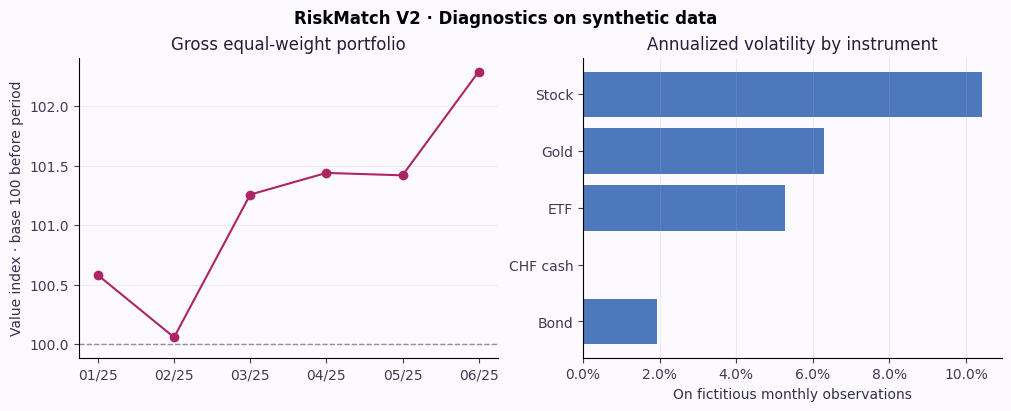

Figure: reports/01-socle/diagnostic-catalogue.png


In [5]:
from itertools import accumulate
from operator import mul
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

figure_path = Path("reports/01-socle/diagnostic-catalogue.png")
figure_path.parent.mkdir(parents=True, exist_ok=True)
pairs = [(day, reference[day]) for day in sorted(reference)]
days, returns = zip(*pairs)
wealth = [100 * value for value in accumulate((1 + value for value in returns), mul)]
metrics = {
    asset: describe(list(values.values()))["annualized_volatility"]
    for asset, values in panel.items()
}
names = {
    "DEMO_BOND": "Bond",
    "DEMO_CASH": "CHF cash",
    "DEMO_ETF": "ETF",
    "DEMO_GOLD": "Gold",
    "DEMO_STOCK": "Stock",
}
labels = [names.get(asset, asset) for asset in metrics]

with plt.rc_context({
    "figure.facecolor": "#fcfaff", "axes.facecolor": "#fcfaff",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": "#34304b", "axes.titlecolor": "#241e39",
    "font.family": "DejaVu Sans", "font.size": 10,
    "xtick.color": "#423955", "ytick.color": "#423955",
}):
    fig, (left, right) = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
    fig.suptitle("RiskMatch V2 · Diagnostics on synthetic data", fontweight="bold")
    left.axhline(100, color="#9989aa", linewidth=1, linestyle="--")
    left.plot([day.strftime("%m/%y") for day in days], wealth, color="#ae2465", marker="o")
    left.set(title="Gross equal-weight portfolio", ylabel="Value index · base 100 before period")
    left.grid(axis="y", alpha=.2)
    right.barh(labels, list(metrics.values()), color="#4d78bc")
    right.xaxis.set_major_formatter(PercentFormatter(xmax=1))
    right.set(title="Annualized volatility by instrument", xlabel="On fictitious monthly observations")
    right.grid(axis="x", alpha=.2)
    fig.savefig(figure_path, dpi=150)
    plt.show()
print(f"Figure: {figure_path}")

### 1.3 · Import market data for the first mandates

- [x] Checked in the project checklist

**Method and tools.** Read the versioned import manifest, check the SHA-256 digest when the private file is present and plot the common CHF month-ends.

**Result.** The original import supplies 257 usable monthly returns for each of 13 ETFs. Four missing months remain visible on the calendar. Section 8 reports the later FX extension.

[Study report](reports/01-3-import-marche/README.md)

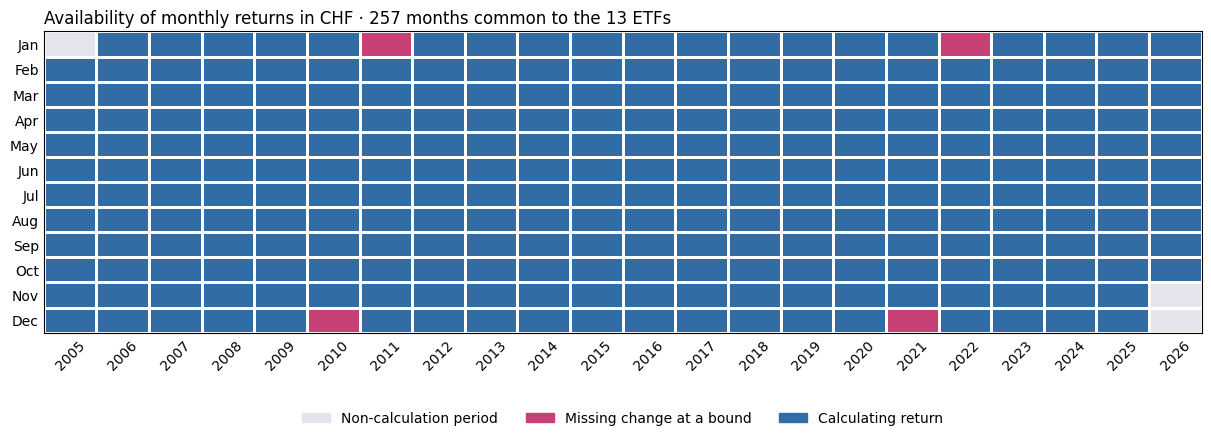

In [6]:
import hashlib
import json
import numpy as np
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch

folder = Path("reports/01-3-import-marche")
coverage = json.loads((folder / "coverage.json").read_text())
private = Path("data/local/1.3") / coverage["version"] / "returns.csv"
if private.exists():
    assert hashlib.sha256(private.read_bytes()).hexdigest() == coverage["catalogue_sha256"]
    assert len(load_catalogue(private)) == coverage["rows"]

months = {d[:7] for d in coverage["common_month_ends"]}
years = list(range(2005, 2027))
grid = np.zeros((12, len(years)), dtype=int)
for col, year in enumerate(years):
    for month in range(1, 13):
        label = f"{year}-{month:02}"
        if min(months) <= label <= max(months):
            grid[month - 1, col] = 2 if label in months else 1

colors = ["#e4e5ec", "#c74076", "#326ca4"]
fig, ax = plt.subplots(figsize=(12, 4.3), layout="constrained")
ax.pcolormesh(grid, cmap=ListedColormap(colors), norm=BoundaryNorm([-0.5, 0.5, 1.5, 2.5], 3),
              edgecolors="white", linewidth=0.9)
ax.invert_yaxis()
ax.set_xticks(np.arange(len(years)) + 0.5, years, rotation=45)
ax.set_yticks(np.arange(12) + 0.5, "Jan Feb Mar Apr May Jun Jul Aug Sep Oct Nov Dec".split())
ax.tick_params(length=0)
ax.set_title(f"Availability of monthly returns in CHF · {len(months)} months common to the 13 ETFs", loc="left")
labels = ["Non-calculation period", "Missing change at a bound", "Calculating return"]
ax.legend(handles=[Patch(color=c, label=l) for c, l in zip(colors, labels)],
          loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=3, frameon=False)
fig.savefig(folder / "couverture.png", dpi=150)
plt.show()

### 1.4 · Define the V2 benchmarks

- [x] Checked in the project checklist

**Method and tools.** Replay annually rebalanced and buy-and-hold 60/40 allocations and CHF cash on identical dates. Charge the same transaction-cost schedule and restart after a gap.

**Result.** The chart compares annualized compound return and volatility over three independent periods. The private-data path also checks the recorded results against a fresh replay.

[Study report](reports/01-4-references/README.md)

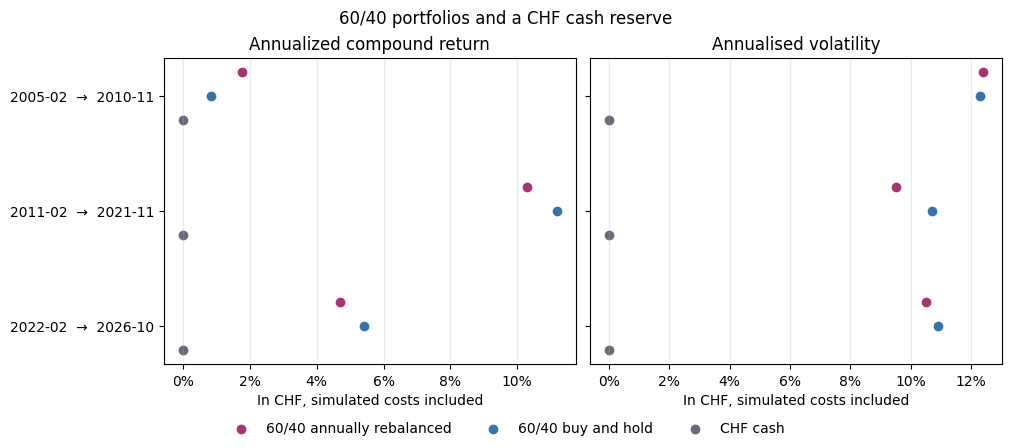

In [7]:
from datetime import date
from riskmatch_v2.reference import study

bench_dir = Path("reports/01-4-references")
bench = json.loads((bench_dir / "resultats.json").read_text())
parameters = Path("config/references-1.4.json")
assert hashlib.sha256(parameters.read_bytes()).hexdigest() == bench["config_sha256"]
if private.exists():
    history = instrument_panel(load_catalogue(private), date.fromisoformat(max(coverage["common_month_ends"])))
    recomputed, _ = study(history, json.loads(parameters.read_text()))
    assert recomputed == bench["periods"]

fig, axes = plt.subplots(1, 2, figsize=(10, 4.4), layout="constrained", sharey=True)
names = {"annual": "60/40 annually rebalanced", "hold": "60/40 buy and hold", "cash": "CHF cash"}
colors = ["#aa326e", "#3575ad", "#6a6a79"]
for ax, key, title in zip(axes, ("cagr", "volatility"), ("Annualized compound return", "Annualised volatility")):
    for offset, (mode, label) in enumerate(names.items()):
        series = [r for r in bench["periods"] if r["mode"] == mode]
        positions = np.arange(len(series)) + (offset - 1) * 0.21
        ax.scatter([r[key] for r in series], positions, label=label, color=colors[offset])
    ax.set_yticks(np.arange(len(series)), [f"{r['start'][:7]}  →  {r['end'][:7]}" for r in series])
    ax.set(title=title, xlabel="In CHF, simulated costs included")
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.grid(axis="x", alpha=0.25)
axes[0].invert_yaxis()
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=3, frameon=False)
fig.suptitle("60/40 portfolios and a CHF cash reserve")
fig.savefig(bench_dir / "comparaison.png", dpi=150)
plt.show()

### 1.5 · Map requirements to deliverables

- [x] Checked in the project checklist

**Method and tools.** Parse the numbered checklist and the requirements matrix. Compare their item sets with the notebook headings, sequence and recorded checkbox states.

**Result.** The cross-check below fails on an omitted, duplicate, misplaced or stale item. The table reports checked versus total items in each section.

[Study report](reports/01-5-exigences/README.md)

In [8]:
import re
from collections import Counter

checklist = Path("CHECKLIST.md").read_text()
tasks = dict((number, mark) for mark, number in
             re.findall(r"^- \[([ x])\] \*\*(\d+(?:\.\d+)?)\.?(?= )", checklist, re.M))
matrix = Path("reports/01-5-exigences/README.md").read_text()
covered = Counter()
for cell in re.findall(r"^\| ([0-9][0-9., –]*) \|", matrix, re.M):
    for interval in cell.split(", "):
        if "–" in interval:
            start, end = interval.split("–")
            section, first = map(int, start.split("."))
            last_section, last = map(int, end.split("."))
            assert section == last_section and first <= last
            covered.update(f"{section}.{i}" for i in range(first, last + 1))
        else:
            covered[interval] += 1
assert set(covered) == set(tasks), set(covered) ^ set(tasks)
assert all(n == 1 for n in covered.values())
items = re.findall(r"^- \[([ x])\] \*\*(\d+(?:\.\d+)?)\.?(?= )", checklist, re.M)
assert len(items) == len(tasks), "Duplicate checklist item"
sections = {int(k.split(".")[0]) for k in tasks if "." in k}
assert sections == set(range(1, 15))
notebook_cells = json.loads(Path("RiskMatch_V2.ipynb").read_text())["cells"]
notebook_items = []
active_section = "0"
for cell in notebook_cells:
    if cell["cell_type"] != "markdown":
        continue
    body = "".join(cell["source"])
    section_match = re.match(r"## (\d+)\. ", body)
    if section_match:
        active_section = section_match[1]
    item_match = re.match(r"### (\d+(?:\.\d+)?) · ", body)
    if item_match:
        item = item_match[1]
        assert item.split(".")[0] == active_section, item
        expected = "- [x] Checked" if tasks[item] == "x" else "- [ ] Open"
        assert f"{expected} in the project checklist" in body, item
        notebook_items.append(item)
assert notebook_items == list(tasks), "Notebook order or coverage differs from the checklist"
print(f"{len(covered)} checklist items each map to exactly one requirements entry.")
progress = []
for section, (title, assessment) in enumerate([('Project foundation and historical benchmarks', 'Verified'), ('Questionnaire and client mandate', 'Verified on theoretical cases'), ('Risk confirmation and loss capacity', 'Verified on theoretical cases'), ('Asset catalogue and dated eligibility', 'Verified for the dated catalogue'), ('Portfolio feasibility and allocation', 'Verified for the specified research cases'), ('Portfolio options, scores and blends', 'Partial'), ('Goals and cash-flow schedules', 'Verified research scenarios; limited common history'), ('Exposures, correlations and shocks', 'Verified for dated research scenarios'), ('Individual US stocks', 'Audited; full listing and settlement coverage open'), ('US Treasuries and commodities', 'Verified pricing, gold and execution tests; no approved customer trades'), ('Environmental preferences', 'Verified issuer exclusions and partial point-source intensity study'), ('Forecasts and signal validation', 'Executed; no forecast admitted to allocation'), ('Application, portfolio matching and monitoring', 'Verified local simulation on desktop and emulated mobile'), ('Final verification and delivery', 'Reproduced on two tapes; intraday feed remains open')], start=1):
    marks = [v for k, v in tasks.items() if k.startswith(f"{section}.")]
    progress.append((section, title, marks.count("x"), len(marks), assessment))
import pandas as pd
display(pd.DataFrame(progress, columns=["Section", "Workstream", "Checked", "Total", "Evidence status"]).set_index("Section"))


86 checklist items each map to exactly one requirements entry.


,Workstream,Checked,Total,Evidence status
Section,,,,
1,Project foundation and historical benchmarks,5,5,Verified
2,Questionnaire and client mandate,8,8,Verified on theoretical cases
3,Risk confirmation and loss capacity,4,4,Verified on theoretical cases
4,Asset catalogue and dated eligibility,9,9,Verified for the dated catalogue
5,Portfolio feasibility and allocation,8,8,Verified for the specified research cases
6,"Portfolio options, scores and blends",6,9,Partial
7,Goals and cash-flow schedules,4,4,Verified research scenarios; limited common hi...
8,"Exposures, correlations and shocks",4,4,Verified for dated research scenarios
9,Individual US stocks,3,4,Audited; full listing and settlement coverage ...


## 2. Questionnaire and client mandate

**Verified on theoretical cases.** 41 swipe and input cards. Comprehension gates the inference of risk-aversion bounds. Financial facts and preferences are recorded separately.

### 2.1 · Build the complete V2 questionnaire specification

- [x] Checked in the project checklist

**Method and tools.** Read the versioned JSON card bank into pandas. Group by family and inspect each card’s exact text and interpretation.

**Result.** All 41 unique cards appear in the table. Financial and preference inputs supplement the seven behavioural families.

[CARDS.md](reports/02-questionnaire/CARDS.md)

In [9]:
from riskmatch_v2.interview import BANK, CARDS, Interview, derive, route
from collections import Counter

intake_dir = Path("reports/02-questionnaire")
fixtures = json.loads((intake_dir / "cas.json").read_text())
intake_date = date.fromisoformat(fixtures["as_of"])

def synthetic_interview(choices):
    interview = Interview(intake_date)
    for key in CARDS:
        if key in route(interview.answers):
            interview.record(key, choices.get(key, "skip"))
    return interview

In [10]:
import pandas as pd
from IPython.display import display
cartes = pd.DataFrame(CARDS.values()).set_index("id")
assert cartes.index.is_unique and len(cartes) == 41
display(cartes.groupby("family").size().rename("Number of cards").to_frame())
with pd.option_context("display.max_rows", 45, "display.max_colwidth", 100):
    display(cartes[["family", "text", "effect"]].rename(columns={"family":"Family","text":"Question","effect":"Interpretation"}))

,Number of cards
family,
Blending,1
Certain outcome or gamble,5
Comprehension,2
Diversification,1
Environment,1
Exclusion,1
Exposures,1
Financial circumstances,4
Flexibility,2


,Family,Question,Interpretation
id,,,
C01,Comprehension,"In a fair coin toss, each side has a one-in-two chance. Can I still lose on this single toss?",Yes opens the trade-off questions. No or Skip opens C02.
C02,Comprehension,"After three wins in a row, can I still lose on a fourth, independent toss?",Yes unlocks the gambles. Otherwise φ stays undetermined.
T01,Stated tolerance,"If my expenses were already covered, I would accept large swings in the value of my investments.",Yes indicates greater stated comfort; No indicates less. Neither adds points.
T02,Stated tolerance,"Would a temporary loss of CHF 2,000 on CHF 10,000 change your answer?",Yes invites a review of T01. No retains the initial statement.
G00,Certain outcome or gamble,"Can you compare two hypothetical investments that each tie up CHF 1,000 for a year, assuming you...",Yes permits the gambles if the probabilities are understood. No or Skip leaves φ unbounded.
G01,Certain outcome or gamble,"If you invested CHF 1,000 for one year, would you prefer a guaranteed CHF 1,020 to an equal chan...",Right adds a lower bound; left adds an upper bound. Skipping adds neither.
G02,Certain outcome or gamble,"If you invested CHF 1,000 for one year, would you prefer a guaranteed CHF 1,000 to an equal chan...",Right adds a lower bound; left adds an upper bound. Skipping adds neither.
G03,Certain outcome or gamble,"If you invested CHF 1,000 for one year, would you prefer a guaranteed CHF 1,040 to an equal chan...",Right adds a lower bound; left adds an upper bound. Skipping adds neither.
G04,Certain outcome or gamble,These choices are inconsistent under the model. Do you confirm that these were the answers you i...,Yes retains the contradiction. No invites correction of the gambles. Neither adds a bound.


### 2.2 · Write the questions about financial circumstances

- [x] Checked in the project checklist

**Method and tools.** Inspect the F-series cards and the recorded financial facts. Use the dated withdrawals and confirmed contributions to derive a reserve before calculating the investable balance.

**Result.** The example protects CHF 15,000 from CHF 50,000 and leaves CHF 35,000 available for the investment sleeve.

[cas.json](reports/02-questionnaire/cas.json)

In [11]:
display(cartes.loc[cartes.index.str.startswith("F"), ["text", "effect"]])
session = synthetic_interview(fixtures["common"] | fixtures["cases"][0]["answers"])
first = session.confirm()
display(pd.DataFrame({key:first["portrait"]["liquidity"][key] for key in ("reserve_chf","investable_chf")}).T)

,text,effect
id,,
F01,"How much money do you have available today, in...",Keep both bounds before deducting the reserve.
F02,Until what date must this capital cover your e...,Include flows on this date when calculating th...
F03,What withdrawals and contributions do you expe...,Count only confirmed contributions. Protect co...
F04,"What size of financial loss, in CHF, would put...",Keep the CHF range separate from emotional com...
F05,"What amount do you want to reach, and by what ...","Keep the amount bounds, currency and date."


,low,high
reserve_chf,15000.0,15000.0
investable_chf,35000.0,35000.0


### 2.3 · Write the preference questions

- [x] Checked in the project checklist

**Method and tools.** Inspect P01–P10. Capture return and risk preferences, outside exposures, diversification, exclusions, environmental preferences, hedges and blending instructions.

**Result.** The output shows the requested information and its interpretation. A mandatory exclusion and a flexible preference have separate effects in the mandate.

[CARDS.md](reports/02-questionnaire/CARDS.md)

In [12]:
display(cartes.loc[cartes.index.str.startswith("P"), ["text", "effect"]])
display(first["portrait"]["preferences"])

,text,effect
id,,
P01,What annual return would you like on your CHF ...,Store the signed annual percentage range.
P02,How would you like to express your risk target?,Keep the request type and whether it applies t...
P03,What annual volatility ceiling would you accep...,Retain the respondent’s ceiling for confirmati...
P04,What range of annual volatility would you like...,Retain both bounds of the request.
P05,What exposures do you already have outside thi...,"Keep the type, scope and description of each e..."
P06,What diversification limits would you like to ...,Keep each rule and its priority. Suspend its u...
P07,Which securities or exposures would you like t...,Keep each rule and its priority. Suspend its u...
P08,Which environmental criteria would you like to...,Keep each rule and its priority. Suspend its u...
P09,Which risks would you like protection against?,Keep each rule and its priority. Suspend its u...


{'P06': [], 'P07': [], 'P08': [], 'P09': [], 'P10': []}

### 2.4 · Implement the interpretation rules for each card

- [x] Checked in the project checklist

**Method and tools.** Use the understood, comparable gambles to intersect lower and upper bounds on φ. Recompute the interval with each decisive answer removed.

**Result.** The example yields a lower bound near 2.67 and an upper bound near 4.44. The calculation below exposes the sensitivity to each answer.

[CARDS.md](reports/02-questionnaire/CARDS.md)

In [13]:
aversion_example = first["portrait"]["aversion"]
print("Lower and upper bounds on φ:", round(aversion_example["low"], 2), round(aversion_example["high"], 2))
display(pd.DataFrame(aversion_example["without"]).T)

Lower and upper bounds on φ: 2.67 4.44


,low,high,state
G01,0.888889,4.444444,bounded
G02,2.666667,None,one-sided
G03,2.666667,4.444444,bounded


### 2.5 · Save a versioned client mandate

- [x] Checked in the project checklist

**Method and tools.** Confirm a simulated interview, correct its dated withdrawal and confirm again. Compare the two versioned snapshots and their derived fields.

**Result.** Increasing the withdrawal to CHF 22,000 changes the reserve and investable balance, while leaving the gamble-derived bounds unchanged.

[interview.py](src/riskmatch_v2/interview.py)

In [14]:
session.record("F03", [fixtures["common"]["F03"][0] | {"low": 22000, "high": 22000}])
second = session.confirm()
assert (first["version"], second["version"]) == (1, 2)
assert first["portrait"]["aversion"] == second["portrait"]["aversion"]

display(pd.DataFrame([dict(version=v["version"], **{key:v["portrait"]["liquidity"][key] for key in ("reserve_chf","investable_chf")}) for v in (first,second)]).set_index("version"))

,reserve_chf,investable_chf
version,,
1,"{'low': 15000.0, 'high': 15000.0}","{'low': 35000.0, 'high': 35000.0}"
2,"{'low': 22000.0, 'high': 22000.0}","{'low': 28000.0, 'high': 28000.0}"


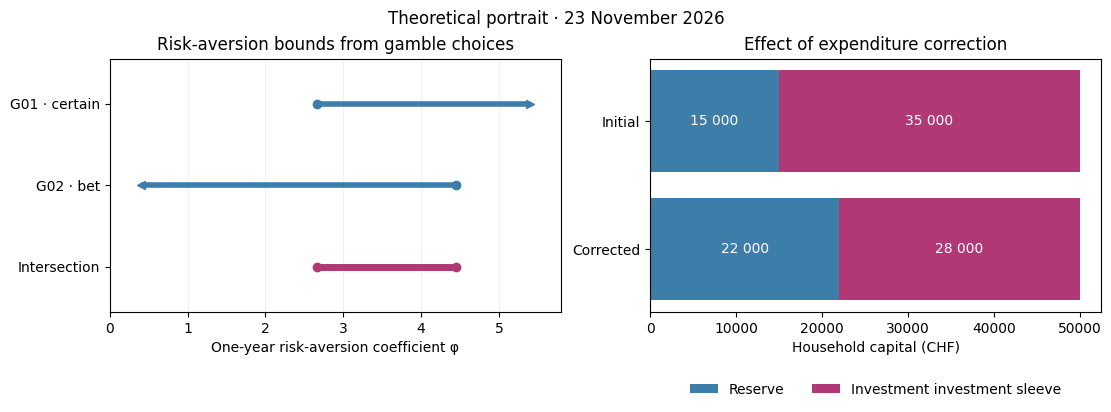

In [15]:
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
phi = first["portrait"]["aversion"]
lo, hi = phi["low"], phi["high"]
left.hlines(2, lo, 5.4, color="#3d7daa", lw=4)
left.plot([lo], [2], "o", color="#3d7daa")
left.plot([5.4], [2], ">", color="#3d7daa")
left.hlines(1, 0.4, hi, color="#3d7daa", lw=4)
left.plot([hi], [1], "o", color="#3d7daa")
left.plot([0.4], [1], "<", color="#3d7daa")
left.hlines(0, lo, hi, color="#af3875", lw=5)
left.plot([lo, hi], [0, 0], "o", color="#af3875")
left.set(yticks=[2, 1, 0], yticklabels=["G01 · certain", "G02 · bet", "Intersection"],
         ylim=(-0.55, 2.55), xlim=(0, 5.8), xlabel="One-year risk-aversion coefficient φ",
         title="Risk-aversion bounds from gamble choices")
left.grid(axis="x", alpha=.18)
for i, snap in enumerate([first, second]):
    budget = snap["portrait"]["liquidity"]
    reserve = budget["reserve_chf"]["high"]
    pocket = budget["investable_chf"]["low"]
    right.barh(i, reserve, color="#3d7daa", label="Reserve" if i == 0 else None)
    right.barh(i, pocket, left=reserve, color="#af3875", label="Investment investment sleeve" if i == 0 else None)
    for x, value in [(reserve/2, reserve), (reserve+pocket/2, pocket)]:
        right.text(x, i, f"{value:,.0f}".replace(",", " "), ha="center", va="center", color="white")
right.set(yticks=[0,1], yticklabels=["Initial", "Corrected"], xlabel="Household capital (CHF)",
          title="Effect of expenditure correction")
right.invert_yaxis()
right.legend(loc="upper center", bbox_to_anchor=(.5,-.23), ncol=2, frameon=False)
fig.suptitle("Theoretical portrait · 23 November 2026")
fig.savefig(intake_dir / "portraits.png", dpi=150)
plt.show()

### 2.6 · Specify the cards and supported gestures

- [x] Checked in the project checklist

**Method and tools.** Map swipe direction, arrow keys and accessible buttons to the same binary answer. Keep Skip distinct. Record monetary amounts in input fields.

**Result.** The example card below shows the two directional choices. The browser test covers short drags, cancellation, correction, keyboard input and emulated touch.

[parcours_navigateur.py](tests/parcours_navigateur.py)

In [16]:
example_card = CARDS["C01"]
print(example_card["text"])
display(pd.Series({"Swipe right / right arrow": example_card["options"]["yes"],
                   "Swipe left / left arrow": example_card["options"]["no"],
                   "Unsure / skip": "Records uncertainty without adding a bound."}, name="Recorded choice"))

In a fair coin toss, each side has a one-in-two chance. Can I still lose on this single toss?


Swipe right / right arrow                        Yes, I could still lose
Swipe left / left arrow                         No, a loss is impossible
Unsure / skip                Records uncertainty without adding a bound.
Name: Recorded choice, dtype: object

### 2.7 · Test the adaptive route independently of the interface

- [x] Checked in the project checklist

**Method and tools.** Replay the conditional routing with the seven published cases. Compare each observed aversion state with the expected state.

**Result.** The output lists the observed outcomes. These are deterministic scenario tests. Participant behaviour has not been measured.

[cas.json](reports/02-questionnaire/cas.json)

In [17]:
portraits = {}
for case in fixtures["cases"]:
    session = synthetic_interview(fixtures["common"] | case["answers"])
    portrait = session.confirm()["portrait"]
    assert portrait["aversion"]["state"] == case["phi"]
    portraits[case["name"]] = portrait
    print(case["name"], "·", case["phi"], "·", portrait["sale_motives"] or "no grounds for sale retained")

Invoice payable · bounded · ['liquidity to be checked in F03']
Disadvantages after decline · bounded · ['desired stability']
Anticipation of decline · bounded · ['market anticipation']
Unestablished understanding · insufficient · no grounds for sale retained
Contradictory choices · contradiction · no grounds for sale retained


Two frame inversions · one-sided · no grounds for sale retained
Passage and expenditure unknown · insufficient · no grounds for sale retained


### 2.8 · Adapt the behavioural and cognitive questions to V2

- [x] Checked in the project checklist

**Method and tools.** Inspect comprehension, stated tolerance, gambles, framing, loss responses, flexibility and monitoring separately. Examine the alternative explanations stored with each card.

**Result.** Only the eligible gambles contribute numerical aversion bounds. Loss-response cards distinguish liquidity, discomfort and expectations without assigning φ points.

[CARDS.md](reports/02-questionnaire/CARDS.md)

In [18]:
behavioural = cartes.loc[~cartes.index.str.startswith(("P", "F"))]
display(behavioural.groupby("family", sort=False).first()[["text", "rationale", "alternative"]])
assert behavioural["family"].nunique() == 7

,text,rationale,alternative
family,,,
Comprehension,"In a fair coin toss, each side has a one-in-tw...",Distinguishes the probability of an outcome fr...,The wording or swipe direction may have been m...
Stated tolerance,"If my expenses were already covered, I would a...",Separates stated comfort with volatility from ...,“Large” may suggest different amounts to diffe...
Certain outcome or gamble,Can you compare two hypothetical investments t...,Checks whether the certain payment and the gam...,Needing the money could explain a preference f...
Reference point,"When assessing a loss, is the amount you origi...",Identifies the respondent’s stated reference p...,A previous peak or a financial goal could also...
Response to a loss,Your investments have just fallen by 15%. Woul...,Distinguishes three possible reasons for selling.,"Cash needs, discomfort and market expectations..."
Flexibility,"If it took longer to reach your target amount,...",Distinguishes a firm deadline from a preferred...,The feasible delay depends on the goal.
Tracking,Would you like frequent updates on the value o...,Asks how often the respondent wants to check t...,Frequent checks may simply reflect curiosity.


## 3. Risk confirmation and loss capacity

**Verified on theoretical cases.** The client reviews the requested risk range, monetary losses and affordable loss before confirming the mandate.

### 3.1 · Define risk measurement conventions

- [x] Checked in the project checklist

**Method and tools.** Read the annual volatility bands and their measurement basis from the risk policy. Express bounds internally as decimal returns and display percentages.

**Result.** The five named bands start at 0%, 4%, 8%, 12% and 20%. A client can also request minimum risk, a custom cap or a custom band.

[risque.json](src/riskmatch_v2/questionnaire/risque.json)

In [19]:
from riskmatch_v2.risk_review import POLICY, CertifiedMaximum, assess, portrait_digest, request

bands = pd.DataFrame(POLICY["bands"]).set_index("label")[["low", "high"]].mul(100)
display(bands.rename(columns={"low": "From (%)", "high": "Below (%)"}).fillna("Open-ended"))

,From (%),Below (%)
label,,
Very cautious,0.0,4.0
Cautious,4.0,8.0
Moderate,8.0,12.0
Growth-oriented,12.0,20.0
Aggressive,20.0,Open-ended


### 3.2 · Present the risk decision to the client

- [x] Checked in the project checklist

**Method and tools.** Use the request and assessment functions to replay explicit choices. Display the client’s request, its basis, the accepted bounds and the resulting decision.

**Result.** The 40% cap permits lower risk. A target of 40% with a two-point margin requests 38–42%. The examples record what the client confirmed before any allocation is selected.

[cas.json](reports/03-portrait/cas.json)

In [20]:
risk_dir = Path("reports/03-portrait")
risk_results = {}
risk_cases = json.loads((risk_dir / "cas.json").read_text())
for example in risk_cases:
    # Same behavioural responses. Change only the stated facts or the explicit choice.
    answers = (fixtures["common"] | fixtures["cases"][0]["answers"]
               | {"F04": {"low": 15000, "high": 15000}} | example.get("answers", {}))
    snapshot = synthetic_interview(answers).confirm()
    choice = request(**example["request"])
    certificate = None
    if "max_demo" in example:
        certificate = CertifiedMaximum(example["max_demo"], "investment sleeve", snapshot["as_of"],
                                       snapshot["version"], "Example constructed · supposed maximum of 18%", portrait_digest(snapshot))
    result = assess(snapshot, choice, accept=example.get("accept", True), bills=example.get("bills","yes"),
                    comfort=example.get("comfort","yes"), certificate=certificate)
    risk_results[example["name"]] = result
    print(example["name"], "·", result["state"], "· feasibility:", result["feasibility"])

assert risk_results["Minimum risk"]["stresses"][0]["loss_chf"]["high"] == 3500
assert risk_results["Target of 40% ± 2 points"]["feasibility"] == "target out of range"
assert risk_results["40 per cent ceiling"]["feasibility"] == "to be tested"
assert not any(row["ranking_authorized"] for row in risk_results.values())
assert risk_results == json.loads((risk_dir / "resultats.json").read_text()), "Risk scenarios differ from the published results"
display(pd.DataFrame({name: record["choice"] for name, record in risk_results.items()}).T)

Minimum risk · confirmed for study · feasibility: to be tested
Free range 6–10% · confirmed for study · feasibility: to be tested
Ceiling of 35% · confirmed for study · feasibility: to be tested


40 per cent ceiling · confirmed for study · feasibility: to be tested
Target of 40% ± 2 points · target out of range · feasibility: target out of range
High target, intolerable drop · to be clarified · feasibility: to be tested
100% ceiling on the household · confirmed for study · feasibility: to be tested
Undecided customers · pending confirmation · feasibility: to be tested
Estimated bill of CHF 10,000–20,000 · to be clarified · feasibility: to be tested
All capital is protected · to be clarified · feasibility: no investment capital
Date of expenditure unknown · to be clarified · feasibility: to be tested


,mode,basis,low,high,high_exclusive,unit,period,currency,band
Minimum risk,minimum,investment sleeve,None,None,False,decimal,year,CHF,None
Free range 6–10%,target_band,investment sleeve,0.06,0.1,False,decimal,year,CHF,None
Ceiling of 35%,cap,investment sleeve,None,0.35,False,decimal,year,CHF,None
40 per cent ceiling,cap,investment sleeve,None,0.4,False,decimal,year,CHF,None
Target of 40% ± 2 points,target_band,investment sleeve,0.38,0.42,False,decimal,year,CHF,None
"High target, intolerable drop",target_band,investment sleeve,0.38,0.42,False,decimal,year,CHF,None
100% ceiling on the household,cap,household,None,1.0,False,decimal,year,CHF,None
Undecided customers,unknown,investment sleeve,None,None,False,decimal,year,CHF,None
"Estimated bill of CHF 10,000–20,000",minimum,investment sleeve,None,None,False,decimal,year,CHF,None
All capital is protected,minimum,investment sleeve,None,None,False,decimal,year,CHF,None


### 3.3 · Resolve conflicting answers

- [x] Checked in the project checklist

**Method and tools.** Compare the same illustrative 18% certified maximum with a cap and a target band. Also replay a client who reports discomfort with losses.

**Result.** The target can be ruled out under the example certificate; the cap still needs a feasibility test. The output preserves the original request and states the reason for clarification.

[test_risk_review.py](tests/test_risk_review.py)

In [21]:
conflict_cases = ["40 per cent ceiling", "Target of 40% ± 2 points", "High target, intolerable drop"]
display(pd.DataFrame({name: {field:risk_results[name][field] for field in ("state", "feasibility", "issues", "alternative")} for name in conflict_cases}).T)

,state,feasibility,issues,alternative
40 per cent ceiling,confirmed for study,to be tested,[],None
Target of 40% ± 2 points,target out of range,target out of range,[],"{'choice': {'mode': 'minimum', 'basis': 'inves..."
"High target, intolerable drop",to be clarified,to be tested,[Scenarios · acceptance of the decrease to be ...,"{'choice': {'mode': 'minimum', 'basis': 'inves..."


### 3.4 · Test the effects of the reserve and the risk measurement basis

- [x] Checked in the project checklist

**Method and tools.** Apply the same loss to the investment sleeve and express it against total household capital. Recalculate when a bill is uncertain, all capital is protected or a payment date is missing.

**Result.** A 10% loss on CHF 35,000 is CHF 3,500, or 7% of the original CHF 50,000. The chart and case table show how the denominator and reserve affect the interpretation.

[Study report](reports/03-portrait/README.md)

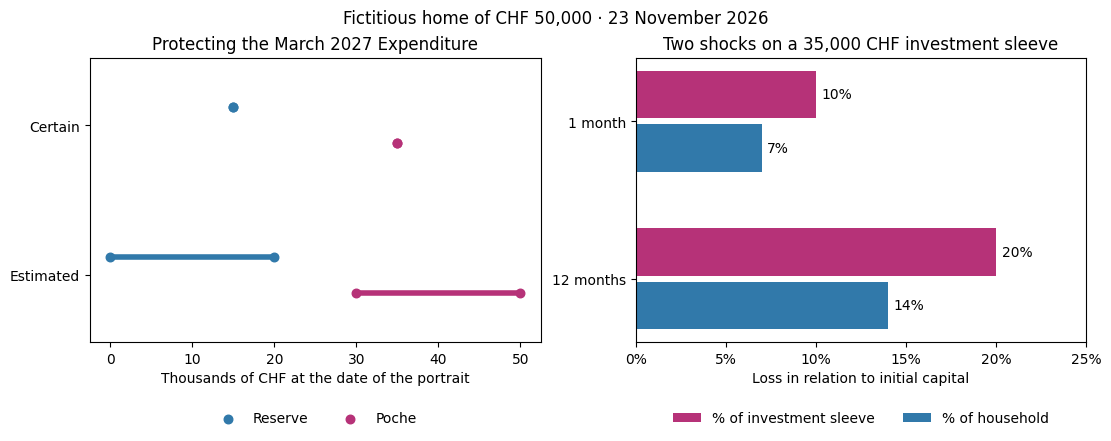

In [22]:
fixed = risk_results["Minimum risk"]
estimated = risk_results["Estimated bill of CHF 10,000–20,000"]
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.3), layout="constrained")
for y, (label, row) in enumerate([("Expenditure certain", fixed), ("Estimated expenditure", estimated)]):
    for offset, key, color in [(-0.12, "reserve_chf", "#3179aa"), (0.12, "investable_chf", "#b63278")]:
        v = row[key]
        ypos = y + offset
        left.plot([v["low"]/1000, v["high"]/1000], [ypos,ypos], color=color, lw=4)
        left.scatter([v["low"]/1000, v["high"]/1000], [ypos,ypos], s=38, color=color,
                     label=("Reserve" if key == "reserve_chf" else "Poche") if y == 0 else None)
left.set(yticks=[0,1], yticklabels=["Certain","Estimated"], ylim=(-0.45,1.45),
         xlabel="Thousands of CHF at the date of the portrait", title="Protecting the March 2027 Expenditure")
left.invert_yaxis()
left.legend(loc="upper center", bbox_to_anchor=(0.5,-0.20), ncol=2, frameon=False)
y = np.arange(len(fixed["stresses"]))
for offset, key, color, label in [(-0.17,"pocket_fraction","#b63278","% of investment sleeve"),(0.17,"household_fraction","#3179aa","% of household")]:
    vals = [s[key]["low"] if key=="household_fraction" else s[key] for s in fixed["stresses"]]
    bars = right.barh(y+offset, vals, height=0.30, color=color, label=label)
    right.bar_label(bars, labels=[f"{v:.0%}" for v in vals], padding=4)
right.set(yticks=y, yticklabels=["1 month","12 months"], xlim=(0,.25),
          xlabel="Loss in relation to initial capital", title="Two shocks on a 35,000 CHF investment sleeve")
right.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
right.invert_yaxis()
right.legend(loc="upper center", bbox_to_anchor=(0.5,-0.20), ncol=2,frameon=False)
fig.suptitle("Fictitious home of CHF 50,000 · 23 November 2026")
fig.savefig(risk_dir / "reserve-et-pertes.png", dpi=150)
plt.show()

In [23]:
display(pd.DataFrame([{"Scenario":name, "Decision":r["state"], "Feasibility at this stage":r["feasibility"],
                       "Reserve CHF":r["reserve_chf"], "investment sleeve CHF":r["investable_chf"]}
                      for name,r in risk_results.items()]).set_index("Scenario"))

,Decision,Feasibility at this stage,Reserve CHF,investment sleeve CHF
Scenario,,,,
Minimum risk,confirmed for study,to be tested,"{'low': 15000.0, 'high': 15000.0}","{'low': 35000.0, 'high': 35000.0}"
Free range 6–10%,confirmed for study,to be tested,"{'low': 15000.0, 'high': 15000.0}","{'low': 35000.0, 'high': 35000.0}"
Ceiling of 35%,confirmed for study,to be tested,"{'low': 15000.0, 'high': 15000.0}","{'low': 35000.0, 'high': 35000.0}"
40 per cent ceiling,confirmed for study,to be tested,"{'low': 15000.0, 'high': 15000.0}","{'low': 35000.0, 'high': 35000.0}"
Target of 40% ± 2 points,target out of range,target out of range,"{'low': 15000.0, 'high': 15000.0}","{'low': 35000.0, 'high': 35000.0}"
"High target, intolerable drop",to be clarified,to be tested,"{'low': 15000.0, 'high': 15000.0}","{'low': 35000.0, 'high': 35000.0}"
100% ceiling on the household,confirmed for study,to be tested,"{'low': 15000.0, 'high': 15000.0}","{'low': 35000.0, 'high': 35000.0}"
Undecided customers,pending confirmation,to be tested,"{'low': 15000.0, 'high': 15000.0}","{'low': 35000.0, 'high': 35000.0}"
"Estimated bill of CHF 10,000–20,000",to be clarified,to be tested,"{'low': 0.0, 'high': 20000.0}","{'low': 30000.0, 'high': 50000.0}"


## 4. Asset catalogue and dated eligibility

**Verified for the dated catalogue.** The catalogue distinguishes historical coverage, research eligibility and dated account access.

### 4.1 · Define the instrument-level data schema

- [x] Checked in the project checklist

**Method and tools.** Read the public Arrow schema catalogue and the dated instrument inventory. Inspect identity, observation, cash-flow and admission fields independently.

**Result.** The schema excerpt and counts show what the catalogue stores before any historical or eligibility filter is applied.

[schemas.json](reports/04-catalogue/schemas.json)

In [24]:
from pathlib import Path
import json
import matplotlib.pyplot as plt

library_dir = Path("reports/04-catalogue")
market = json.loads((library_dir / "resultats.json").read_text())
schemas = json.loads((library_dir / "schemas.json").read_text())
print(schemas["instruments"])
display(pd.Series(market["inventory"], name="Inventory records"))

id: string
symbol: string
name: string
role: string
asset_class: string
issuer: string
exchange: string
currency: string
calendar: string
exposure: string
source: string
first_seen: string
last_seen: string
entry: string
exit: string
available: string


action                14136
autre_CRSP            13285
obligation_directe       65
fonds_actions            10
macro                     3
fonds_tresor              2
vehicule_or               1
Spot oil                  1
U.S. Treasury Rate        1
change                    1
cash                      1
internal reference        1
Name: Inventory records, dtype: int64

### 4.2 · Clean and align market data

- [x] Checked in the project checklist

**Method and tools.** Reconcile prices, dividends and CHF conversion. Multiply local and FX growth factors and check adjustments on common dates.

**Result.** The worked FX case turns a 4% local gain into a 6.4% CHF loss. The dividend reconciliation counts distinguish matched observations from differences above ten basis points.

[Study report](reports/04-catalogue/README.md)

In [25]:
from riskmatch_v2.library.controls import chf_return
converted = chf_return(.04, .90, .81)
assert abs(converted + .064) < 1e-10
print(f"CHF return in the worked example: {converted:.2%}")
display(pd.Series(market["dividend_audit"], name="Dividend reconciliation count"))

CHF return in the worked example: -6.40%


RAPPROCHE                1387
ECART_SUPERIEUR_10_PB       2
Name: Dividend reconciliation count, dtype: int64

### 4.3 · Build one-, three-, five- and ten-year instrument profiles

- [x] Checked in the project checklist

**Method and tools.** Build one-, three-, five- and ten-year profiles from monthly data. Compare counts for complete observations and compound-return calculations.

**Result.** The original catalogue reports the counts below. Section 8 separately shows the broader universe’s coverage after supplementary ECB exchange rates.

[Study report](reports/04-catalogue/README.md)

In [26]:
stocks = market["stock_window_summary"]
funds = market["fund_window_summary"]
assert sum(r["sheets"] for r in stocks + funds) == market["stock_sheets"] + market["fund_sheets"]
assert sum(market["inventory"].values()) == market["eligibility"]["total"]
mix = market["overlap"]
parts = [100 * mix[k] for k in ("direct", "via_spy", "via_xlk")]
assert abs(sum(parts) - 100 * mix["total"]) < 1e-9
print("Window - Complete CHF Share Sheets - Computable Composite Growth - Months usable by fund")
for a, f in zip(stocks, funds, strict=True):
    print(f"{a['years']:2} years {a['complete']:>5} / {a['sheets']}              | {a['compound']:>5}                         | {f['median_observations']:.0f} / {a['years'] * 12}")
display(pd.DataFrame(stocks).set_index("years"))
display(pd.DataFrame(funds).set_index("years"))

Window - Complete CHF Share Sheets - Computable Composite Growth - Months usable by fund
 1 years 13105 / 15171              | 13676                         | 12 / 12
 3 years  8885 / 15171              | 10208                         | 36 / 36
 5 years  3188 / 15171              |  7645                         | 58 / 60
10 years   596 / 15171              |  4424                         | 118 / 120


,sheets,complete,compound,median_observations
years,,,,
1,15171,13105,13676,12.0
3,15171,8885,10208,36.0
5,15171,3188,7645,58.0
10,15171,596,4424,61.0


,sheets,complete,compound,median_observations
years,,,,
1,13,13,13,12.0
3,13,13,13,36.0
5,13,0,13,58.0
10,13,0,13,118.0


### 4.4 · Determine eligibility at each decision date

- [x] Checked in the project checklist

**Method and tools.** Apply dated price, FX, tradability, account and execution checks before admitting an instrument for an order. Group the decisions by asset class.

**Result.** The account register reviewed 27,507 entries and admitted none on the mandate date. Section 5 separately tests research feasibility.

[Study report](reports/04-catalogue/README.md)

In [27]:
display(pd.DataFrame(market["eligibility"]["by_class"]).T.rename(columns={"size": "Examined", "sum": "Eligible for orders"}))

,Examined,Eligible for orders
action,14136,0
autre_CRSP,13285,0
cash,1,0
change,1,0
fonds_actions,10,0
fonds_tresor,2,0
macro,3,0
obligation_directe,65,0
Spot oil,1,0
internal reference,1,0


### 4.5 · Build two point-in-time views

- [x] Checked in the project checklist

**Method and tools.** Inspect the dated AAPL identity and compare recorded historical activity, information availability and account eligibility.

**Result.** An active historical record can still have been unavailable at the historical decision date. The example exposes both flags and the later eligibility decision.

[controls.py](src/riskmatch_v2/library/controls.py)

In [28]:
display(pd.Series(market["eligibility"]["example"], name="Dated identity and admission checks"))

ticker                                                               AAPL
recorded_active_2025                                                 True
known_in_2025                                                       False
eligible_2026                                                       False
reasons_2026            [NEGOCIABILITE, ACCES_COMPTE, LOT, REGLEMENT, ...
Name: Dated identity and admission checks, dtype: object

### 4.6 · Document applicable methods for each asset class

- [x] Checked in the project checklist

**Method and tools.** Match each asset class to the quantities supported by its data. Read the published methods matrix, including the missing inputs for each class.

**Result.** The matrix identifies which classes support return histories, holdings look-through, interest-rate measures and factor-only analysis.

[METHODS.md](reports/04-catalogue/METHODS.md)

In [29]:
from IPython.display import Markdown
methods = Path("reports/04-catalogue/METHODS.md").read_text()
for block in methods.split("\n\n"):
    if block.lstrip().startswith("|"):
        display(Markdown(block))

| Class and support | Calculation and unit | Perimeter or data to be obtained |
|---|---|---|
| US common stocks · CRSP | PERMNO identity at date, issuer and place classification, volumes and distributions reported, total local monthly return and in CHF. Four windows, risk of decline and dispersion. | End specific to the title, not more than December 2025. For daily checks and optimization over 504/756 sessions, get daily returns, dates, distributions, radiations and stable identifiers. |
| US share funds · SPY and nine sectors | Adjusted daily series, monthly measurements by fund, Pearson/Spearman and covariance in CHF. Weight of underlying holdings, issuers, sectors and currencies on published dates. | SPY sectors are assigned when an identifier returns to a single sector classification on the same day. Residual lines retained. Current positions do not rebuild an old composition. |
| Treasury Funds · IEF/TLT | Same sheets and correlations. Weight of identified US Treasuries and sum of declared weight × duration (years) in each fund. | Partial sensitivity of the documented investment sleeve. An estimate of convexity or a detailed curve shock requires flows and curves to date. |
| Direct US Treasury holdings | ISIN identifier, target price, coupon in%, maturity, duration published in the fund positions. | An observation does not estimate a total historical return, variance or maximum decline. Get full prices, coupons accrued and paid, dates and calendar, lots and executable quotes. |
| Gold · GLD | Priced vehicle return, volatility, correlations and decrease in CHF on the same windows as other funds. | Accurate composition on the date not validated. Avoid assigning an issuer to the full value. |
| WTI spot and US 10-year rate | FRED values and dates in USD/bar and% of nominal. Selection of available values at a date. | Series of factors. The spot can be negative and a rate change is measured in base points. For future investment, get the contract chain, rollover and collateral. |
| Macro, FX and cash CHF | ALFRED versions of three indicators, change CHF/USD and convert values. Reference cash rated at 0% under the assumption of 1.4. | Hours of first publication sometimes unknown. The net remuneration and availability of the client balance require the terms of the account. |
| Mixtures and comparison | Symmetric matrix on common dates, issuing attribution by weight of portfolio, root of variance available via covariance, 60/40 net according to 1.4. | Ranking of strategies, optimized weights and estimation of future returns at the next steps. The hypothetical costs of the comparison differ from a broker quote. |

| Question | Product of the vintage |
|---|---|
| What instrument, what classification, what source, what date? | `instruments.parquet`, `identifiers.parquet`, `sources.parquet`, `schemas.json`, `manifest.json` |
| What session, what movement, what hole? | `prices.parquet`, `fx.parquet`, `events.parquet`, `dividend_audit.parquet`, `stock_months.parquet`, `stock_returns.parquet`, `stock_events.parquet`, `stock_quarantine.parquet` |
| What record or correlation? | `fund_sheets.parquet`, `stock_sheets.parquet`, `fonds_*a_*.parquet`, `covariance_coverage.parquet`, `universe_covariance.npz` |
| What would we have known or could have used? | `economic_calendar.parquet`, `macro_historique.parquet`, `macro_decision.parquet`, `replay_2025.parquet`, `decision.parquet` |
| What weight is held indirectly? | `holdings.parquet`, `concentration_*.parquet`, `fund_bond_sensitivity.parquet` |

### 4.7 · Test the catalogue with defective data

- [x] Checked in the project checklist

**Method and tools.** Run the synthetic catalogue regression cases covering missing prices, identifier reuse, distributions, stale data, split adjustments, point-in-time revisions and shared issuers.

**Result.** The executable test summary below reports the number of checks and fails the notebook if any case fails.

[test_library.py](tests/test_library.py)

In [30]:
import io
import unittest
suite = unittest.defaultTestLoader.discover("tests", pattern="test_library.py")
check = unittest.TextTestRunner(stream=io.StringIO()).run(suite)
assert check.wasSuccessful(), check.errors + check.failures
print(f"Catalogue regression tests: {check.testsRun - len(check.skipped)} passed, {len(check.skipped)} skipped.")
if check.skipped:
    print("Install the catalogue dependencies to run the skipped checks.")

Catalogue regression tests: 7 passed, 0 skipped.


### 4.8 · Verify when each source becomes available

- [x] Checked in the project checklist

**Method and tools.** Compare the two dated economic-calendar views by series. Use availability time when selecting macro releases and revisions.

**Result.** The historical and later decision views contain different observation counts. An unavailable series has no usable observations in that view.

[Study report](reports/04-catalogue/README.md)

In [31]:
display(pd.DataFrame(market["timing"]).fillna(0).astype(int).rename(columns={"historique":"Historical view", "decision":"Decision view"}))

,Historical view,Decision view
CPIAUCSL,309,321
UNRATE,309,321
INDPRO,308,321
DGS10,0,16928
DCOILWTICO,0,10664


### 4.9 · Reconstruct fund exposures as of the mandate date

- [x] Checked in the project checklist

**Method and tools.** Add the direct position in Apple to its indirect weights through SPY and XLK. Retain the uncovered share of fund holdings separately.

**Result.** The test portfolio has 29.68% combined Apple exposure. Counting the three holdings as independent exposures would understate its concentration.

[Study report](reports/04-catalogue/README.md)

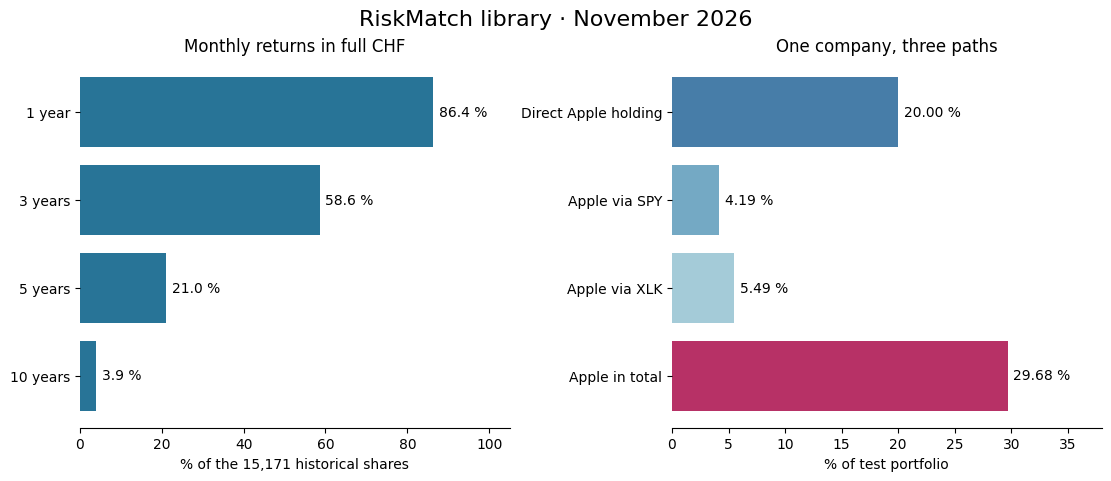

direct                   0.2
via_spy             0.041886
via_xlk               0.0549
total               0.296786
unassigned_net      0.001111
unassigned_gross    0.001214
hard_exclusion      excluded
Name: Look-through attribution, dtype: object

In [32]:
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.7), layout="constrained")
windows = [f"{r['years']} year" if r['years'] == 1 else f"{r['years']} years" for r in stocks]
percent = [100 * r['complete'] / r['sheets'] for r in stocks]
bars = left.barh(windows, percent, color="#287497")
left.invert_yaxis()
left.bar_label(bars, labels=[f"{x:.1f} %" for x in percent], padding=4)
left.set(xlim=(0, 105), xlabel="% of the 15,171 historical shares", title="Monthly returns in full CHF")
labels = ["Direct Apple holding", "Apple via SPY", "Apple via XLK", "Apple in total"]
values = parts + [sum(parts)]
bars = right.barh(labels, values, color=["#477da8", "#74a9c4", "#a4cbd8", "#b73166"])
right.invert_yaxis()
right.bar_label(bars, labels=[f"{x:.2f} %" for x in values], padding=4)
right.set(xlim=(0, 38), xlabel="% of test portfolio", title="One company, three paths")
for axis in (left, right):
    axis.spines[["top","right","left"]].set_visible(False)
    axis.grid(False)
fig.suptitle("RiskMatch library · November 2026", fontsize=16)
fig.savefig(library_dir / "couverture-et-expositions.png", dpi=160, bbox_inches="tight")
plt.show()
display(pd.Series(market["overlap"], name="Look-through attribution"))

## 5. Portfolio feasibility and allocation

**Verified for the specified research cases.** The engine estimates the highest net return under a volatility cap or band, accounts for the reserve and reports feasibility. The 13-ETF study is the controlled reference.

**Research question.** What estimated annual net return can the model obtain for an investment sleeve in CHF under a volatility ceiling, or in a specific band? The following experiments concern a fictitious customer with CHF 50,000, CHF 15,000 reserve and CHF 35,000 invested. Market results are historical. The actual decision register is checked separately at the end.

[Reproducible report](reports/05-faisabilite/README.md) · [Assumptions](config/faisabilite-5.json)

The examples listed below reproduce the initial calculation on ETFs. The end of this section presents the efficient frontier recalculated over all eligible instruments and used in section 6.

### 5.1 · Prepare allocation inputs

- [x] Checked in the project checklist

**Method and tools.** Inspect the estimation window, eligible returns, covariance diagnostics and cost assumptions. Keep CHF cash outside the risky-asset covariance matrix.

**Result.** The results below identify the input set for the controlled ETF case. The full-universe comparison follows item 5.8.

[Study report](reports/05-faisabilite/README.md)

Entries are daily returns in CHF, annualized over 252 sessions. The average of each title is halved towards the transverse median. The universe of 13 backgrounds is tested on 504 and 756 sessions. For the factor model, SPY, IEF and GLD explain a common component, to which is added a residual risk of its own. Three subsequent blocks of 63 sessions assess the realized risk of an equal-weight control portfolio. The observations are retrospective.

In [33]:
section5 = Path("reports/05-faisabilite")
f = json.loads((section5/"resultats.json").read_text())
cases = pd.DataFrame(f["cases"]).T
v = pd.DataFrame(f["validation"])
display(v.groupby(["window","method"]).agg(séances_communes=("train_common","min"), erreur_absolue_pp=("error",lambda a:100*a.abs().mean())))
print("Main Window Sessions", f["common"], "/", f["window"], "· minimum own value",round(f["min_eigen"],6))

séances_communes  erreur_absolue_pp
window method                                         
504    LedoitWolf               496           4.286156
       empirical                496           4.528798
       factor                   496           4.178799
756    LedoitWolf               744           3.170562
       empirical                744           3.324087
       factor                   744           3.001334

Main Window Sessions 496 / 504 · minimum own value 0.00243


### 5.2 · Implement the efficient frontier

- [x] Checked in the project checklist

**Method and tools.** Maximize estimated net return at each volatility cap. Plot the resulting risk and return and inspect the 12% case, including its cost and cash balance.

**Result.** The frontier shows which caps bind. With private data installed, the next cell also recalculates the example’s individual weights.

[Study report](reports/05-faisabilite/README.md)

The simulations limit each fund to 60% of the investment sleeve and the total invested to 90%. The objective function reduces the annualized proportional transaction costs over the one-year horizon. The household reserve remains out of optimisation. Each item is recalculated after resolution, including cash flow and procurement financing.

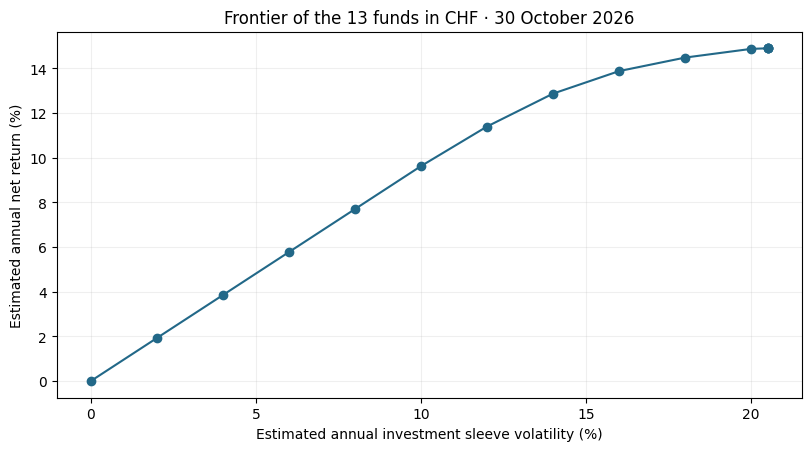

,risk,net,fee,cash,gap
cap 0.08,8.0000,7.6996,0.0717,28.2748,0.0
cap 0.12,12.0000,11.3966,0.0900,9.9100,0.0
cap 0.4,20.5018,14.8974,0.0900,9.9100,0.0


In [34]:
points = cases.loc[cases.index.str.startswith("cap")].copy()
fig, ax = plt.subplots(figsize=(8,4.4), layout="constrained")
ax.plot(100*points.risk.astype(float),100*points.net.astype(float),marker="o",color="#226888")
ax.set(xlabel="Estimated annual investment sleeve volatility (%)",ylabel="Estimated annual net return (%)",
       title="Frontier of the 13 funds in CHF · 30 October 2026")
ax.grid(alpha=.2)
fig.savefig(section5/"frontiere.png",dpi=160)
plt.show()
display(points.loc[["cap 0.08","cap 0.12","cap 0.4"], ["risk","net","fee","cash","gap"]].astype(float).mul(100).round(4))

**Direct calculation with the V2 engine.** With the private catalogue, this cell reestimates moments in CHF, solves the 12% ceiling, displays weights and protects the 15,000 CHF reserve. On a public copy, the aggregate result of the previous cell and the recorded outputs make it possible to reread the decision. The analytical case of 5.4 can be executed independently of market data.

In [35]:
from importlib.util import find_spec
from pathlib import Path
engine_available = all(find_spec(mod) for mod in ("cvxpy","sklearn","duckdb","exchange_calendars","pyarrow"))
archive = Path("data/local/5") / f["version"] / f["snapshot"]
if engine_available and (archive/"etf_sessions.parquet").is_file():
    from riskmatch_v2.feasibility.inputs import estimate
    from riskmatch_v2.feasibility.study import market as market_problem
    from riskmatch_v2.feasibility.engine import Frontier
    dates_chf = pd.read_parquet(archive/"etf_sessions.parquet")
    mu_chf, racine = estimate(dates_chf)
    config5 = json.loads(Path("config/faisabilite-5.json").read_text())
    modele = market_problem(dates_chf.columns, mu_chf, racine, config5)
    essai = Frontier(modele).solve(high=.12)
    controle = modele.evaluate(essai["candidate"]["weights"], high=.12)
    assert controle["valid"] and abs(controle["net"]-f["cases"]["cap 0.12"]["net"]) < 1e-6
    poche = f["lease"]["pocket"]
    poids = pd.Series(controle["weights"], index=modele.names)
    vue = poids[poids>.0001].sort_values(ascending=False).rename("Weight")
    display(pd.DataFrame({"Weight (%)":100*vue, "Theoretical amount in CHF":poche*vue}).round(2))
    print(f"Cash in the investment sleeve {poche*controle['cash']:,.2f} CHF · fees {poche*controle['fee']:,.2f} CHF · External reserve {f['lease']['reserve']:,} CHF")
else:
    print("Aggregated results above. Recalculation by security uses the private private catalogue and the catalogue and feasibility dependencies.")

,Weight (%),Theoretical amount in CHF
GLD,25.87,9055.77
XLE,20.60,7209.87
XLV,16.26,5691.47
XLK,15.46,5412.18
XLP,7.46,2611.68
IEF,4.34,1519.04


Cash in the investment sleeve 3,468.50 CHF · fees 31.50 CHF · External reserve 15,000 CHF


### 5.3 · Handle lower volatility bounds and unreachable requests

- [x] Checked in the project checklist

**Method and tools.** Check the maximum reachable volatility and distinguish a minimum-risk request, a cap and a band with a positive lower bound.

**Result.** The table reports feasibility and the supporting proof for the 35%, 40% and 100% test cases. A high cap and an equally high target band need different tests.

[Study report](reports/05-faisabilite/README.md)

Maximum volatility on the demonstration mandate is calculated at the tops of the polytope. For a difficult slice, the engine checks candidates between eligible portfolios, subdivides weights and maintains an overall performance limit. A high ceiling allows a more conservative solution. A slice whose bottom exceeds the maximum is impossible under these assumptions.

In [36]:
print("Maximum on",f["diagnostics"]["vertices"],"vertices:",f'{f["diagnostics"]["max_risk"]:.2%}')
display(cases.loc[["minimum","cap 0.35","cap 0.4","band 0.38–0.42","cap 1","band 0.99–1.01"],["status","risk","net","proof"]])

Maximum on 170 vertices: 22.18%


,status,risk,net,proof
minimum,optimal,0.0,0.0,lower limit of risk per hyperplane
cap 0.35,optimal,0.205018,0.148974,global linear bound
cap 0.4,optimal,0.205018,0.148974,global linear bound
band 0.38–0.42,impossible,None,None,triangular limit on volatility
cap 1,optimal,0.205018,0.148974,global linear bound
band 0.99–1.01,impossible,None,None,triangular limit on volatility


### 5.4 · Test the optimizer

- [x] Checked in the project checklist

**Method and tools.** Compare the numerical optimizer with a two-asset analytical solution and an independently searched grid. Run the additional solver checks when dependencies are present.

**Result.** The assertions bound the deviation from the analytical solution. The displayed basis-point difference measures the grid comparison.

[Study report](reports/05-faisabilite/README.md)

In the fictitious case of two fully invested assets, their expected returns are 6% and 2% and their perfectly correlated risks are 2% and 20%. To reach 10 per cent with the best return, the weight of the second active must be (10−2)/(20−2), i.e. 4/9. On SPY and IEF, a second reference explores a 0.1 point spaced weight grid.

In [37]:
manual = .06*(1-4/9)+.02*4/9
assert abs(f["oracle"]["binding lower volatility bound"]["net"]-manual)<=.0001
print(f"Analytical performance {manual:.4%} · SPY–IEF solver/grid difference {10000*f['diagnostics']['grid_gap']:.3f} bp")
print("Maximum Residue of ETF Solutions",max(x["residual"] for x in f["cases"].values() if x["residual"] is not None))

Analytical performance 4.2222% · SPY–IEF solver/grid difference 0.183 bp
Maximum Residue of ETF Solutions 1.2765000168002416e-10


In [38]:
if engine_available:
    from riskmatch_v2.feasibility.study import oracle_cases
    comparaisons, _ = oracle_cases()
    assert abs(comparaisons["binding lower volatility bound"]["net"] - manual) <= .0001
    display(pd.DataFrame(comparaisons).T[["status","net","gap"]])
else:
    print("To replay the two fictitious assets with CLARABEL, install catalog options and makeability.")

,status,net,gap
under ceiling,optimal,0.06,0.0
binding lower volatility bound,optimal,0.042222,0.000043
interruption,candidate,0.042222,0.017778
impossible,impossible,None,None


### 5.5 · Measure computation across the full library

- [x] Checked in the project checklist

**Method and tools.** Read instrument counts, repeated runtimes and peak memory for the load tests. Compare screened, excluded and modelled instruments.

**Result.** The table reports measured computation costs. The public summary separates the historical load test from the zero-admission account decision.

[Study report](reports/05-faisabilite/README.md)

The measurement separates the current intake from the historical load test. All U.S. common shares active in the December 2025 registry are reviewed. Each series must provide at least 252 observations usable with the three factors in the 504 sessions. Identifiers submitted, reasons for failure and title-specific comments are archived locally. Time includes solver and independent control, after data preparation.

In [39]:
display(pd.DataFrame(f["performance"])[["n","repetitions","median","worst","peak_rss_mib"]].rename(
 columns={"n":"Instruments submitted","median":"Median (s)","worst":"Maximum (s)","peak_rss_mib":"Peak process memory (MiB)"}))
print("Historical universe examined",f["broad"]["seen"],"· retained",f["broad"]["modeled"],"· rejected",f["broad"]["excluded"])
print("Account Decision",f["live"]["date"],"· examined",f["live"]["examined"],"· eligible",f["live"]["count"])

,Instruments submitted,repetitions,Median (s),Maximum (s),Peak process memory (MiB)
0,3,3,0.007316,0.007346,675.000000
1,13,3,0.007866,0.007917,674.968750
2,3676,3,56.534608,56.535399,696.359375
3,0,3,0.000118,0.000191,696.359375


Historical universe examined 3837 · retained 3676 · rejected 161
Account Decision 2026-11-23T14:00:00Z · examined 27507 · eligible 0


### 5.6 · Measure allocation stability

- [x] Checked in the project checklist

**Method and tools.** Perturb the estimation data and compare each revised weight vector with the baseline using half the sum of absolute weight changes.

**Result.** The figure quantifies allocation turnover under the tested perturbations. This is a sensitivity result for the specified window.

[Study report](reports/05-faisabilite/README.md)

The 12-per-cent mandate is recalculated with other windows, costs and estimates, followed by ten resamplings in synchronised blocks of 21 sessions. The half-sum of the absolute weight deviations measures the reallocation of the investment sleeve. A conservative variant is chosen from among the candidates after checking the ceiling in each of the models tested.

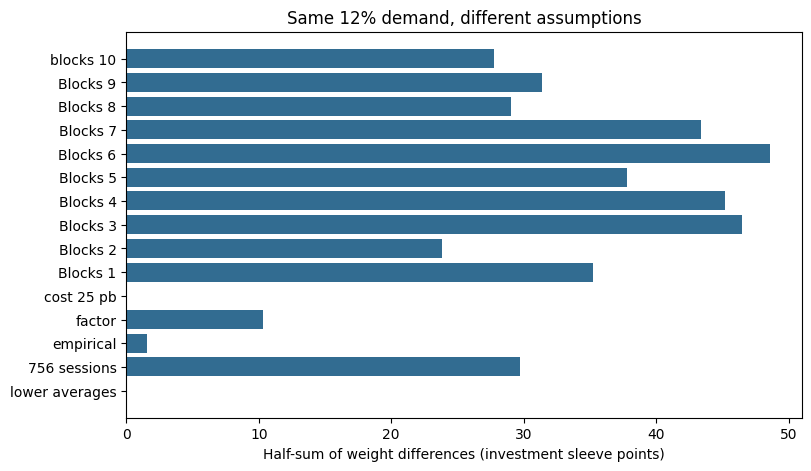

,weight_distance,risk,net
min,NaN,NaN,NaN
median,NaN,NaN,NaN
max,NaN,NaN,NaN


Amended classification 6 times on 16
Maximum risk of the conservative variant in the models tested 12.00%


In [40]:
s = pd.DataFrame(f["stability"])
fig, ax = plt.subplots(figsize=(8,4.6),layout="constrained")
selected=s[~s.name.str.startswith("blocs")].iloc[1:]
ax.barh(selected.name,100*selected.weight_distance,color="#326c91")
ax.set(xlabel="Half-sum of weight differences (investment sleeve points)",title="Same 12% demand, different assumptions")
fig.savefig(section5/"stabilite.png",dpi=160)
plt.show()
display(s[s.name.str.startswith("blocs")][["weight_distance","risk","net"]].agg(["min","median","max"]).mul(100).round(2))
print("Amended classification",f["diagnostics"]["rank_changes"],"times on",f["diagnostics"]["rank_runs"])
print("Maximum risk of the conservative variant in the models tested", f'{f["diagnostics"]["robust_worst_risk"]:.2%}')

### 5.7 · Verify the solver’s optimality and feasibility certificates

- [x] Checked in the project checklist

**Method and tools.** Read the solver status, incumbent return, upper bound, optimality gap and proof for each controlled case.

**Result.** The table distinguishes verified solutions, infeasibility and inconclusive searches. A candidate without a sufficient certificate retains its qualified status.

[Study report](reports/05-faisabilite/README.md)

For maximum performance, the difference is the difference between a verified top end and the performance of the best eligible candidate. The publication threshold is an annual basis for performance. The interrupted case retains the candidate and the margin of uncertainty. The minimum risk uses a specific lower limit of volatility.

In [41]:
display(pd.DataFrame(f["oracle"]).T[["status","risk","net","upper_net","gap","proof"]])
assert f["oracle"]["interruption"]["status"]=="candidate"
assert f["oracle"]["impossible"]["status"]=="impossible"

,status,risk,net,upper_net,gap,proof
under ceiling,optimal,0.02,0.06,0.06,0.0,global linear bound
binding lower volatility bound,optimal,0.1,0.042222,0.042266,0.000043,global separation and bounds
interruption,candidate,0.1,0.042222,0.06,0.017778,research budget or precision
impossible,impossible,None,None,None,None,triangular limit on volatility


### 5.8 · Convert continuous weights into executable orders

- [x] Checked in the project checklist

**Method and tools.** Convert continuous allocations into lot-sized orders, account for costs and recheck the cash reserve and risk constraints.

**Result.** The worked order examples show rounding outcomes. The subsequent multi-asset tables show the 3,322 eligible research inputs and the full-universe frontier. Actual orders remain blocked.

[Study report](reports/univers-complet/README.md)

Starting with a price, a change and a lot size, the engine searches for whole quantities and recalculates costs, cash, exposures and risk. In the small fictitious investment sleeve of 500 CHF, the batch of bonds costs 900 CHF before fees. The cash solution becomes feasible if the customer agrees to raise the minimum invested. This change in mandate must remain explicit.

In [42]:
rows=[]
for label,lots in f["lots"].items():
    order=lots["order"] or {}
    rows.append({"Example":label,"State":lots["status"],"Units":order.get("units"),"CHF fees":order.get("fee_chf"),"Cash CHF":order.get("cash_chf")})
display(pd.DataFrame(rows).set_index("Example"))
assert f["live"]["count"]==0
print("November 2026 Decision: No client order validated.")

,State,Units,CHF fees,Cash CHF
Example,,,,
small investment sleeve,checked batches,"[6.0, 7.0]",0.8595,139.6405
Bond lot,impossible in batches,None,NaN,NaN
Cash if minimum raised,checked batches,[0.0],0.0000,500.0000


November 2026 Decision: No client order validated.


**Final reading.** The models can be used to calculate and compare conditional possibilities. For the account dated 23 November 2026, information on prices, exchange rates and conditions of execution remains insufficient. Section 6 now applies these controls to options and their mixtures.

### Full-universe feasibility and inputs to section 6

The following cells run the multi-asset comparison. The dated inventory, inclusion reasons and frontier distinguish the full universe from the ETF-only, stock-only and Treasury-only control runs. The full-universe allocation considers 3,322 instruments.

,Screened,Submitted
Individual stock,3824,3255
Treasury ETF,2,2
Equity ETF,10,10
Gold (GLD),1,1
Direct Treasury,65,54


,Before ECB Supplement,Complete CHF history after ECB supplement
Years,,
1,3357,3357
3,3088,3088
5,0,2844
10,0,1989


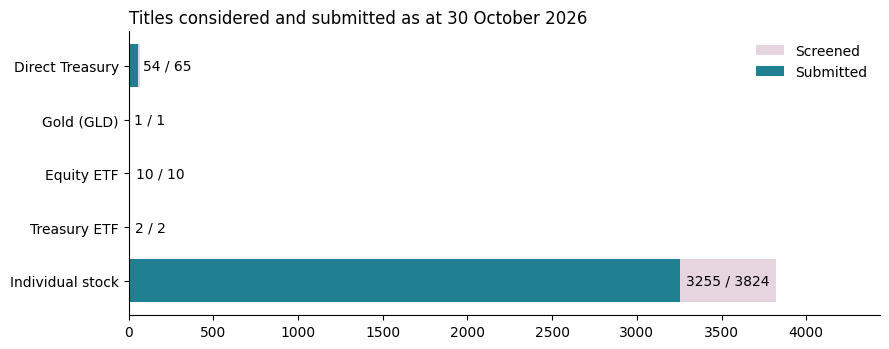

In [43]:
from riskmatch_v2.archive_labels import read_snapshot
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

out = Path("reports/univers-complet")
universe = json.loads((out/"resultats.json").read_text())
cover = pd.DataFrame(universe["annual"][-1]["classes"]).T.rename(columns={"size":"Screened","sum":"Submitted"})
assert cover.loc["Direct Treasury", "Screened"] == 65
assert cover.loc["Individual stock","Screened"] == 3824
assert cover[["Submitted"]].sum().iloc[0] == universe["subsets"]["Full universe"]["offered"]
archive=Path("data/local/univers")/universe["snapshot"]
if (archive/"membership.parquet").exists():
    dated=read_snapshot(archive/"membership.parquet",filters=[("day","=",universe["date"])])
    allocation=read_snapshot(archive/"weights.parquet",filters=[("day","=",universe["date"])])
    exports=archive.parent/"exports"/universe["snapshot"]
    exports.mkdir(parents=True,exist_ok=True)
    dated.to_csv(exports/"inventaire.csv",index=False)
    allocation.merge(dated[["id","symbol","issuer","class"]],on="id",validate="many_to_one").to_csv(exports/"allocations.csv",index=False)
    history=read_snapshot(archive/"membership.parquet",columns=["id","day","symbol","issuer"]).sort_values("day").drop_duplicates("id",keep="last")
    gaps=pd.DataFrame([(name,asset) for name,scenarios in universe["runs"].items() for asset in scenarios["central"]["unresolved"]],columns=["option","id"])
    gaps.merge(history,on="id",how="left",validate="many_to_one").rename(columns={"day":"last_inventory_date"}).to_csv(exports/"valorisations_a_verifier.csv",index=False)
    assert dated.id.is_unique
    assert set(allocation.id).issubset(set(dated.loc[dated.included,"id"]))
display(cover)
economic_study = json.loads(Path("reports/econometrie/results.json").read_text())
assert economic_study["source_snapshot"] == universe["snapshot"]
display(pd.DataFrame(economic_study["windows"], index=["Before ECB Supplement", "Complete CHF history after ECB supplement"]).T.rename_axis("Years"))
fig, ax = plt.subplots(figsize=(9,3.6))
ax.barh(cover.index, cover["Screened"],color="#e6d5de",label="Screened")
bars=ax.barh(cover.index,cover["Submitted"],color="#207f90",label="Submitted")
ax.bar_label(bars,labels=[f"{a} / {b}" for a,b in zip(cover["Submitted"],cover["Screened"])],padding=4)
ax.set_xlim(0,cover["Screened"].max()*1.16);ax.set_title("Titles considered and submitted as at 30 October 2026",loc="left")
ax.legend(frameon=False);ax.spines[["right","top"]].set_visible(False)
fig.tight_layout();fig.savefig(out/"couverture.png",dpi=140,bbox_inches="tight");plt.show()

### Frontier and sensitivity to estimation error


In [44]:
display(pd.DataFrame(universe["frontier"]).T)
display(pd.DataFrame(universe["subsets"]).T)
display(pd.DataFrame(universe["stability"]))
display(pd.DataFrame(universe["bootstrap"]).round(4))
tests = pd.DataFrame(universe["validation"])
display(tests.groupby("option").agg(windows=("decision","size"),comparable_windows=("realized_vol","count"),mean_realized_volatility=("realized_vol","mean")))
assert all(x["gap"] is None or x["gap"] >= 0 for x in universe["frontier"].values())

,status,reason,upper_return,gap,risk_upper_bound,vol,net
0%–12%,optimal,primal control and support hyperplan bound,0.437059,0.000003,16.209998,0.12,0.437055
0%–20%,optimal,primal control and support hyperplan bound,0.631179,0.000002,16.209998,0.2,0.631177
0%–30%,optimal,primal control and support hyperplan bound,0.763216,0.000004,16.209998,0.3,0.763212
0%–40%,optimal,primal control and support hyperplan bound,0.813447,0.000011,16.209998,0.4,0.813435
18%–22%,optimal,primal control and support hyperplan bound,0.667055,0.0,16.209998,0.22,0.667055
28%–32%,optimal,primal control and support hyperplan bound,0.77806,0.000002,16.209998,0.32,0.778058
38%–42%,optimal,primal control and support hyperplan bound,0.814836,0.0,16.209998,0.42,0.814836
99%–101%,optimal,primal control and support hyperplan bound,0.814879,0.0,16.209998,0.99,0.814879


,offered,held,net,vol,status
ETFs only,13,5,0.12539,0.12,optimal
Individual stocks only,3255,147,0.437055,0.12,optimal
Direct Treasuries only,54,2,0.062015,0.089333,optimal
Full universe,3322,147,0.437055,0.12,optimal


,model,net,vol,distance,base_net,base_vol,gap
0,1,0.437055,0.12,2.905500e-07,0.437055,0.120000,0.000003
1,2,0.441418,0.12,3.919590e-01,0.371404,0.123998,0.000005
2,3,0.267995,0.12,2.605824e-07,0.437055,0.120000,0.000002


,draw,net,risk_under_base,distance
0,1,0.8422,0.1676,0.7311
1,2,0.7577,0.1358,0.5151
2,3,0.7519,0.1366,0.6932
3,4,0.6374,0.1324,0.5694
4,5,0.6034,0.1429,0.5972
5,6,0.8654,0.1264,0.6178
6,7,0.7584,0.1591,0.6079
7,8,0.7372,0.1399,0.5675


,windows,comparable_windows,mean_realized_volatility
option,,,
60/40 benchmark,9,9,0.107699
Diversification,9,0,NaN
Hedge,9,2,0.210916
Return,9,2,0.216033
Robust,9,1,0.261192


## 6. Portfolio options, scores and blends

The 30 October 2026 case allocates **CHF 35,000**, keeps **CHF 15,000** in reserve and caps estimated annual volatility at **12%** for the investment sleeve. Of **3,902** instruments reviewed, **3,322** passed the model’s input checks: 3,255 individual US stocks, 54 direct US Treasuries and 13 ETFs, including GLD. The optimizer considers all eligible instruments and assigns positive weights to a subset.

**Partial.** Four option labels yield three distinct allocations. Items 6.3–6.5 remain open because the verified historical replay is incomplete. The separate account check currently permits no actual orders.

[Multi-asset study and figures](reports/univers-complet/README.md) · [Original 13-ETF benchmark](reports/06-options/ETF_Benchmark.ipynb)

### 6.1 · Define the portfolio variants

- [x] Checked in the project checklist

**Method and tools.** Construct return, robust, diversification and hedge variants under the same dated mandate. Compare holdings and identify duplicate weight vectors.

**Result.** Four labels represent three distinct allocations in this case. The fixed 60/40 benchmark is reported separately from feasible options.

[Study report](reports/univers-complet/README.md)

Performance maximizes the estimated annual average after costs. Robust maximizes the worst estimate of three models. Diversification limits the concentration of weights and Coverage minimizes the loss of the 2008 scenario. The latter two can return up to 2.5 points of estimated return. Weights sufficiently close are grouped before scores and mixtures. The reference 60% SPY / 40% IEF is displayed even when it exceeds the limits.

3 902 securities examined  3 322 subject to calculation.


,Positions,Lecture
Option,,
Return,147,Distinct in the mandate
Robust,147,Combined with Return
Diversification,326,Distinct in the mandate
Hedge,135,Distinct in the mandate
60/40 benchmark,2,Reference outside the mandate


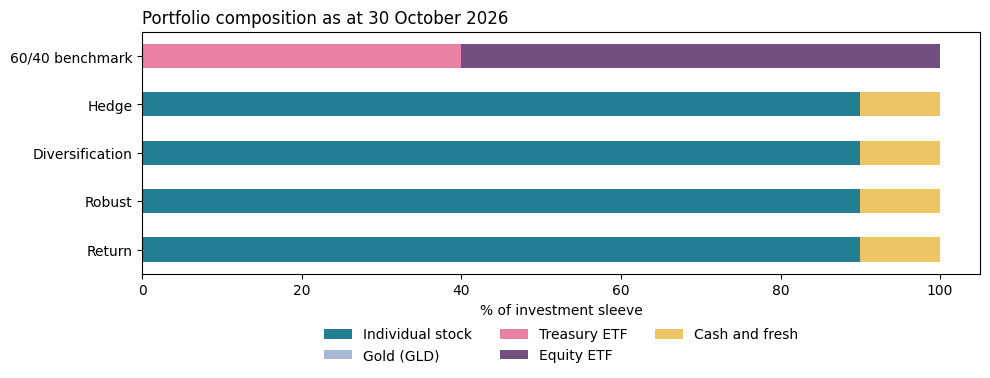

The four solutions recalculated from local models are consistent with the archived weights.


In [45]:
from riskmatch_v2.archive_labels import read_snapshot
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from riskmatch_v2.options.scoring import rank

out = Path("reports/univers-complet")
universe = json.loads((out / "resultats.json").read_text())
cfg6 = json.loads(Path("config/options-6.json").read_text())
eco6 = json.loads(Path("reports/econometrie/results.json").read_text())
assert eco6["source_snapshot"] == universe["snapshot"] and eco6["end"] == universe["date"] == cfg6["market"]
archive6 = Path("data/local/univers") / universe["snapshot"]
cards6 = universe["cards"]
aliases6 = universe["aliases"]
classes6 = pd.DataFrame(universe["annual"][-1]["classes"]).T
assert classes6["sum"].sum() == universe["subsets"]["Full universe"]["offered"]
print(f'{classes6["size"].sum():,} securities examined, {classes6["sum"].sum():,} subject to calculation.'.replace(",", " "))
display(pd.DataFrame([{"Option":name, "Positions":c["n"], "Lecture":f"Combined with {aliases6[name]}" if name in aliases6 else ("Distinct in the mandate" if c["valid"] else "Reference outside the mandate")} for name,c in cards6.items()]).set_index("Option"))
asset_weights = pd.DataFrame({k:c["by_class"] for k,c in cards6.items()}).T.fillna(0)
asset_weights["Cash and fresh"] = 1 - asset_weights.sum(axis=1)
fig, ax = plt.subplots(figsize=(10,4))
(asset_weights*100).plot.barh(stacked=True,ax=ax,color=["#227e93","#a7b8d6","#e981a4","#714f80","#ecc565","#e4e1dd"][:len(asset_weights.columns)])
ax.set_xlabel("% of investment sleeve");ax.set_title("Portfolio composition as at 30 October 2026",loc="left")
ax.legend(loc="upper center",bbox_to_anchor=(.5,-.17),ncol=3,frameon=False)
fig.tight_layout();fig.savefig(out/"compositions.png",dpi=140,bbox_inches="tight");plt.show()

# Local copy: verify the four allocations against the archived factor models used in Options.
from importlib.util import find_spec
if (archive6/"models.npz").is_file() and all(find_spec(lib) for lib in ("cvxpy", "sklearn", "pyarrow")):
    from riskmatch_v2.universe.desk import load_model
    from riskmatch_v2.universe.model import options
    models6, shock6, _, _ = load_model(archive6)
    assert len(models6[0].names) == int(classes6["sum"].sum())
    recorded6 = read_snapshot(archive6/"weights.parquet", filters=[("day", "=", universe["date"])])
    for name, weights in options(models6, shock6, cfg6["risk_cap"], cfg6["return_concession"]).items():
        expected = recorded6.loc[recorded6.option.eq(name)].set_index("id").weight
        np.testing.assert_allclose(weights, expected.reindex(models6[0].names, fill_value=0), atol=1e-6, rtol=0)
    print("The four solutions recalculated from local models are consistent with the archived weights.")


### 6.2 · Measure trade-offs

- [x] Checked in the project checklist

**Method and tools.** Compare estimated net return, volatility, concentration, risk contributions and the conditional WTI shock. Report the exposure coverage.

**Result.** The option-level table shows how allocations under the same cap can differ on other dimensions. The shock estimates describe historical associations.

[Study report](reports/univers-complet/README.md)

The regulated historical averages are used for optimization. Their range describes the gap between the three models. The performance achieved requires a sufficiently documented trajectory. The loss of the 2008 scenario combines observed returns with projections for securities without history at that date. The WTI scenario applies the sensitivities of Section 8, other constant factors, to the weights already calculated. The exploratory forecasts in Section 12 remain unweighted in the allocation.

In [46]:
from riskmatch_v2.archive_labels import read_snapshot
wti6 = pd.DataFrame(eco6["portfolios"]).set_index("option")
assert set(wti6.index) == set(cards6)
comparison6 = pd.DataFrame({name:{
    "Estimated net return (%/year)":100*c["net"], "Low estimate (%)":100*c["interval"][0],
    "High estimate (%)":100*c["interval"][1], "Volatility (%/year)":100*c["vol"],
    "Annual variance":c["variance"], "Estimated Sharpe ratio":c["sharpe"], "HHI concentration":c["hhi"],
    "Initial costs (% of investment sleeve)":100*c["fee"], "Loss of scenario 2008 (%)":100*c["loss"],
    "Impact weight 2008 observed (%)":100*c["stress_observed_weight"],
    "Effect associated with WTI +10 USD (%)":wti6.at[name,"covered_wti_plus10_pct"],
    "Composite performance of the game (%/year)":None if c["cagr"] is None else 100*c["cagr"]
} for name,c in cards6.items()}).T
display(comparison6.round(3).fillna("Unavailable"))
if (archive6/"euler.parquet").is_file():
    contributions = read_snapshot(archive6/"euler.parquet").groupby("option").contribution.sum()
    for name,c in cards6.items():
        np.testing.assert_allclose(contributions[name], c["vol"], atol=1e-7)

,Estimated net return (%/year),Low estimate (%),High estimate (%),Volatility (%/year),Annual variance,Estimated Sharpe ratio,HHI concentration,Initial costs (% of investment sleeve),Loss of scenario 2008 (%),Impact weight 2008 observed (%),Effect associated with WTI +10 USD (%),Composite performance of the game (%/year)
Return,43.706,26.799,43.706,12.000,0.014,3.642,0.026,0.09,23.184,34.563,0.105,Unavailable
Robust,43.704,26.799,43.704,12.000,0.014,3.642,0.026,0.09,23.236,34.670,0.106,Unavailable
Diversification,41.206,25.549,41.206,12.000,0.014,3.434,0.014,0.09,23.710,34.362,0.115,Unavailable
Hedge,41.206,25.549,41.206,12.000,0.014,3.434,0.028,0.09,7.507,25.662,0.041,Unavailable
60/40 benchmark,9.408,9.408,14.422,12.676,0.016,0.742,0.520,0.10,15.798,100.000,0.005,6.789


### 6.3 · Replay transactions

- [ ] Open in the project checklist

**Method and tools.** Replay the nine-year paths on common verified dates. Locate the first unresolved price or exit before comparing realized returns.

**Evidence and remaining work.** The OTC continuation extends the common comparison from 37 to 51 sessions through 12 January 2018. BHAC blocks 16 January. Later paths remain indicative until missing prices and exits are reconciled.

[Study report](reports/univers-complet/README.md)

Nine annual decisions, from October 2017 to October 2025, are followed by orders at the earliest at the next session. The table gives the cumulative performance of the options on **their common verifiable period**. Beyond the first break, the graph gives an indicative valuation. Undocumented output can affect all of the following values.

/var/folders/5l/jcwzqspj5kl7wzlcwvhhk6h40000gn/T/ipykernel_95492/3674999101.py:7: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  display(common6[["end","sessions","Cumulative return (%)","first_problem_through_january"]].fillna("None through January"))


,end,sessions,Cumulative return (%),first_problem_through_january
Return,2018-01-12,51,14.48,2018-01-16
Robust,2018-01-12,51,11.52,2018-01-16
Diversification,2018-01-12,51,11.08,2018-01-16
Hedge,2018-01-12,51,16.32,2018-01-16
60/40 benchmark,2018-01-12,51,1.40,None through January


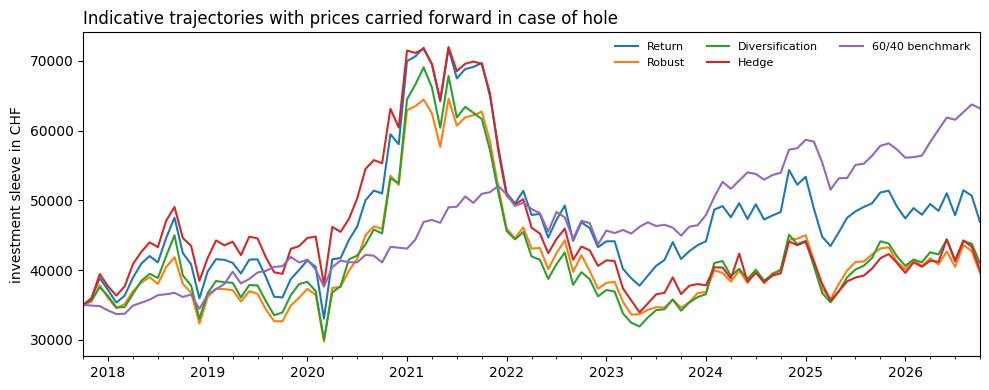

In [47]:
runs6 = universe["runs"]
central6 = pd.DataFrame({name:scenarios["central"] for name,scenarios in runs6.items()}).T
repair6 = json.loads((out / "replay-evidence.json").read_text())
assert repair6["snapshot"] == universe["snapshot"]
common6 = pd.DataFrame({name: variants["central"] for name, variants in repair6["scenarios"].items()}).T
common6["Cumulative return (%)"] = (100*common6["cumulative"].astype(float)).round(2)
display(common6[["end","sessions","Cumulative return (%)","first_problem_through_january"]].fillna("None through January"))
hist = pd.DataFrame(universe["monthly"])
hist.index = pd.to_datetime(hist.index)
fig, ax = plt.subplots(figsize=(10,4))
hist.plot(ax=ax);ax.set_ylabel("investment sleeve in CHF")
ax.set_title("Indicative trajectories with prices carried forward in case of hole",loc="left");ax.legend(frameon=False,ncol=3,fontsize=8)
fig.tight_layout();fig.savefig(out/"rejeu.png",dpi=140,bbox_inches="tight");plt.show()

### 6.4 · Reconcile each replay cash flow

- [ ] Open in the project checklist

**Method and tools.** Reconcile fees, cash payments, redemptions and residuals along the simulated paths.

**Evidence and remaining work.** The arithmetic reconciliation is visible below. Missing market observations still prevent certification of the full historical cash-flow comparison.

[Study report](reports/univers-complet/README.md)

The central register follows the positions, cash, sales settlement, coupons and withdrawal requested. Scenarios retain a verifiable accounting identity even when a deferred price makes the return uncertain. The amounts below relate to the research mandate.

In [48]:
flows6 = central6[["fees","paid","unpaid","cash_redemptions","max_residual"]].astype(float)
display(flows6.rename(columns={"fees":"Cumulative costs (CHF)","paid":"Withdrawal Served (CHF)","unpaid":"Unserved withdrawal (CHF)","cash_redemptions":"Cash outflows processed","max_residual":"Maximum accounting difference (CHF)"}))
assert max(s["max_residual"] for runs in runs6.values() for s in runs.values()) < 1e-5
if (archive6/"nav.parquet").is_file():
    daily6 = pd.read_parquet(archive6/"nav.parquet")
    np.testing.assert_allclose(daily6.nav, daily6.cash + daily6.receivable + daily6.invested, atol=1e-5, rtol=0)
gaps6 = {key for runs in runs6.values() for key in runs["central"]["unresolved"]}
print(f"{len(gaps6)} separate securities have a valuation to check on at least one central trajectory.")
print("Reconciliation of archived orders and daily cash, fees, turnover and NAV:")
display(pd.Series(repair6["archive_ledger"]["max_absolute_residual"], name="Maximum absolute difference (CHF)"))

,Cumulative costs (CHF),Withdrawal Served (CHF),Unserved withdrawal (CHF),Cash outflows processed,Maximum accounting difference (CHF)
Return,565.275177,1000.0,0.0,44.0,1.455192e-11
Robust,479.240334,1000.0,0.0,47.0,1.455192e-11
Diversification,453.268497,1000.0,0.0,120.0,1.455192e-11
Hedge,532.870925,1000.0,0.0,32.0,1.455192e-11
60/40 benchmark,58.679746,0.0,1000.0,0.0,7.275958e-12


204 separate securities have a valuation to check on at least one central trajectory.
Reconciliation of archived orders and daily cash, fees, turnover and NAV:


cash_chf        5.940104e-05
fees_chf        5.989923e-08
turnover_chf    5.989923e-05
nav_chf         7.474910e-12
Name: Maximum absolute difference (CHF), dtype: float64

### 6.5 · Compare strategies under identical execution assumptions

- [ ] Open in the project checklist

**Method and tools.** Hold strategy and mandate fixed, then compare fee, lot and rebalance variants across the 35 simulations.

**Evidence and remaining work.** The scenario table isolates execution assumptions. Comparisons after the common verified interval remain provisional.

[Study report](reports/univers-complet/README.md)

Each column in the table corresponds to the same strategy and each row to an execution assumption. The amounts are: **simulated final values in CHF**, indicative for interrupted trajectories. The sign of a gap between scenarios is not enough to classify the options.

In [49]:
assert all(set(cases) == set(cfg6["scenarios"]) for cases in runs6.values())
values6 = pd.DataFrame({name:{scenario:s["final"] for scenario,s in cases.items()} for name,cases in runs6.items()})
display(values6.round().astype(int))
assert values6.size == universe["simulations"]
print(f"{values6.size} simulations. Controlled risk limit on weights before and after rounding in the study.")
display(pd.DataFrame(universe["rounding"]).T.rename(columns={"status":"Batch control","cash_chf":"Solde CHF","net":"Estimated return (Dec.)","vol":"Estimated volatility (Dec.)"}))
print("Repaired common window: cumulative return (%) by execution assumption")
display(pd.DataFrame({name:{key:100*v["cumulative"] for key,v in cases.items()} for name,cases in repair6["scenarios"].items()}).round(2))

,Return,Robust,Diversification,Hedge,60/40 benchmark
central,46903,39570,40999,39984,63199
no fees,47472,40032,41480,40477,63291
25 bp,46059,38885,40286,39254,63063
wider spread,44681,37764,39120,38064,62836
one extra session,43765,37616,38920,38298,63346
first basket missed,39380,36940,37517,31352,60856
whole units,45952,39785,38866,40246,62352


35 simulations. Controlled risk limit on weights before and after rounding in the study.


,Batch control,Solde CHF,Estimated volatility (Dec.),Estimated return (Dec.)
Return,checked batches,6158.182238,0.111925,0.404069
Robust,checked batches,6216.988371,0.111608,0.403008
Diversification,checked batches,9809.711085,0.103491,0.352474
Hedge,checked batches,5457.349426,0.113284,0.383946


Repaired common window: cumulative return (%) by execution assumption


,Return,Robust,Diversification,Hedge,60/40 benchmark
central,14.48,11.52,11.08,16.32,1.40
no fees,14.57,11.61,11.17,16.41,1.51
25 bp,14.34,11.38,10.95,16.19,1.25
wider spread,14.12,11.16,10.72,15.96,1.00
one extra session,13.94,11.19,11.06,15.87,1.70
first basket missed,0.00,0.00,0.00,0.00,0.00
whole units,14.34,11.32,10.32,16.09,1.40


### 6.6 · Define a mandate-fit score

- [x] Checked in the project checklist

**Method and tools.** Apply mandate-fit criteria only to distinct admissible options. Withhold a ranking when an indispensable measure is missing.

**Result.** The annual score remains unavailable for the incomplete multi-asset replay. The output identifies the exclusions and criterion coverage.

[Study report](reports/univers-complet/README.md)

Both fictitious profiles focus on financial objective or diversification. The constraints of the mandate are checked prior to classification. An indispensable missing measure suspends the score on the annual replay. The table shows the pattern for each separate option. The actual account conditions are controlled separately.

In [50]:
distinct6 = {n:c for n,c in cards6.items() if n not in aliases6}
annual_scores6 = {client:rank(distinct6, weights, cfg6, research=True) for client,weights in cfg6["profiles"].items()}
assert annual_scores6 == universe["profiles"]
display(pd.DataFrame({client:grid["excluded"] for client,grid in annual_scores6.items()}))
for client,grid in annual_scores6.items():
    print(f'{client} · {len(grid["rows"])} option(s) listed on the annual replay.')
print(f'Real account: {universe["live"]["after_collection"]} eligible instrument on {universe["live"]["examined"]:,} entries examined.'.replace(",", " "))

,Goal,Diversification
Return,missing indispensable measure,missing indispensable measure
Diversification,missing indispensable measure,missing indispensable measure
Hedge,missing indispensable measure,missing indispensable measure
60/40 benchmark,outside mandate or unverified negotiability,outside mandate or unverified negotiability


Goal · 0 option(s) listed on the annual replay.
Diversification · 0 option(s) listed on the annual replay.
Real account: 0 eligible instrument on 27 507 entries examined.


### 6.7 · Test missing data and ranking stability

- [x] Checked in the project checklist

**Method and tools.** Run the missing-data and near-tie checks and compare separately with a fixed-weight, 12-month retrospective diagnostic.

**Result.** The diagnostic uses holdings known at the end of its window. Its scores describe that specific exercise, and do not validate a forecast.

[test_options.py](tests/test_options.py)

This other experiment applies the weights of October 2026 to the previous 12 months, with monthly rebalancing. The composition is known a posteriori. The following groups describe only this experience and do not allow the strategies to be divided over nine years. Volatility models and acceleration alerts remain experimental.

In [51]:
diagnostic6=[]
for client,grid in universe["backcast"].items():
    for name,row in grid["rows"].items():
        assert abs(sum(row["contributions"].values())-row["total"]) < 1e-8
        diagnostic6.append({"Priority":client,"Option":name,"Retrospective score of 100":round(row["total"],2),"Groupe":row["group"]})
display(pd.DataFrame(diagnostic6))
print("Score grouping margin:", cfg6["tie_points"], "points.")

,Priority,Option,Retrospective score of 100,Groupe
0,Goal,Return,83.05,2
1,Goal,Diversification,82.67,2
2,Goal,Hedge,91.78,1
3,Diversification,Return,83.08,2
4,Diversification,Diversification,82.73,2
5,Diversification,Hedge,91.80,1


Score grouping margin: 2.0 points.


In [52]:
from riskmatch_v2.options.scenarios import scoring_controls
score_checks = scoring_controls(cfg6)
display(pd.DataFrame({case: {"Coverage": grid["coverage"],
                             "A score": grid["rows"]["A"]["total"],
                             "B score": grid["rows"]["B"]["total"],
                             "A group": grid["rows"]["A"]["group"],
                             "B group": grid["rows"]["B"]["group"]}
                      for case, grid in score_checks.items()}).T)
print("Synthetic scenarios used to test the scoring rules.")

,Coverage,A score,B score,A group,B group
full,100.0,64.395833,64.425000,1.0,1.0
missing_sentiment,90.0,64.328704,64.361111,1.0,1.0
reversal,90.0,64.393519,64.361111,1.0,1.0


Synthetic scenarios used to test the scoring rules.


### 6.8 · Combine several portfolios at client-selected weights

- [x] Checked in the project checklist

**Method and tools.** Combine the underlying holdings using client-selected weights and recompute exposures, costs, risk and lot effects.

**Result.** The 60/40 manual blend illustrates how common positions aggregate. Blending option scores would not reproduce these portfolio measures.

[Study report](reports/univers-complet/README.md)

The manual mixture combines 60% of the return option with 40% of the Cover option. A common title is aggregated only once. The calculation re-evaluates volatility with the covariance of securities and verifies fees, financing and lots on the investment sleeve. The reserve remains outside the mixture.

In [53]:
from riskmatch_v2.archive_labels import read_snapshot
mix6=universe["mixes"]["Manual 60/40"]
display(pd.Series(mix6["parts"], name="Selected share (%)").mul(100).to_frame())
display(pd.DataFrame(mix6["top"])[["symbol","class","weight"]].assign(weight=lambda x:(100*x.weight).round(2)).rename(columns={"symbol":"Titre","class":"Classe","weight":"Weight of investment sleeve (%)"}))
assert abs(sum(mix6["parts"].values())-1) < 1e-8
assert abs(sum(mix6["by_class"].values())+mix6["cash"]+mix6["fee"]-1) < 1e-6
if (archive6/"weights.parquet").is_file():
    w6=read_snapshot(archive6/"weights.parquet",filters=[("day","=",universe["date"])]).pivot(index="id",columns="option",values="weight").fillna(0)
    parts6=pd.Series(mix6["parts"])
    combined6=w6[parts6.index] @ parts6
    for top in mix6["top"]:
        np.testing.assert_allclose(combined6[top["id"]], top["weight"], atol=1e-8)
print(f'{mix6["n"]} positions · estimated volatility {mix6["vol"]:.2%} · {mix6["lots"]}.')

,Selected share (%)
Return,60.0
Diversification,0.0
Hedge,40.0


,Titre,Classe,Weight of investment sleeve (%)
0,MO,Individual stock,3.96
1,JNJ,Individual stock,3.21
2,WTRG,Individual stock,2.80
3,PTGX,Individual stock,2.76
4,DG,Individual stock,2.69
5,LBRX,Individual stock,2.37
6,AII,Individual stock,2.35
7,PVLA,Individual stock,2.27
8,SLS,Individual stock,2.22
9,XMAX,Individual stock,2.19


165 positions · estimated volatility 11.82% · checked batches.


### 6.9 · Optimize the blend of the selected options

- [x] Checked in the project checklist

**Method and tools.** Compare the manual blend with optimized combinations on net return, risk, Sharpe ratio and execution constraints.

**Result.** Eight blends are recorded. The table preserves unavailable annual scores and the constraints that qualify the comparison.

[Study report](reports/univers-complet/README.md)

The table compares the manual mixture, equiweighting and candidates obtained for three objectives with or without a 10% floor per component. The shares relate to the separate options. Batch checks shall follow the calculation by continuous weight. A combination that meets the estimated ceiling may still lack data for its historical score.

In [54]:
combinations6=[]
for label,m in universe["mixes"].items():
    row={"Blending":label,"Statut":m["status"]}
    if "parts" in m:
        assert np.isclose(sum(m["parts"].values()),1) and m["valid"]
        row.update({f"Share {name} (%)":round(100*w,2) for name,w in m["parts"].items()})
        row.update({"Estimated volatility (%)":round(100*m["vol"],2),"Estimated net return (%)":round(100*m["net"],2),
                    "Estimated Sharpe ratio":round(m["sharpe"],2),"Lots":m["lots"],"Annual score (objective)":m["scores"]["Goal"]})
    combinations6.append(row)
display(pd.DataFrame(combinations6).set_index("Blending").fillna("Unavailable"))

,Statut,Share Return (%),Share Diversification (%),Share Hedge (%),Estimated volatility (%),Estimated net return (%),Estimated Sharpe ratio,Lots,Annual score (objective)
Blending,,,,,,,,,
Manual 60/40,selected shares,60.00,0.00,40.00,11.82,42.71,3.61,checked batches,Unavailable
Equal weight,selected shares,33.33,33.33,33.33,11.74,42.04,3.58,checked batches,Unavailable
Return · 0% floor,candidate verified,100.00,0.00,0.00,12.00,43.71,3.64,checked batches,Unavailable
Return · 10% floor,candidate verified,80.00,10.00,10.00,11.89,43.21,3.63,checked batches,Unavailable
Minimum risk · 0% floor,candidate verified,7.02,45.63,47.35,11.71,41.38,3.53,checked batches,Unavailable
Minimum risk · 10% floor,candidate verified,10.00,43.77,46.23,11.71,41.46,3.54,checked batches,Unavailable
Sharpe · 0% floor,candidate verified,96.01,0.00,3.99,11.97,43.61,3.64,checked batches,Unavailable
Sharpe · 10% floor,candidate verified,80.00,10.00,10.00,11.89,43.21,3.63,checked batches,Unavailable


## 7. Goals and cash-flow schedules

Both theoretical clients start with CHF 50,000, identical gamble responses, a 3–5% desired return and a confirmed 12% volatility cap. This section asks whether the dated expenses and terminal goals fit those preferences. It uses the section 6 multi-asset model on 30 October 2026. All future cash flows are scenarios.

[Client A](reports/07-funding/client-A.json) · [Client B](reports/07-funding/client-B.json) · [Results and controls](reports/07-funding/results.json)

### 7.1 · Build the CHF cash-flow schedule

- [x] Checked in the project checklist

**Method and tools.** Replay the card bank and risk confirmation. Separate the protected reserve from the investment sleeve. Find dated annual net-rate roots with SciPy, verify uniqueness, and reproject the terminal wealth.

**Result.** A requires 12.61% and B requires 8.62% annually, both above the stated range. The table shows the effect of changing one funding assumption at a time.

[Study report and reproduction](reports/07-funding/README.md)

In [55]:
fund_dir = Path("reports/07-funding")
fund_study = json.loads((fund_dir / "results.json").read_text())
clients7 = {name:json.loads((fund_dir / f"client-{name}.json").read_text()) for name in fund_study["clients"]}
assert clients7["A"]["aversion"] == clients7["B"]["aversion"]
cash_rows = []
for name, client in clients7.items():
    sleeve = client["liquidity"]["investable_chf"]["low"]
    reserve7 = client["liquidity"]["reserve_chf"]["low"]
    plan = client["plan"]
    start7 = pd.Timestamp(client["decision"])
    end7, bill7 = pd.Timestamp(plan["end"]), pd.Timestamp(plan["expense"])
    rate7 = client["funding_requirements"]["base"]["rates"][0]
    flow7 = client["answers"]["F03"][0]["high"]
    reconstructed = (sleeve * (1+rate7)**((end7-start7).days/365.25)
                     - (flow7-reserve7) * (1+rate7)**((end7-bill7).days/365.25))
    assert abs(reconstructed - plan["goal_chf"]) < .01
    cash_rows.append([name, bill7.date(), reserve7, sleeve, end7.date(), plan["goal_chf"], 100*rate7])
display(pd.DataFrame(cash_rows, columns=["Client","Bill date","Reserve CHF","Sleeve CHF","Goal date","Goal CHF","Required annual rate (%)"]).set_index("Client").round(2))
rates7 = pd.DataFrame({name:{key:100*v["rates"][0] for key,v in c["funding_requirements"].items()} for name,c in clients7.items()})
display(rates7.rename_axis("One change to the base schedule · annual rate (%)").round(2))

,Bill date,Reserve CHF,Sleeve CHF,Goal date,Goal CHF,Required annual rate (%)
Client,,,,,,
A,2027-03-31,15000.0,35000.0,2029-10-31,50000,12.61
B,2030-03-31,0.0,50000.0,2034-10-31,75000,8.62


,A,B
One change to the base schedule · annual rate (%),,
base,12.61,8.62
contribution,8.05,7.25
higher_goal,19.66,10.15
later_goal,9.32,7.73


### 7.2 · Evaluate multiple investment horizons

- [x] Checked in the project checklist

**Method and tools.** Sample 6-, 12- and 24-month blocks jointly across all held assets and FX through monthly CHF total returns. Deduct entry and exit costs, retain cash, and compare paired portfolios with the same seed and calendar.

**Result.** The 6-month exercise has seven overlapping source blocks, the 12-month exercise has one, and no paired 24-month block exists. The longer fixed-benchmark-only history and deterministic stress cases disclose the impact of that limitation.

[Study report and reproduction](reports/07-funding/README.md)

In [56]:
paired7 = []
for name, client in clients7.items():
    for length, experiment in client["simulations"].items():
        for label in ("Custom", "Fixed 60/40"):
            base = experiment["variants"].get(label, {}).get("base", {})
            paired7.append([name, label, int(length), experiment["source_blocks"], base.get("paths"), base.get("all_goals_met"), base.get("mean_terminal_gap_chf")])
display(pd.DataFrame(paired7, columns=["Client","Portfolio","Block (months)","Source blocks","Paths","All goals met (count)","Mean terminal gap CHF"]).round(2).fillna("Unavailable"))
for name, client in clients7.items():
    print(name, "· 24-month source blocks, fixed benchmark only:", client["benchmark_only"]["24"]["source_blocks"])
display(pd.DataFrame({n:v["treasury_example"] for n,v in clients7.items()}).T[["cusip","maturity","coupons_due_by_bill","principal_usd","illustrative_chf_by_bill"]])

,Client,Portfolio,Block (months),Source blocks,Paths,All goals met (count),Mean terminal gap CHF
0,A,Custom,6,7,2000.0,2000.0,0.0
1,A,Fixed 60/40,6,7,2000.0,1796.0,222.27
2,A,Custom,12,1,1.0,1.0,0.0
3,A,Fixed 60/40,12,1,1.0,0.0,4095.4
4,A,Custom,24,0,Unavailable,Unavailable,Unavailable
5,A,Fixed 60/40,24,0,Unavailable,Unavailable,Unavailable
6,B,Custom,6,7,2000.0,2000.0,0.0
7,B,Fixed 60/40,6,7,2000.0,847.0,4899.54
8,B,Custom,12,1,1.0,1.0,0.0
9,B,Fixed 60/40,12,1,1.0,0.0,25987.79


A · 24-month source blocks, fixed benchmark only: 97
B · 24-month source blocks, fixed benchmark only: 97


,cusip,maturity,coupons_due_by_bill,principal_usd,illustrative_chf_by_bill
A,91282CHC8,2033-05-15,[2026-11-15],0.0,1.388813
B,91282CHC8,2033-05-15,"[2026-11-15, 2027-05-15, 2027-11-15, 2028-05-1...",0.0,9.721687


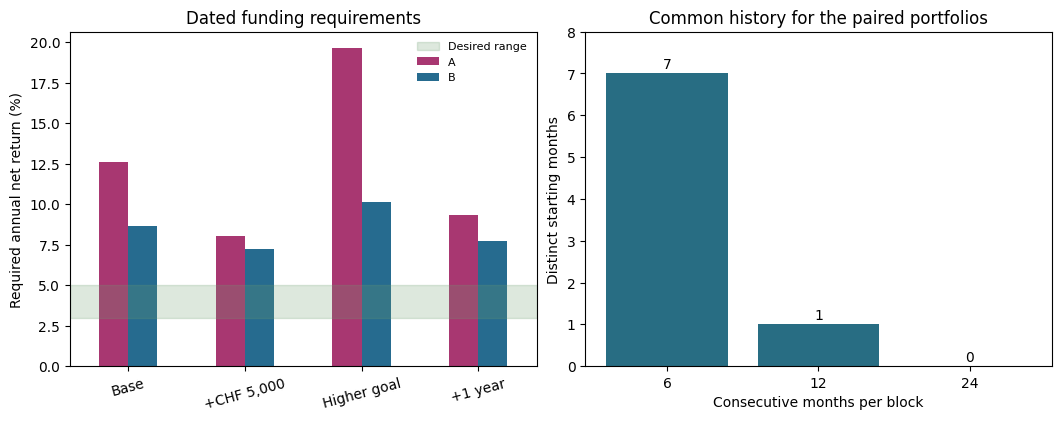

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.1), layout="constrained")
rates7.rename(index={"base":"Base", "contribution":"+CHF 5,000", "higher_goal":"Higher goal", "later_goal":"+1 year"}).plot.bar(ax=axes[0], color=["#a83771","#266b8f"], rot=15)
axes[0].axhspan(3, 5, color="#6d9e70", alpha=.23, label="Desired range")
axes[0].set(ylabel="Required annual net return (%)", title="Dated funding requirements", xlabel="")
axes[0].legend(frameon=False, fontsize=8)
lengths = ["6","12","24"]
axes[1].bar(lengths, [clients7["A"]["simulations"][k]["source_blocks"] for k in lengths], color="#286d83")
axes[1].set(xlabel="Consecutive months per block", ylabel="Distinct starting months", title="Common history for the paired portfolios")
for k in lengths:
    count = clients7["A"]["simulations"][k]["source_blocks"]
    axes[1].text(lengths.index(k), count+.12, str(count), ha="center")
axes[1].set_ylim(0,8)
fig.savefig(fund_dir/"funding.png", dpi=160)
plt.show()

### 7.3 · Replay the complete client journey with the V2 catalogue

- [x] Checked in the project checklist

**Method and tools.** Use the same risk answers with different dates, then round the section 6 holdings to affordable lots. Compare the custom and fixed portfolios under common costs. Test changed bands, exclusions and diversification independently.

**Result.** A funds 137 positions and B funds 141. Their desired rates, required rates and ranges of estimated returns answer different questions. The account gate authorizes no actual orders.

[Study report and reproduction](reports/07-funding/README.md)

In [58]:
choices7 = []
for name, client in clients7.items():
    for option, position in client["positions"].items():
        a,b = position["model_range"]
        choices7.append([name, option, "3–5%", round(rates7.loc["base",name],2), f"{100*a:.2f}–{100*b:.2f}",
                         100*position["volatility"],position["positions"],position["entry_fee_chf"],position["within_research_mandate"]])
display(pd.DataFrame(choices7, columns=["Client","Option","Desired","Required (%)","Historical model range (%)","Estimated volatility (%)","Positions","Entry fee CHF","Within mandate"]).round(2))
controls7 = fund_study["controls"]
display(pd.DataFrame([{ "Case":k, "Research status":r.get("status",r.get("state")), "Volatility (%)":100*r["volatility"] if "volatility" in r else None,
                        "Exceeds upper bound":r.get("exceeds_model_upper_bound")} for k,r in controls7.items()]).set_index("Case").fillna("—"))
assert controls7["direct_exclusion"]["excluded_position"] == 0 and controls7["position_diversification"]["maximum_position"] <= .020001
assert controls7["controlled_unreachable"]["status"] == "impossible" and controls7["excessive_required_return"]["exceeds_model_upper_bound"]
print("A, only the bill moved to March 2028 · required net rate:", f'{fund_study["delay_only_for_A"]["required"]["rates"][0]:.2%}')
display(pd.DataFrame({n:c["funding_alternative"] for n,c in clients7.items()}).T)

,Client,Option,Desired,Required (%),Historical model range (%),Estimated volatility (%),Positions,Entry fee CHF,Within mandate
0,A,Custom,3–5%,12.61,24.73–40.41,11.19,137,28.81,True
1,A,Fixed 60/40,3–5%,12.61,9.24–14.17,12.43,2,34.50,False
2,B,Custom,3–5%,8.62,25.46–41.50,11.40,141,42.84,True
3,B,Fixed 60/40,3–5%,8.62,9.37–14.36,12.62,2,49.79,False


,Research status,Volatility (%),Exceeds upper bound
Case,,,
minimum,minimum volatility attained with CHF cash,0.0,—
cap_40,optimal,40.0,—
target_35,optimal,37.0,—
target_40,optimal,42.0,—
target_100,optimal,99.0,—
direct_exclusion,optimal,12.0,—
position_diversification,optimal,12.0,—
controlled_unreachable,impossible,—,—
excessive_required_return,confirmed for study,—,True


A, only the bill moved to March 2028 · required net rate: 10.56%


,assumed_constant_net_rate,terminal_goal_chf,additional_initial_chf_for_original_goal,client_accepted
A,0.05,40523.64088,8184.668554,False
B,0.05,55121.326139,13452.871777,False


### 7.4 · Measure the first cash shortfall and the final funding gap

- [x] Checked in the project checklist

**Method and tools.** Record the first unpaid due date and CHF deficit before contributions, carry arrears forward and measure their recovery. Track terminal wealth and the terminal gap separately on every path.

**Result.** The worked case misses CHF 3,000 in month one and recovers in month two. Its CHF 4,000 terminal goal is met, but it fails the on-time payment requirement. Flat, falling and 5%-growth scenarios give a separate view of funding risk.

[Study report and reproduction](reports/07-funding/README.md)

In [59]:
missed7 = fund_study["missed_then_recovered"]
assert missed7["first_gap_chf"] == 3000 and missed7["first_recovery_month"] == 2
assert missed7["terminal_gap_chf"] == 0 and not missed7["all_goals_met"]
display(pd.Series(missed7,name="Illustrative late bill followed by recovery"))
display(pd.DataFrame({n:{s:r["mean_terminal_gap_chf"] for s,r in c["deterministic_stress"]["Custom"].items()} for n,c in clients7.items()}).rename_axis("Custom portfolio · terminal deficit CHF").round())
sensitivity7 = clients7["A"]["simulations"]["6"]["variants"]["Fixed 60/40"]
display(pd.DataFrame(sensitivity7).T[["paths","missed","mean_terminal_gap_chf","median_terminal_gap_chf","terminal_chf_quantiles"]])

first_missed_month           1
first_gap_chf           3000.0
first_recovery_month         2
terminal_chf            5000.0
terminal_gap_chf           0.0
all_goals_met            False
Name: Illustrative late bill followed by recovery, dtype: object

,A,B
Custom portfolio · terminal deficit CHF,,
flat_market,15058.0,40086.0
immediate_30pct_loss,23693.0,52925.0
constant_5pct_asset_growth,10521.0,32322.0


,paths,missed,mean_terminal_gap_chf,median_terminal_gap_chf,terminal_chf_quantiles
base,2000,0,222.267969,0.0,"{'0.05': 48046.5838456185, '0.5': 56873.927922..."
contribution,2000,0,11.075278,0.0,"{'0.05': 53046.5838456185, '0.5': 61873.927922..."
higher_goal,2000,0,3989.326692,3126.072078,"{'0.05': 48046.5838456185, '0.5': 56873.927922..."
later_goal,2000,0,1.051634,0.0,"{'0.05': 56270.786811568265, '0.5': 68536.5256..."


## 8. Exposures, correlations and shocks

Five historical factors connect the instrument library to the four custom allocations and the 60/40 benchmark. Each subsection reports the observations available for its own question. [Methods, coverage and figures](reports/08-chocs/README.md)

### 8.1 · Build the factor time series

- [x] Checked in the project checklist

**Method and tools.** Align dated returns, rate changes and absolute WTI changes on the US equity calendar. Set the volatility regime from the previous 21 sessions. Compare signed USD 5 shocks with quantiles fitted through 2019.

**Result.** The five changes coincide on 2,955 sessions. Since 2020 the fixed threshold identifies 25 increases and 31 decreases. Counts below show how the threshold and prior volatility regime change the comparison.

[Study and reproducible tables](reports/08-chocs/README.md)

In [60]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

folder = Path("reports/08-chocs")
stress = json.loads((folder/"results.json").read_text())
eco = json.loads(Path("reports/econometrie/results.json").read_text())
factor_policy = json.loads(Path("config/econometrie.json").read_text())
settings = json.loads(Path("config/stress-8.json").read_text())
display(pd.Series(stress["factor_counts"], name="Observed daily changes"))
display(pd.DataFrame(stress["shocks"]).round(3))
display(pd.DataFrame(stress["tail_example"])[["rule","regime","side","n","mean_chf"]].assign(
    mean_chf_pct=lambda x: 100*x.pop("mean_chf")).drop(columns=["mean_chf"], errors="ignore").round(3))
assert stress["common_factors"] <= min(stress["factor_counts"].values())

market         3038
fx             3036
oil            2989
ten_year_bp    2992
slope_bp       2992
Name: Observed daily changes, dtype: int64

,rule,regime,lower,upper,measured,negative,positive
0,Fixed USD,Normal,-5.000,5.000,1328,15,16
1,Fixed USD,High,-5.000,5.000,373,16,9
2,Calibration quantiles,Normal,-1.947,1.803,1328,133,154
3,Calibration quantiles,High,-1.947,1.803,373,63,76


,rule,regime,side,n,mean_chf_pct
0,Fixed USD,Normal,Down,15,0.281
1,Fixed USD,Normal,Up,16,-0.354
2,Fixed USD,High,Down,16,-0.689
3,Fixed USD,High,Up,9,-0.171
4,Calibration quantiles,Normal,Down,133,0.049
5,Calibration quantiles,Normal,Up,154,0.036
6,Calibration quantiles,High,Down,63,-0.282
7,Calibration quantiles,High,Up,76,0.181


### 8.2 · Estimate exposures for individual instruments and portfolios

- [x] Checked in the project checklist

**Method and tools.** Fit five-factor least-squares regressions with SciPy and NumPy, HAC(5) intervals and correlations on matching dates. Repeat the fit across rolling windows, currencies, factor sets, extreme-day and crisis exclusions. Verify direct and weighted portfolio estimates on identical sessions.

**Result.** 3,373 securities have a central estimate. Across all comparable recent specifications, 2,253 oil coefficients change sign. The portfolio reconciliation, timing checks and moving-block uncertainty appear below. The graph in 8.4 shows individual examples with intervals.

[Study and reproducible tables](reports/08-chocs/README.md)

In [61]:
coverage = pd.DataFrame(stress["coverage"]).rename(columns={"size":"Reviewed","sum":"Estimated"})
assert coverage.Reviewed.sum() == stress["universe"]
display(coverage.set_index("class"))
display(pd.Series(stress["interpretation"], name="Instruments"))
display(pd.DataFrame(stress["example_oil_plus10_pct"]).set_index("name").round(3))
print("Across windows and specifications:", stress["sign_counts"], "| incomplete:", stress["incomplete_sign"])
print("Contemporaneous vs one-session lag:", stress["lag_sign_comparison"])
print("Full history vs removal of three crises:", stress["excluded_crises_comparison"])
display(pd.DataFrame(stress["conflicting_examples"]).set_index("symbol"))
display(pd.DataFrame(stress["controls"]).set_index("option"))
display(pd.DataFrame(stress["bootstrap"]).T.round(4))

# Local drill-down. Change this ID to a ticker-based ETF, UST:<CUSIP> or PERMNO:<number>.
security_id = "PERMNO:11850"  # Exxon Mobil
archive = Path("data/local/8")/stress["archive"]
if (archive/"exposures.parquet").is_file():
    item = pd.read_parquet(archive/"exposures.parquet",
                           filters=[("id","=",security_id),("variant","=","rolling_0")])
    display(item.set_index("factor")[["n","beta","low","high","pearson","spearman"]])
else:
    print("The tables above are archived examples. Full identifier lookup uses the local research archive.")

,Reviewed,Estimated
class,,
Direct Treasury,65,56
Equity ETF,10,10
Gold (GLD),1,1
Individual stock,3824,3304
Treasury ETF,2,2


Uncertain                                     2925
Unestimated                                    529
Consistent sign and interval excludes zero     448
Name: Instruments, dtype: int64

,n,beta,low,high,pearson,spearman
name,,,,,,
XLE,248,1.853,1.162,2.543,0.535,0.583
GLD,248,0.421,-0.196,1.038,-0.100,-0.071
IEF,248,0.012,-0.026,0.049,-0.015,-0.146
XOM,248,2.153,1.417,2.889,0.562,0.602
AAPL,248,-0.492,-0.905,-0.080,-0.143,-0.203
60/40 benchmark,248,0.006,-0.009,0.022,-0.217,-0.245
Diversification,242,0.113,-0.305,0.531,-0.127,-0.157
Hedge,246,0.038,-0.401,0.478,-0.126,-0.143
Return,244,0.112,-0.334,0.559,-0.110,-0.137


Across windows and specifications: {'Conflicting': 2253, 'Consistent': 994} | incomplete: 655
Contemporaneous vs one-session lag: [{'same': False, 'instruments': 1369}, {'same': True, 'instruments': 2004}]
Full history vs removal of three crises: [{'same': False, 'instruments': 347}, {'same': True, 'instruments': 3406}]


,rolling_0,rolling_252,lag_one,local_USD
symbol,,,,
IEF,0.000012,0.000086,-0.000195,1.201707e-05
SPY,0.000002,-0.000017,-0.000021,3.801649e-17
TLT,0.000029,-0.000007,-0.000234,3.021342e-05
XLB,-0.000078,0.000513,-0.000135,-7.979714e-05
XLI,-0.000359,-0.000182,0.000103,-3.609628e-04


,common,max_beta_error,max_corr_error
option,,,
60/40 benchmark,248,5.551115e-16,4.440892e-16
Diversification,242,3.330669e-16,1.665335e-16
Hedge,246,2.220446e-16,8.326673e-17
Return,244,2.220446e-16,1.249001e-16
Robust,244,2.220446e-16,1.942890e-16


,draws,valid_blocks,observations,low_pct,high_pct
60/40 benchmark,1000.0,236.0,248.0,-0.0104,0.0196
Diversification,1000.0,221.0,242.0,-0.3428,0.4628
Hedge,1000.0,233.0,246.0,-0.4785,0.4089
Return,1000.0,227.0,244.0,-0.4075,0.4623
Robust,1000.0,227.0,244.0,-0.4079,0.4630


,n,beta,low,high,pearson,spearman
factor,,,,,,
market,248,-0.247506,-0.510288,0.015277,-0.367857,-0.366553
fx,248,0.965909,0.528367,1.403452,0.394042,0.356615
oil,248,0.002153,0.001417,0.002889,0.562029,0.601752
ten_year_bp,248,0.000564,0.000112,0.001015,0.397199,0.387038
slope_bp,248,0.000267,-0.000310,0.000843,0.048420,-0.002134


### 8.3 · Build the historical crisis library

- [x] Checked in the project checklist

**Method and tools.** Measure cumulative CHF return and maximum drawdown on each class calendar, then follow the trough until recovery, the first missing mark, or the observation limit. Fit a pre-event factor model and apply the realized factors to fixed-weight portfolios.

**Result.** All 3,902 instruments have an outcome or explicit data status in each of the three crises. The chart compares full benchmark and observable-subset replays. A subset keeps original weights and parks the remainder in CHF cash. Bars are retrospective outcomes and conditional estimates.

[Study and reproducible tables](reports/08-chocs/README.md)

status,Censored at data gap,Censored at horizon,Missing event path,Recovered
episode,,,,
Covid-19,31,578,1180,2113
"Invasion of Ukraine, first month",7,600,519,2776
"US Banks, March 2023",21,854,401,2626


,id,episode,return_chf,drawdown,recovery_sessions,status
0,GLD,Covid-19,-0.038,-0.121,15.0,Recovered
1,IEF,Covid-19,0.062,-0.022,3.0,Recovered
2,SPY,Covid-19,-0.338,-0.338,166.0,Recovered
3,GLD,"Invasion of Ukraine, first month",0.035,-0.061,NaN,Censored at horizon
4,IEF,"Invasion of Ukraine, first month",-0.010,-0.043,NaN,Censored at horizon
5,SPY,"Invasion of Ukraine, first month",0.071,-0.046,6.0,Recovered
6,GLD,"US Banks, March 2023",0.065,-0.023,239.0,Recovered
7,IEF,"US Banks, March 2023",0.028,-0.018,NaN,Censored at horizon
8,SPY,"US Banks, March 2023",-0.027,-0.062,14.0,Recovered


,episode,option,scope,invested_weight,observed,conditional,abnormal
0,Covid-19,60/40 benchmark,All positions,1.0000,-0.1926,-0.1926,0.0000
1,Covid-19,Diversification,All positions,0.9000,NaN,NaN,NaN
2,Covid-19,Diversification,Observable subset,0.5666,-0.2019,-0.1423,-0.0596
3,Covid-19,Hedge,All positions,0.9000,NaN,NaN,NaN
4,Covid-19,Hedge,Observable subset,0.6133,-0.2088,-0.1398,-0.0690
5,Covid-19,Return,All positions,0.9000,NaN,NaN,NaN
6,Covid-19,Return,Observable subset,0.6071,-0.2027,-0.1482,-0.0546
7,Covid-19,Robust,All positions,0.9000,NaN,NaN,NaN
8,Covid-19,Robust,Observable subset,0.6079,-0.2031,-0.1484,-0.0547
9,"Invasion of Ukraine, first month",60/40 benchmark,All positions,1.0000,0.0387,0.0378,0.0009


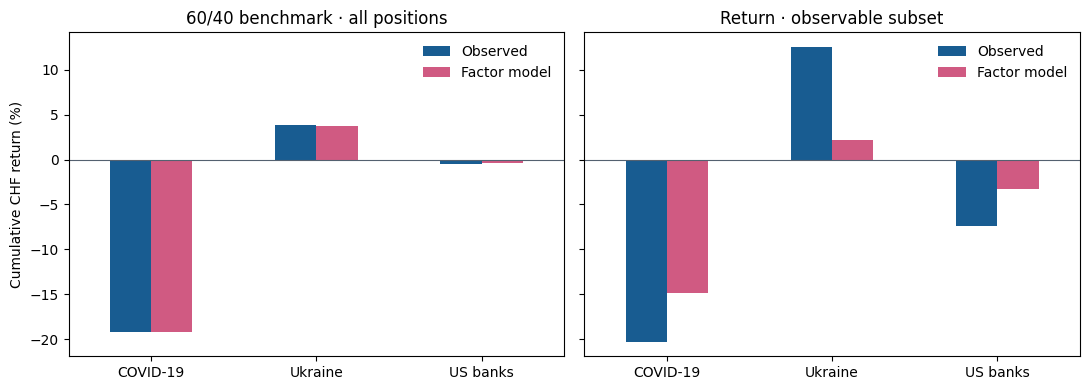

In [62]:
states = pd.DataFrame(stress["episode_counts"]).pivot(index="episode",columns="status",values="instruments").fillna(0)
assert (states.sum(axis=1) == stress["universe"]).all()
display(states)
display(pd.DataFrame(stress["episode_examples"])[["id","episode","return_chf","drawdown","recovery_sessions","status"]].round(3))
replays = pd.DataFrame(stress["replays"])
display(replays[["episode","option","scope","invested_weight","observed","conditional","abnormal"]].round(4))
fig, axes = plt.subplots(1,2,figsize=(11,4),sharey=True)
for ax, name, scope in zip(axes, ["60/40 benchmark","Return"],["All positions","Observable subset"]):
    block = replays[(replays.option==name) & (replays.scope==scope)]
    data = block[["observed","conditional"]].set_axis(["COVID-19","Ukraine","US banks"])
    (100*data).rename(columns={"observed":"Observed","conditional":"Factor model"}).plot.bar(
        ax=ax,color=["#185c91","#d05a82"],rot=0)
    ax.axhline(0,color="#546170",linewidth=.8)
    ax.set_title(name+" · "+scope.lower())
    ax.set_ylabel("Cumulative CHF return (%)")
    ax.set_xlabel("")
    ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(folder/"replays.png",dpi=150,bbox_inches="tight")
plt.show()

### 8.4 · Attribute shock effects to holdings and currencies

- [x] Checked in the project checklist

**Method and tools.** Apply isolated and joint shocks to each position, sum local returns, exact currency translation and their interaction, and reconcile the aggregate. Reprice Treasury coupons and principal from the dated dirty price with a shocked two-point yield curve.

**Result.** All invested positions in the five published portfolios are covered in the joint scenario. Direct repricing is available for 64 of 65 Treasury issues. Portfolio weights, cash, sensitivity intervals and the local-currency decomposition can be compared below.

[Study and reproducible tables](reports/08-chocs/README.md)

scenario,CHF translation,Joint,Oil down,Oil up
option,,,,
60/40 benchmark,4.988,0.424,-0.005,0.005
Diversification,2.588,-1.704,-0.111,0.111
Hedge,2.631,-1.776,-0.035,0.035
Return,2.505,-1.864,-0.098,0.098
Robust,2.505,-1.861,-0.100,0.100


,positions,covered,chf_cash,local_pct,fx_pct,interaction_pct,covered_total_pct,pnl_chf
option,,,,,,,,
60/40 benchmark,2,2,0.0,-4.359,5.0,-0.218,0.424,148.242
Diversification,326,326,0.1,-5.908,4.5,-0.295,-1.704,-596.360
Hedge,135,135,0.1,-5.977,4.5,-0.299,-1.776,-621.438
Return,147,147,0.1,-6.061,4.5,-0.303,-1.864,-652.316
Robust,147,147,0.1,-6.058,4.5,-0.303,-1.861,-651.222


,id,cash_flows,modified_duration,rate_return,linear_rate_return
0,UST:91282CHC8,14,5.6563,-0.0215,-0.0217
1,UST:912810TV0,55,14.1728,-0.0653,-0.0689
2,UST:912810SN9,48,17.6868,-0.0828,-0.0874


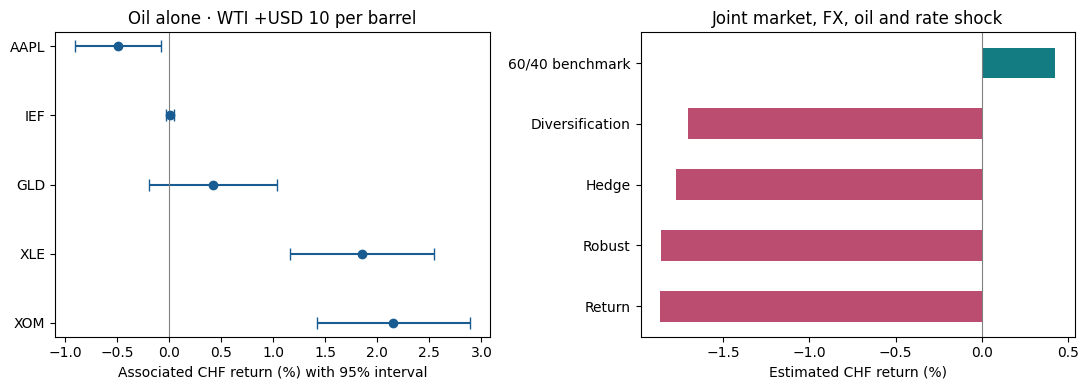

In [63]:
cases = pd.DataFrame(stress["cases"])
joint = cases.query("scenario=='Joint'").set_index("option")
assert ((joint.local_pct+joint.fx_pct+joint.interaction_pct-joint.covered_total_pct).abs()<1e-9).all()
display(cases.pivot(index="option",columns="scenario",values="covered_total_pct").round(3))
display(joint[["positions","covered","chf_cash","local_pct","fx_pct","interaction_pct","covered_total_pct","pnl_chf"]].round(3))
display(pd.DataFrame(stress["bond_examples"])[["id","cash_flows","modified_duration","rate_return","linear_rate_return"]].round(4))
coeff = pd.DataFrame(stress["example_oil_plus10_pct"]).set_index("name").loc[["XOM","XLE","GLD","IEF","AAPL"]]
fig, axes = plt.subplots(1,2,figsize=(11,4))
axes[0].errorbar(coeff.beta,coeff.index,xerr=[coeff.beta-coeff.low,coeff.high-coeff.beta],
                 fmt="o",capsize=4,color="#185c91")
axes[0].set(xlabel="Associated CHF return (%) with 95% interval",title="Oil alone · WTI +USD 10 per barrel")
axes[0].axvline(0,color="gray",linewidth=.8)
joint.covered_total_pct.sort_values().plot.barh(ax=axes[1],color=["#bb4e70" if x<0 else "#137c82" for x in joint.covered_total_pct.sort_values()])
axes[1].axvline(0,color="gray",linewidth=.8)
axes[1].set(xlabel="Estimated CHF return (%)",ylabel="",title="Joint market, FX, oil and rate shock")
fig.tight_layout()
fig.savefig(folder/"exposures.png",dpi=150,bbox_inches="tight")
plt.show()

## 9. Individual US stocks

The security universe, order-size screen, paired ETF comparison, dated financial filings and historical coverage can be inspected independently. Research eligibility and executable orders remain distinct. [Methods, results and figures](reports/09-stocks/README.md)

### 9.1 · Audit the local CRSP extract

- [x] Checked in the project checklist

**Method and tools.** Scan both local CIZ exports with DuckDB, compare compounded daily returns with complete monthly observations, verify stable security IDs and reconcile actual distributions and terminal proceeds.

**Result.** The 2025 return checks cover 46,320 stock-months. The manual cases below show how a dividend, a ticker change and a cash acquisition enter a return series. The 2026 directory was archived before the decision close.

[Stock study](reports/09-stocks/README.md)

In [64]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

stock_folder = Path("reports/09-stocks")
stock_study = json.loads((stock_folder/"results.json").read_text())
stock_audit = stock_study["audit"]
extracts = pd.concat([pd.DataFrame(rows).assign(source=key) for key,rows in stock_audit["raw"].items()])
display(extracts.groupby("source").agg(rows=("rows","sum"),first=("first_date","min"),last=("last_date","max")))
display(extracts.groupby("source").tail(1).set_index("source")[["year","missing_return","missing_price","missing_volume"]])
display(pd.Series(stock_audit["agreement"],name="Daily vs monthly total returns"))
display(pd.Series(stock_audit["dividend"],name="Apple dividend check"))
display(pd.DataFrame(stock_audit["rename"]))
display(pd.Series(stock_audit["exit"],name="Pandion cash acquisition"))
display(pd.Series(stock_study["directory"],name="Listing-screen evidence"))
assert stock_audit["agreement"]["over_1bp"] == 0
assert stock_audit["rename"][0]["permno"] == stock_audit["rename"][1]["permno"]

,rows,first,last
source,,,
Daily,54356930,1998-01-02,2025-12-31
Monthly,2639046,1998-01-30,2025-12-31


,year,missing_return,missing_price,missing_volume
source,,,,
Daily,2025,4917.0,3241.0,NaN
Monthly,2025,193.0,128.0,128.0


year                2025.000000
pairs              46320.000000
securities          4092.000000
median_error_bp        0.008835
p95_error_bp           0.026935
over_1bp               0.000000
Name: Daily vs monthly total returns, dtype: float64

issuer                Apple
dividend               0.25
ex_date          2025-02-10
pay_date         2025-02-13
previous_usd         227.63
close_usd            227.65
reconstructed      0.001186
reported           0.001186
Name: Apple dividend check, dtype: object

,permno,ticker,issuer,day
0,13407,FB,META PLATFORMS INC,2022-05-31
1,13407,META,META PLATFORMS INC,2022-06-30


permno                                                         19567
ticker                                                          PAND
month_end                                                 2021-03-31
terminal_return                                            -0.003322
prior_close                                                     60.2
last_quote                                                     60.05
cash                                                            60.0
completion                                                2021-04-01
source             https://www.merck.com/news/merck-completes-acq...
Name: Pandion cash acquisition, dtype: object

published_utc                                          2026-10-30T00:28:01Z
venues                          {'nasdaq': 4013, 'nyse': 2677, 'amex': 292}
securities_in_snapshot                                                 6982
matched_final_screen_symbols                                           2945
outside_cohort_symbols                                                 3468
us_labelled_outside_cohort                                             1879
ipo_symbols_seen                                                        182
Name: Listing-screen evidence, dtype: object

### 9.2 · Construct a point-in-time stock universe

- [ ] Open in the project checklist

**Method and tools.** Apply the dated listing, history, one-share budget and 1% turnover rules. Compare SPY with SPY plus ten individual stocks over the same 21 sessions in CHF, with identical cash and trading-cost assumptions.

**Evidence and remaining work.** 2,959 stocks pass the CHF 1,575 ticket screen. Nine paired historical windows are complete and the 2026 selection is recorded. The later SPY holdings show how much issuer exposure the ten direct lines duplicate. The full 2026 listing reconciliation and all terminal settlements remain open.

[Stock study](reports/09-stocks/README.md)

,reviewed,model,liquid_affordable,also_pass_final,quoted_at_end
day,,,,,
2017-10-31,3768,3565,3069,1766,1814
2018-10-31,3805,3545,3061,1843,1903
2019-10-31,3787,3578,2973,1913,1962
2020-10-30,3851,3574,3208,2066,2153
2021-10-29,4462,3677,3389,2219,2330
2022-10-31,4564,4216,3487,2373,2470
2023-10-31,4254,4131,3220,2439,2512
2024-10-31,4007,3884,3274,2606,2713
2025-10-31,3843,3697,3380,2786,2946


Pass                                            2959
unmatched                                        518
Turnover limit exceeded                          291
event to verify                                   18
partial                                           17
less than 252 common returns in 504 sessions      14
One share exceeds stock ticket                     5
documented exit                                    2
Name: October 2026 equity records, dtype: int64

Successor or mixed consideration requires tracing    673
Cash included in terminal return                     490
Settlement requires evidence                         267
Name: Terminal records in the monthly extract, dtype: int64

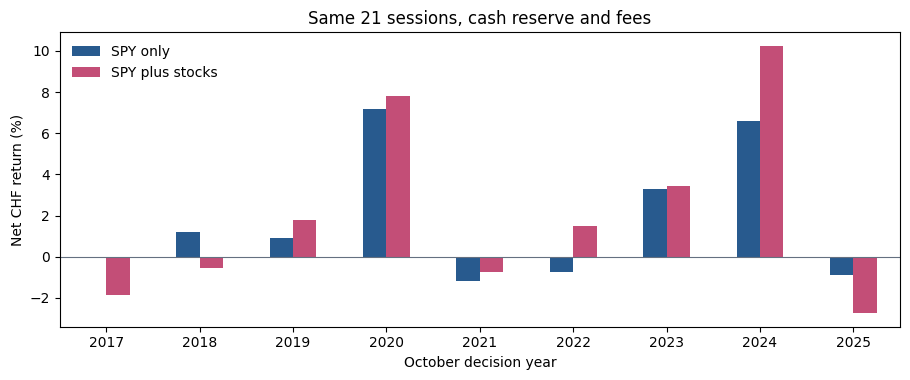

book,SPY only,SPY plus stocks
day,,
2017-10-31,-0.070,-1.844
2018-10-31,1.193,-0.538
2019-10-31,0.886,1.808
2020-10-30,7.189,7.816
2021-10-29,-1.174,-0.747
2022-10-31,-0.725,1.478
2023-10-31,3.312,3.414
2024-10-31,6.612,10.256
2025-10-31,-0.877,-2.753


,direct,through_spy
symbol,,
AMD,4.5,0.52
GOOGL,4.5,2.12
AMZN,4.5,1.83
AAPL,4.5,3.77
META,4.5,0.93
INTC,4.5,0.19
MSFT,4.5,2.71
MU,4.5,0.51
NVDA,4.5,2.29


SPY holdings as of 2026-11-20 · unavailable at the October selection.
2026 selected portfolio status: Horizon beyond frozen market data


In [65]:
screen = pd.DataFrame(stock_study["screen"]).set_index("day")
display(screen)
display(pd.Series(stock_study["current_reasons"],name="October 2026 equity records"))
display(pd.Series(stock_study["terminal_status"],name="Terminal records in the monthly extract"))
books = pd.DataFrame(stock_study["portfolios"])
paired = books.pivot(index="day",columns="book",values="net_return").dropna()*100
assert len(paired)==stock_study["paired"]
ax=paired.set_axis(paired.index.str[:4]).plot.bar(figsize=(9.2,3.9),color=["#285a8e","#c34e77"],rot=0)
ax.axhline(0,color="#647080",linewidth=0.8)
ax.set(xlabel="October decision year",ylabel="Net CHF return (%)",title="Same 21 sessions, cash reserve and fees")
ax.legend(frameon=False)
ax.figure.tight_layout()
ax.figure.savefig(stock_folder/"comparison.png",dpi=150,bbox_inches="tight")
plt.show()
display(paired.round(3))
display(pd.DataFrame(stock_study["mixed_book_overlap"]["issuers"])[["symbol","direct","through_spy"]].set_index("symbol").mul(100).round(2))
print("SPY holdings as of",stock_study["mixed_book_overlap"]["holdings_date"],"· unavailable at the October selection.")
print("2026 selected portfolio status:",books[books.day.eq(stock_study["date"])].reason.iloc[0])

### 9.3 · Add fundamentals after matching identifiers

- [x] Checked in the project checklist

**Method and tools.** Match each SEC accession to a time-valid security and issuer. Keep comparable USD assets and liabilities for each fiscal period. A filing enters the research view on the next US session after both filing and acceptance dates.

**Result.** 2,506 October cohort securities have a verified balance sheet in the source period. Veritone's after-close filing and subsequent amendment illustrate the version rule. The original value survives an as-of lookup before the amendment. The ratio carries zero allocation weight.

[Stock study](reports/09-stocks/README.md)

In [66]:
fund = stock_study["fundamentals"]
display(pd.Series({k:fund[k] for k in ["forms_with_dates","matched_forms","usable_versions","usable_securities","in_final_inventory","in_final_screen","changed_asset_pairs"]}))
versions = pd.DataFrame([fund["original"],fund["later"]]).set_index("form")
display(versions[["ticker","period_end","adsh","accepted_et","available","Assets","Liabilities","liabilities_to_assets"]])
assert versions.period_end.nunique()==1 and versions.available.nunique()==2
assert versions.iloc[0].Assets != versions.iloc[1].Assets
# Optional local lookup by permanent CRSP security ID (Apple here).
stock_archive = Path("data/local/9")/stock_study["archive"]
if (stock_archive/"current_fundamentals.parquet").is_file():
    permno = 14593
    item = pd.read_parquet(stock_archive/"current_fundamentals.parquet",filters=[("permno","=",permno)])
    display(item[["permno","symbol","fundamental_status","adsh","period_end","available","liabilities_to_assets"]])
else:
    print("The published examples above run independently of the private security archive.")

forms_with_dates       20443
matched_forms          10789
usable_versions        19270
usable_securities       2510
in_final_inventory      2506
in_final_screen         2070
changed_asset_pairs      113
dtype: int64

,ticker,period_end,adsh,accepted_et,available,Assets,Liabilities,liabilities_to_assets
form,,,,,,,,
10-Q,VERI,2025-09-30,0001615165-25-000027,2025-11-07T16:42:08-05:00,2025-11-10,200221000.0,184203000.0,0.919998
10-Q/A,VERI,2025-09-30,0001628280-26-025211,2026-04-15T14:19:47-04:00,2026-04-16,198605000.0,183110000.0,0.921981


,permno,symbol,fundamental_status,adsh,period_end,available,liabilities_to_assets
0,14593,AAPL,Dated balance sheet,0000320193-26-000020,2026-06-30,2026-08-03,0.719464


### 9.4 · Audit historical coverage of US stocks

- [x] Checked in the project checklist

**Method and tools.** Count each historical October cohort using its own identifiers, SIC industry and active-price tests. Compare it with the subset still verifiably quoted in October 2026 and with the stricter final ticket screen.

**Result.** The extract supplies 28 October snapshots from 1998 through 2025. Of 3,069 passing stocks in 2017, 1,766 also pass the 2026 screen. The year, sector, exclusion and example records make the effect of filtering visible.

[Stock study](reports/09-stocks/README.md)

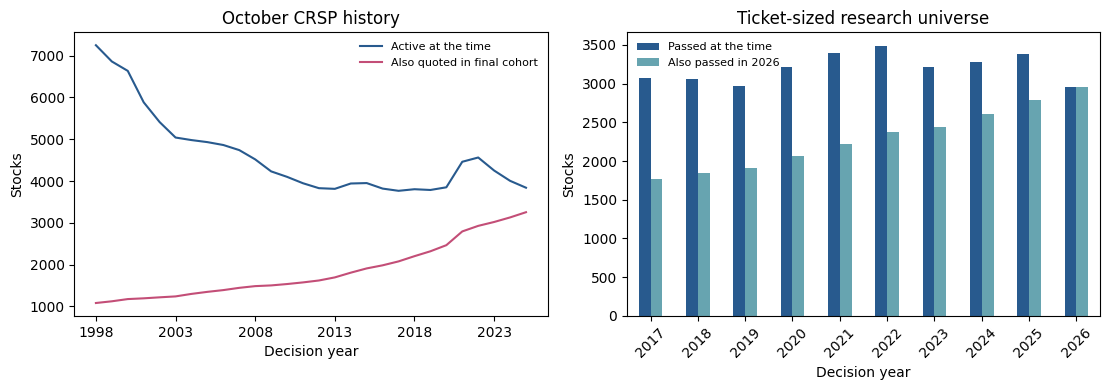

screen_reason,One share exceeds stock ticket,Pass,Turnover limit exceeded,documented exit,event to verify,less than 252 common returns in 504 sessions,partial,unmatched
sector_group,,,,,,,,
Agriculture,0,10,2,0,0,0,0,0
Construction,1,45,1,0,0,0,0,0
Finance and real estate,2,707,54,0,3,1,6,0
Manufacturing,1,1045,110,0,7,2,3,0
Mining,0,104,2,0,0,0,0,0
Public administration,0,1,0,0,0,0,0,0
Retail,1,147,17,0,1,0,0,0
Services,0,610,78,0,5,3,4,0
Transport and utilities,0,186,11,0,1,1,2,0


,day,reason,securities
108,2025-10-31,Non-US or unknown incorporation,1534
109,2025-10-31,Other or missing exchange,3
110,2025-10-31,Other share or security type,5093
111,2025-10-31,US common share in scope,3843


ticker            LBRT
permno           17221
listed      2018-01-12
observed    2018-10-31
Name: entry, dtype: object

ticker             TCF
permno           10375
last        2019-07-31
observed    2018-10-31
Name: exit, dtype: object

permno                         10145
ticker                           HON
day_before                2016-10-31
sector_group_before    Manufacturing
sector_before                   3714
day                       2017-10-31
sector_group               Wholesale
sector                          5099
Name: reclassification, dtype: object

In [67]:
october = pd.DataFrame(stock_study["historical_october"]).set_index("day")
fig,axes=plt.subplots(1,2,figsize=(11.2,4))
october.set_axis(october.index.str[:4])[["active","quoted_at_end"]].rename(columns={
    "active":"Active at the time","quoted_at_end":"Also quoted in final cohort"}).plot(ax=axes[0],color=["#285a8e","#c34e77"])
screen.set_axis(screen.index.str[:4])[["liquid_affordable","also_pass_final"]].rename(columns={
    "liquid_affordable":"Passed at the time","also_pass_final":"Also passed in 2026"}).plot.bar(ax=axes[1],color=["#285a8e","#67a4b0"],rot=45)
for axis,title in zip(axes,["October CRSP history","Ticket-sized research universe"]):
    axis.set(xlabel="Decision year",ylabel="Stocks",title=title)
    axis.legend(frameon=False,fontsize=8)
fig.tight_layout()
fig.savefig(stock_folder/"coverage.png",dpi=150,bbox_inches="tight")
plt.show()
sectors = pd.DataFrame(stock_study["dated_sector_reasons"])
display(sectors[sectors.day.eq(stock_study["date"])].pivot(index="sector_group",columns="screen_reason",values="securities").fillna(0).astype(int))
display(pd.DataFrame(stock_study["extraction_scope"]).tail(4))
for title, example in stock_study["historical_examples"].items():
    display(pd.Series(example,name=title))

## 10. US Treasuries and commodities

The study covers the 65 selected direct issues, uses IEF and TLT for comparison and validates GLD against an independent gold series. WTI remains a factor. [Research report and figures](reports/10-treasuries-gold/README.md)

### 10.1 · Identify the bond data needed for the selected issues

- [x] Checked in the project checklist

**Method and tools.** Match Treasury auction terms, FedInvest clean marks, accrued interest, fund membership and dated buyback awards by CUSIP. Preserve missing execution fields. The issue register is available directly from Git.

**Result.** 64 of 65 issues have a full valuation on 30 October 2026. One note was issued on 2 November. Change the CUSIP below to inspect the price, coupon, duration, original auction lot and latest recorded buyback for any selected issue.

[Methods and evidence](reports/10-treasuries-gold/README.md)

In [68]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

tg_folder = Path("reports/10-treasuries-gold")
tg = json.loads((tg_folder/"results.json").read_text())
issues = pd.DataFrame(json.loads((tg_folder/"issues.json").read_text())).set_index("cusip")
assert len(issues)==tg["issues"] and issues.dirty.count()==tg["valued"]
display(issues.groupby("type").agg(screened=("coupon_pct","size"),priced=("dirty","count"),
                                  modelled=("model","sum"),observed_buybacks=("operation_date","count")))
cusip = "91282CHC8"
display(issues.loc[cusip,["issue","coupon_pct","maturity","last_mark","clean","accrued","dirty","yield",
                         "duration","convexity","dv01_per_100","auction_min_face","auction_increment",
                         "operation_date","settlement_date","last_buyback_accepted_usd","gate"]])
display(issues[issues.dirty.isna()][["issue","maturity","gate"]])

,screened,priced,modelled,observed_buybacks
type,,,,
Bond,48,48,44,34
Note,17,16,10,11


issue                                         2023-05-15
coupon_pct                                         3.375
maturity                                      2033-05-15
last_mark                                     2026-10-30
clean                                           92.03125
accrued                                         1.540761
dirty                                          93.572011
yield                                           0.048082
duration                                        5.661629
convexity                                      37.554333
dv01_per_100                                    0.052977
auction_min_face                                     100
auction_increment                                    100
operation_date                                2026-08-25
settlement_date                               2026-08-26
last_buyback_accepted_usd                    123000000.0
gate                         No verified executable size
Name: 91282CHC8, dtype: object

,issue,maturity,gate
cusip,,,
91282CRV5,2026-11-02,2033-10-31,Not issued


### 10.2 · Calculate bond value and interest-rate risk

- [x] Checked in the project checklist

**Method and tools.** Discount each contractual cash flow using the actual semiannual accrual period. Reconcile against an independent auction price, compute DV01, duration and convexity, and reprice rate, spread and exchange-rate shocks. Compare coupon-inclusive direct returns and ETF returns on matched endpoints.

**Result.** The 3.375% note reproduces the official reopening price to six decimals. At the decision date a 100 bp yield rise costs 5.48%; a 100 bp fall adds 5.85%. Direct return coverage and ETF comparisons are reported beside the shock results.

[Methods and evidence](reports/10-treasuries-gold/README.md)

auction             2023-06-12
issue_settlement    2023-06-15
auction_yield          0.03791
previous_coupon     2023-05-15
next_coupon         2023-11-15
coupon_per100           1.6875
fraction_left         0.831522
accrued_per100        0.284307
clean_official       96.583639
clean_calculated     96.583639
dirty_per100         96.867946
dtype: object

,local,approx_local,fx,interaction,chf
scenario,,,,,
Rates up,-5.4783,-5.4739,0.0,0.0000,-5.4783
Rates down,5.8540,5.8494,0.0,0.0000,5.8540
Spread only,-1.4037,-1.4037,0.0,0.0000,-1.4037
FX only,0.0000,0.0000,-5.0,0.0000,-5.0000
Joint,-6.7923,-6.7836,-5.0,0.3396,-11.4527


,issues,measured,min_duration,max_duration,median_convexity,max_approx_error_bp
type,,,,,,
Bond,48,48,7.433373,17.717334,314.240369,26.949031
Note,17,16,5.661629,7.697524,51.125724,2.290041


,issues,complete,median_direct_chf,fund_chf
fund,,,,
IEF,18,11,0.012705,0.010255
TLT,47,43,-0.026882,-0.027557


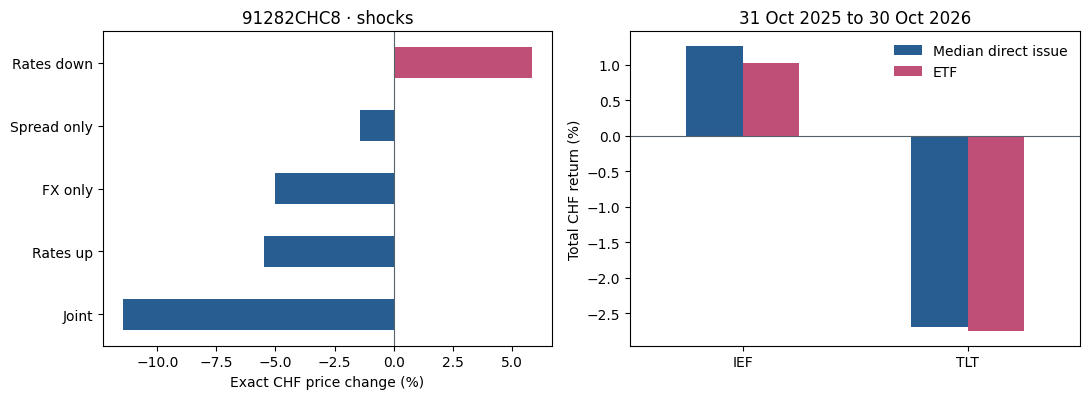

In [69]:
auction=tg["auction_replay"]
display(pd.Series({k:auction[k] for k in ["auction","issue_settlement","auction_yield","previous_coupon","next_coupon",
                                         "coupon_per100","fraction_left","accrued_per100","clean_official","clean_calculated","dirty_per100"]}))
assert abs(auction["clean_calculated"]-auction["clean_official"])<1e-6
scenarios=pd.DataFrame(tg["example_shocks"]).set_index("scenario")
display(scenarios[["local","approx_local","fx","interaction","chf"]].mul(100).round(4))
display(pd.DataFrame(tg["risk_ranges"]).set_index("type"))
matched=pd.DataFrame(tg["comparison"]["by_fund"]).set_index("fund")
display(matched)
fig,axes=plt.subplots(1,2,figsize=(11,4.1))
s=(scenarios.chf*100).sort_values()
s.plot.barh(ax=axes[0],color=["#275d91" if x<0 else "#c04f78" for x in s])
axes[0].axvline(0,color="#55616b",lw=.8)
axes[0].set(ylabel="",xlabel="Exact CHF price change (%)",title=cusip+" · shocks" if cusip==auction["example"] else auction["example"]+" · shocks")
(matched[["median_direct_chf","fund_chf"]].rename(columns={"median_direct_chf":"Median direct issue","fund_chf":"ETF"})*100).plot.bar(ax=axes[1],color=["#275d91","#c04f78"],rot=0)
axes[1].axhline(0,color="#55616b",lw=.8)
axes[1].set(xlabel="",ylabel="Total CHF return (%)",title="31 Oct 2025 to 30 Oct 2026")
axes[1].legend(frameon=False)
fig.tight_layout()
fig.savefig(tg_folder/"bond-risk.png",dpi=150,bbox_inches="tight")
plt.show()

### 10.3 · Validate the selected investable commodity exposure

- [x] Checked in the project checklist

**Method and tools.** Cross-check GLD daily closes against its issuer. Compare changes in monthly-average USD prices with the World Bank gold series, and measure actual month-end holding returns in USD and CHF. Check tracking before and after the June 2025 benchmark change.

**Result.** The comparison covers 262 common months. The ten-year correlation is 0.9982 and annualized tracking error is 0.74%. Fund expenses, fixing times and currency matter. The WTI sensitivity stays in the separate oil-factor study.

[Methods and evidence](reports/10-treasuries-gold/README.md)

,start,end,months,fund_avg_price_change,spot_avg_price_change,gld_close_total_usd,gld_close_total_chf
period,,,,,,,
1 year,2025-10-31,2026-10-30,12,0.0082,0.0116,-0.0335,-0.0091
3 years,2023-10-31,2026-10-30,36,1.1169,1.1425,0.9326,0.7479
5 years,2021-10-29,2026-10-30,60,1.2650,1.3101,1.1349,0.9171
10 years,2016-10-31,2026-10-30,120,2.1166,2.2399,1.9177,1.4279


,months,pearson,mean_gap_bp_month,tracking_error_annual
period,,,,
Through May 2025,244,0.997414,-3.726581,0.009417
From July 2025,16,0.999669,-3.032715,0.005322


validated_closes           5491.000000
common_months               262.000000
expense_ratio                 0.004000
ounces_per_share_change      -0.083068
last_close_nav_gap           -0.007963
dtype: float64

WTI is a factor measured in USD/barrel · observed negative-price days: 1


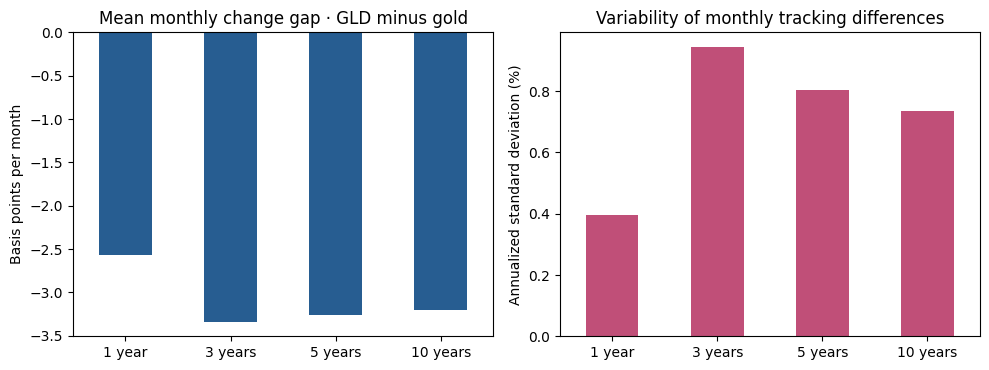

In [70]:
gold=tg["gold"]
gold_windows=pd.DataFrame(gold["windows"]).set_index("period")
display(gold_windows[["start","end","months","fund_avg_price_change","spot_avg_price_change","gld_close_total_usd","gld_close_total_chf"]].round(4))
display(pd.DataFrame(gold["regimes"]).set_index("period"))
display(pd.Series({k:gold[k] for k in ["validated_closes","common_months","expense_ratio","ounces_per_share_change","last_close_nav_gap"]}))
print("WTI is a factor measured in", gold["wti"]["unit"],"· observed negative-price days:",gold["wti"]["negative_days"])
fig,axes=plt.subplots(1,2,figsize=(10,3.8))
(gold_windows.mean_gap_bp_month).plot.bar(ax=axes[0],rot=0,color="#275d91")
axes[0].set(xlabel="",ylabel="Basis points per month",title="Mean monthly change gap · GLD minus gold")
(gold_windows.tracking_error_annual*100).plot.bar(ax=axes[1],rot=0,color="#c04f78")
axes[1].set(xlabel="",ylabel="Annualized standard deviation (%)",title="Variability of monthly tracking differences")
fig.tight_layout()
fig.savefig(tg_folder/"gold-tracking.png",dpi=150,bbox_inches="tight")
plt.show()

### 10.4 · Test tradability for bonds with irregular quotes

- [x] Checked in the project checklist

**Method and tools.** Separate an indicative price from an observed transaction and an executable retail quote. Replay the settlement cash, coupon and principal. Challenge the lot size, stale marks, account access and a deposit arriving after settlement.

**Result.** A funded illustrative auction purchase debits USD 968.68 for USD 1,000 face. The cash arrives too late in a separate rejected case. The isolated matured issue leaves zero face after redemption. The client gate admits zero orders.

[Methods and evidence](reports/10-treasuries-gold/README.md)

In [71]:
display(pd.Series(tg["stale_case"],name="Stale-price control"))
display(pd.Series(tg["buybacks"]["recent_example"],name="Dated institutional buyback"))
display(pd.Series(auction["gate_tests"],name="Access and funding decisions"))
display(pd.DataFrame(auction["cash_ledger"]))
display(pd.Series(auction["matured_control"],name="Independent matured-note control"))
display(pd.DataFrame(tg["fallbacks"]))
assert tg["live_orders"]==0
assert auction["cash_ledger"][-1]["remaining_face"]==0

cusip                         91282CHC8
check                        2026-10-12
last_mark                    2026-10-09
decision     Missing or stale valuation
Name: Stale-price control, dtype: object

cusip_nbr              912810SX7
operation_date        2026-10-27
settlement_date       2026-10-28
accepted_usd        1014000000.0
weighted_price            59.011
clean                     59.125
price_gap_per100          -0.114
Name: Dated institutional buyback, dtype: object

Funded auction example    Funded on settlement date
Odd lot                                 Invalid lot
Cash after settlement      Insufficient settled USD
Client account                   Unverified account
Name: Access and funding decisions, dtype: object

,cusip,day,event,change_usd,balance_usd,remaining_face
0,91282CHC8,2023-06-15,Funded purchase settlement,-968.68,31.32,1000.0
1,91282CHC8,2023-11-15,First coupon after purchase,16.88,48.20,1000.0
2,91282CHY0,2026-09-15,"Separate maturity control, zero opening cash",1023.13,1023.13,0.0


cusip                      91282CHY0
last_mark_day             2026-09-14
last_clean                     100.0
pay                       2026-09-15
face                            1000
coupon_unrounded              23.125
principal                     1000.0
projected_cash_rounded       1023.13
maturity_mark                   None
Name: Independent matured-note control, dtype: object

,mandate,research,access
0,Exact dated USD principal,Selected direct issue with matching maturity,No executable secondary terms or account
1,Treasury duration exposure,Compare IEF or TLT with matched duration and C...,No verified fund order on the account
2,Near-term CHF payment,Keep already settled CHF available for the dat...,Conditional on actual cash balance; no trade a...


## 11. Environmental preferences

The October market model supplies risk, return and cost estimates. The November review supplies dated issuer look-through. P07 and P08 distinguish mandatory exclusions from flexible preferences. [Results, coverage and figures](reports/11-environment/README.md)

### 11.1 · Choose measurable environmental criteria

- [x] Checked in the project checklist

**Method and tools.** Verify security identifiers and ETF publication dates, then aggregate direct and indirect issuer weights. Reconcile EPA parent ownership, link issuers to SEC filings and divide attributable 2023 US point-source emissions by consolidated revenue in USD millions. Report measurement coverage as a fraction of capital.

**Result.** Published XLE holdings show 18.75% Chevron. The earlier snapshot leaves the fund's issuer exposure unknown. The carbon-intensity study measures 54 issuers. Change the parent name below to check its numerator, denominator and filing.

[Source method and scope](reports/11-environment/README.md) · [Issuer calculations](reports/11-environment/issuers.json)

,3M CO
cik,66740
adsh,0000066740-26-000014
accepted_utc,2026-02-03T21:14:00Z
tag,Revenues
facilities,11
tonnes,1007143.688924
revenue,24610000000.0
intensity,40.924165


,Known Chevron (%),Gross unidentified (%),Measured carbon weight (%),mandatory,soft,ask
case,,,,,,
Chevron directly,100.00,0.00,0.00,excluded,preference not satisfied,excluded
XLE before publication,0.00,100.00,0.00,suspended,unverified comparison only,clarification required
XLE after publication,18.75,0.65,19.55,excluded,preference not satisfied,excluded
SPY after publication,0.69,0.19,10.82,excluded,preference not satisfied,excluded
"Half Chevron, half XLE",59.37,0.32,9.77,excluded,preference not satisfied,excluded
GLD without issuer file,0.00,100.00,0.00,suspended,unverified comparison only,clarification required
Direct US Treasury,0.00,0.00,0.00,verified,verified,verified


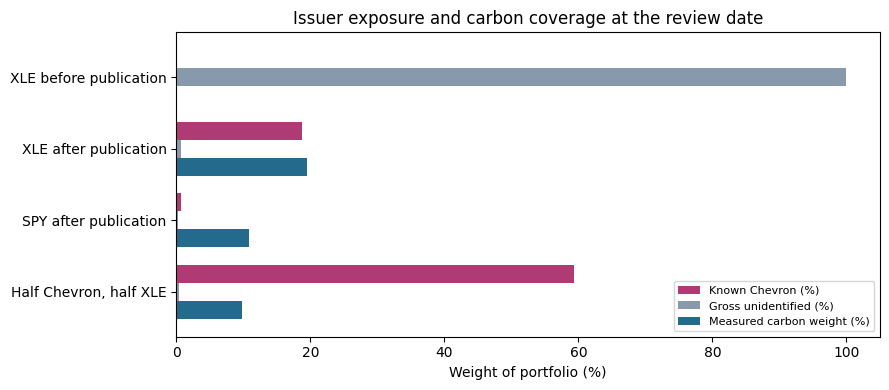

In [72]:
env_dir = Path("reports/11-environment")
env = json.loads((env_dir / "results.json").read_text())
issuers = pd.DataFrame(json.loads((env_dir / "issuers.json").read_text())).set_index("parent")
parent = "3M CO"
example = issuers.loc[parent]
assert np.isclose(example.tonnes / (example.revenue / 1e6), example.intensity)
display(example.to_frame(name=parent))
controls = pd.DataFrame(env["controls"]).set_index("case")
fields = ["forbidden", "unknown_gross", "covered"]
table = controls[fields].mul(100).round(2)
table.columns = ["Known Chevron (%)", "Gross unidentified (%)", "Measured carbon weight (%)"]
display(table.join(controls[["mandatory", "soft", "ask"]]))
fig, ax = plt.subplots(figsize=(9, 4))
selection = table.loc[["XLE before publication", "XLE after publication", "SPY after publication", "Half Chevron, half XLE"]]
selection.plot.barh(ax=ax, color=["#ae3b73", "#8799ab", "#246a8c"], width=.75)
ax.set(xlabel="Weight of portfolio (%)", ylabel="", title="Issuer exposure and carbon coverage at the review date")
ax.invert_yaxis()
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()
fig.savefig(env_dir / "issuer-coverage.png", dpi=150, bbox_inches="tight")
plt.show()

### 11.2 · Test decisions under environmental constraints

- [x] Checked in the project checklist

**Method and tools.** Optimize four portfolios with CVXPY and Clarabel, starting each in CHF cash with a 12% risk ceiling and equal unit trading costs. The first comparison excludes Chevron and unresolved issuers. The second imposes a relative intensity ceiling with 60% of capital in measured stocks for both portfolios.

**Result.** Full issuer verification removes 62.23% unresolved exposure from the reference portfolio. In the measured-stock comparison, a 20% lower intensity costs 0.059 percentage point of estimated annual net return. Differences in carbon coverage prevent a corresponding carbon ranking of the full-universe pair.

[Portfolio comparisons and input fingerprints](reports/11-environment/results.json) · [Optimization procedure](src/riskmatch_v2/environment/study.py)

Estimated net (%)  Volatility (%)  \
Mandate                Option                                         
Chevron exclusion      reference             43.706            12.0   
                       variant               31.273            12.0   
Point-source intensity reference             18.095            12.0   
                       variant               18.036            12.0   

                                  Fee (CHF)  Measured weight (%)  \
Mandate                Option                                      
Chevron exclusion      reference       31.5                7.616   
                       variant         31.5               12.698   
Point-source intensity reference       21.0               60.000   
                       variant         21.0               60.000   

                                  Intensity on measured holdings  
Mandate                Option                                     
Chevron exclusion      reference                          30.106  
                       variant                            54.798  
Point-source intensity reference                         141.284  
                       variant                           113.028

Chevron exclusion · Partial or unequal coverage · estimated net change -12.433 percentage points
Point-source intensity · Lower measured intensity · estimated net change -0.059 percentage points


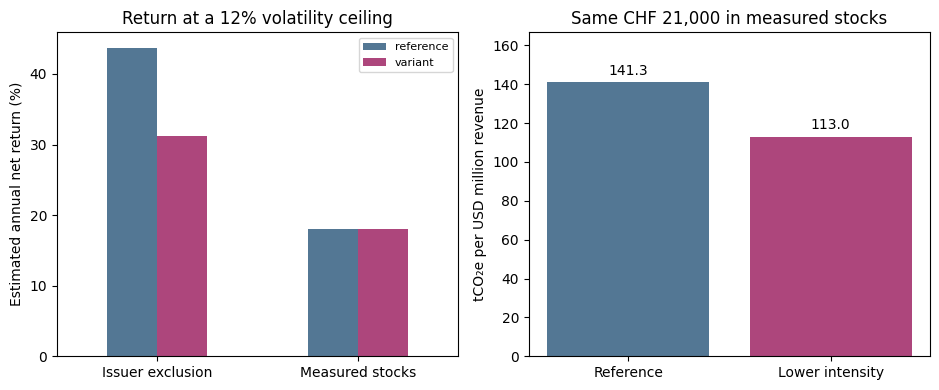

In [73]:
env_rows = []
for pair in env["pairs"]:
    for role in ["reference", "variant"]:
        row = pair[role]
        env_rows.append({"Mandate": pair["criterion"], "Option": role,
                         "Estimated net (%)": 100 * row["net"], "Volatility (%)": 100 * row["risk"],
                         "Fee (CHF)": row["fee_chf"], "Measured weight (%)": 100 * row["covered"],
                         "Intensity on measured holdings": row["intensity"]})
env_table = pd.DataFrame(env_rows).set_index(["Mandate", "Option"])
display(env_table.round(3))
for pair in env["pairs"]:
    print(pair["criterion"], "·", pair["intensity_comparison"],
          f"· estimated net change {100 * pair['change']['net']:+.3f} percentage points")
base, variant = (env["pairs"][1][role] for role in ["reference", "variant"])
assert np.isclose(base["covered"], variant["covered"])
assert np.isclose(variant["intensity"] / base["intensity"], .8)
fig, axes = plt.subplots(1, 2, figsize=(9.5, 4))
colors = ["#537794", "#ad467c"]
env_table["Estimated net (%)"].unstack().plot.bar(ax=axes[0], rot=0, color=colors)
axes[0].set(xlabel="", ylabel="Estimated annual net return (%)", title="Return at a 12% volatility ceiling")
axes[0].set_xticklabels(["Issuer exclusion", "Measured stocks"])
axes[0].legend(title="", fontsize=8)
bars = axes[1].bar(["Reference", "Lower intensity"], [base["intensity"], variant["intensity"]], color=colors)
axes[1].bar_label(bars, fmt="%.1f", padding=3)
axes[1].set(ylabel="tCO₂e per USD million revenue", title="Same CHF 21,000 in measured stocks", ylim=(0, base["intensity"] * 1.18))
fig.tight_layout()
fig.savefig(env_dir / "mandate-comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## 12. Forecasts and signal validation

The dated SPY study tests eight signals on monthly-length return and two variance horizons. The five multi-asset portfolio notices use their own weights and stresses. [Report and figures](reports/12-forecasts/README.md)

### 12.1 · Freeze the forecast evaluation protocol

- [x] Checked in the project checklist

**Method and tools.** Set the target, horizon, calendar, publication rule, loss and funded criterion before the experiment. Check the retained forecasts' feature dates and target endpoints.

**Result.** Validation spans 2015–2020 and the final period starts in 2021. The final study contains 69 non-overlapping 21-session outcomes and 22 at 63 sessions.

[Methods, evidence and limitations](reports/12-forecasts/README.md)

In [74]:
fcdir = Path("reports/12-forecasts")
policy12 = json.loads(Path("config/forecasts-12.json").read_text())
fc = json.loads((fcdir/"results.json").read_text())
experiments = pd.json_normalize(json.loads((fcdir/"experiments.json").read_text()))
registry12 = pd.read_json(fcdir/"registry.json", convert_dates=False)
paths12 = {key: pd.read_csv(fcdir/f"{key}-predictions.csv") for key in ("return-21","variance-21","variance-63")}
for key, dated in paths12.items():
    assert (dated.cut < dated.decision).all() and (dated.decision < dated.end).all()
    assert dated.loc[dated.block=="validation","end"].max() < policy12["final_start"]
display(pd.DataFrame({k:v.groupby("block").size() for k,v in paths12.items()}))
display(pd.Series(policy12["targets"], name="Frozen measurement"))

,return-21,variance-21,variance-63
block,,,
final,69,69,22
validation,70,70,23


variance       Mean future squared CHF SPY return over 21 and...
return         21-session cumulative CHF SPY excess return ab...
event          SPY in CHF loses at least 5% from entry close ...
interval       Central 80% interval for the same 21-session C...
overheating    Monthly end-of-month USD closes on SPY, GLD an...
Name: Frozen measurement, dtype: object

### 12.2 · Prepare the signals

- [x] Checked in the project checklist

**Method and tools.** Join the dated VIX close, Treasury slope, unemployment vintages, lagged price and volume, geopolitical editions and Fed statement tone. Keep publication and observation dates separate.

**Result.** The corpus contains 176 distinct Fed statements. The conservative GPR archive begins in October 2021, after the validation block. The raw texts stay local and the public manifest preserves dates, scores and fingerprints.

[Methods, evidence and limitations](reports/12-forecasts/README.md)

In [75]:
display(pd.Series(fc["features"],name="Source coverage"))
display(pd.Series(fc["release_controls"],name="Publication controls"))
statements = pd.read_json(fcdir/"fomc-releases.json",convert_dates=False)
assert statements.sha256_text.is_unique
display(statements[["published_day","available","words","tone"]].tail(4))

statements                     176
gpr_editions                    60
tone_start              2006-01-31
tone_end                2026-10-28
gpr_start               2021-10-31
gpr_end                 2026-10-31
training_statements             78
macro_vintages                 262
revised_observations           156
Name: Source coverage, dtype: object

prior_release                                                         1.0
first_after_revision                                                  9.0
unique_from_three                                                       2
local_closes_utc        [2020-10-30 20:00:00+00:00, 2020-11-02 21:00:0...
Name: Publication controls, dtype: object

,published_day,available,words,tone
172,2026-06-17,2026-06-18T03:59:00+00:00,131,1.526718
173,2026-07-29,2026-07-30T03:59:00+00:00,132,1.515152
174,2026-09-16,2026-09-17T03:59:00+00:00,131,1.526718
175,2026-10-28,2026-10-29T03:59:00+00:00,140,2.142857


### 12.3 · Compare forecast models

- [x] Checked in the project checklist

**Method and tools.** Compare rolling variance, EWMA, GARCH and fixed-alpha Ridge. For return views compare the posterior with the prior using validation-only view uncertainty.

**Result.** The VIX-based Black–Litterman view yields the same final funded wealth as the prior. GARCH and EWMA have positive mean final 21-session QLIKE gains but fail the full test.

[Methods, evidence and limitations](reports/12-forecasts/README.md)

A separate descriptive transfer audit records eight signal attempts for each of 3,902 instruments and three targets. Every missing history remains in the denominator. [Coverage by signal and class](reports/12-forecasts/cross-asset.json)

,validation.gain,final.gain,final.mse,research_pass
model,,,,
ewma,0.163244,0.039142,3.380412e-08,False
garch,0.202797,0.060805,3.556992e-08,False
alone_realized,0.199718,0.080451,2.385579e-08,False
increment_realized,-0.094933,-0.031681,3.007217e-08,False


candidate                 increment_vix
P                                 [[1]]
omega                          0.002326
prior_uncertainty_last         0.000011
zero_confidence                    0.01
deployed                          False
dtype: object

,reference_book,candidate_book
terminal_chf,54034.0178,54034.0178
fees_chf,114.3326,114.3326
frequency,0.1449,0.1449
mean_excess,0.0059,0.0059


,target,horizon,inventory,At least eight paired final outcomes,any_positive
0,return,21,3902,3572,2204
1,variance,21,3902,3568,898
2,variance,63,3902,2402,2127


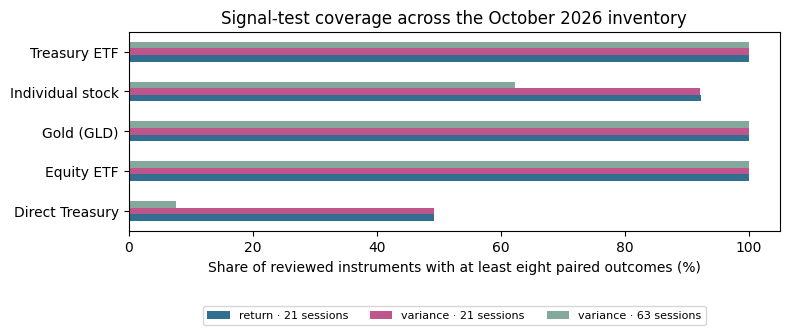

In [76]:
v21 = experiments.query("target=='variance' and horizon==21").set_index("model")
display(v21.loc[["ewma","garch","alone_realized","increment_realized"],["validation.gain","final.gain","final.mse","research_pass"]])
bl12 = fc["black_litterman"]
display(pd.Series({k:bl12[k] for k in ["candidate","P","omega","prior_uncertainty_last","zero_confidence","deployed"]}))
display(pd.DataFrame({k:bl12["final"][k] for k in ["reference_book","candidate_book"]}).round(4))
transfer12=json.loads((fcdir/"cross-asset.json").read_text())
by_class12=pd.DataFrame(transfer12["by_class"])
display(pd.DataFrame(transfer12["by_target"]).rename(columns={"with_eight":"At least eight paired final outcomes"}))
by_class12["Coverage (%)"]=100*by_class12.with_eight/by_class12.inventory
by_class12["Target"]=by_class12.target+" · "+by_class12.horizon.astype(str)+" sessions"
ax=by_class12.pivot(index="class",columns="Target",values="Coverage (%)").plot.barh(figsize=(8,4),color=["#316e90","#be558b","#84a89b"])
ax.set(xlabel="Share of reviewed instruments with at least eight paired outcomes (%)",ylabel="",title="Signal-test coverage across the October 2026 inventory")
ax.legend(title="",fontsize=8,loc="lower center",bbox_to_anchor=(.5,-.5),ncol=3)
ax.figure.tight_layout()
ax.figure.savefig(fcdir/"cross-asset-coverage.png",dpi=150,bbox_inches="tight")
plt.show()

### 12.4 · Test market overheating indicators

- [x] Checked in the project checklist

**Method and tools.** Replay six-month price alerts and 60-month right-tailed ADF windows on SPY, GLD and IEF. Count subsequent 10% losses, false alerts and censoring. Compare adjusted and unadjusted tests.

**Result.** GLD triggered six adjusted alerts with complete follow-up in the final block. Two preceded the specified decline. Across the other two funds the adjusted rule never triggered on a mature final date.

[Methods, evidence and limitations](reports/12-forecasts/README.md)

In [77]:
heat12 = fc["overheating"]
hs = pd.DataFrame(heat12["summary"])
display(hs[["asset","rule","evaluated","alerts","false_alerts","misses","delay_months"]])
months12 = pd.read_json(fcdir/"overheating-months.json",convert_dates=False)
display(months12.query("adjusted and mature and month >= '2021-01'")[["asset","month","bsadf","hit","delay"]])
print("Basket critical value",round(heat12["basket_critical"],3),"· independent null exceedance",heat12["independent_null_exceedance"])

,asset,rule,evaluated,alerts,false_alerts,misses,delay_months
0,SPY,simple,64,4,4,8,[]
1,GLD,simple,64,13,10,5,"[5, 1, 3]"
2,IEF,simple,64,0,0,6,[]
3,SPY,raw,64,0,0,8,[]
4,GLD,raw,64,8,5,5,"[5, 1, 3]"
5,IEF,raw,64,3,3,6,[]
6,SPY,adjusted,64,0,0,8,[]
7,GLD,adjusted,64,6,4,6,"[5, 1]"
8,IEF,adjusted,64,0,0,6,[]


,asset,month,bsadf,hit,delay
392,GLD,2025-09,2.016350,0.0,NaN
393,GLD,2025-10,2.096107,0.0,NaN
394,GLD,2025-11,2.328453,0.0,NaN
395,GLD,2025-12,2.254866,0.0,NaN
396,GLD,2026-01,2.951327,1.0,5.0
397,GLD,2026-02,3.391294,1.0,1.0


Basket critical value 1.899 · independent null exceedance 0.02


### 12.5 · Define acceptance criteria for signals

- [x] Checked in the project checklist

**Method and tools.** Use paired losses, a moving-block bootstrap and a funded CHF replay with entry, rebalancing and liquidation fees. Positive gains must survive two periods and meet the economic objective.

**Result.** The 63-session momentum model improves final QLIKE by 0.0849, yet its funded exposure exceeds the risk ceiling three times against two for the reference.

[Methods, evidence and limitations](reports/12-forecasts/README.md)

,validation.gain,final.gain,final.ci,final.reference_book.frequency,final.candidate_book.frequency,research_pass
model,,,,,,
increment_momentum,0.088023,0.084875,"[0.025602082883832512, 0.18996011413442412]",0.090909,0.136364,False
increment_tone,0.040829,-0.011470,"[-0.04057624796835322, 0.014781260381067213]",0.090909,0.090909,False
garch,0.134308,0.100997,"[-0.012591707085857723, 0.3423420110999877]",0.090909,0.181818,False
ewma,0.109612,0.040307,"[-0.08801604056608855, 0.2684010937335734]",0.090909,0.136364,False


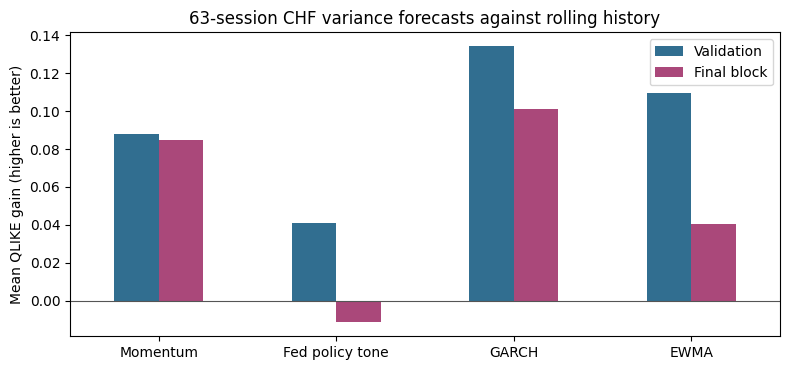

In [78]:
v63 = experiments.query("target=='variance' and horizon==63").set_index("model")
selected = v63.loc[["increment_momentum","increment_tone","garch","ewma"]]
display(selected[["validation.gain","final.gain","final.ci","final.reference_book.frequency","final.candidate_book.frequency","research_pass"]])
fig, ax = plt.subplots(figsize=(8,3.8))
plot12=selected[["validation.gain","final.gain"]].copy()
plot12.index=["Momentum","Fed policy tone","GARCH","EWMA"]
plot12.columns=["Validation","Final block"]
plot12.plot.bar(ax=ax,rot=0,color=["#316e90","#aa487a"])
ax.axhline(0,color="#555",lw=.8)
ax.set(title="63-session CHF variance forecasts against rolling history",xlabel="",ylabel="Mean QLIKE gain (higher is better)")
fig.tight_layout()
fig.savefig(fcdir/"forecast-gains.png",dpi=150,bbox_inches="tight")
plt.show()

### 12.6 · Display each signal and combine evidence for each forecast target

- [x] Checked in the project checklist

**Method and tools.** Keep each signal's direction and strength visible. Check its target, validation evidence, correlation with other candidates and final contribution before combining.

**Result.** The two variance candidates that passed validation at 63 sessions have forecast correlation 0.985. Redundancy filtering retains momentum alone. Its final funded test fails and every effective recommendation weight is zero.

[Methods, evidence and limitations](reports/12-forecasts/README.md)

In [79]:
mix12=fc["combinations"]["variance-63"]
display(pd.DataFrame(mix12["correlations"]).round(3))
display(registry12.query("target=='variance' and horizon==63 and name.str.startswith('increment_')",engine="python")[["family","name","input","reference","estimate","direction","weight","reason"]])
print("Combination gain against best",mix12["combination_against_best"]["gain"])
print("Opposed opinions (fixture)",fc["registry_controls"]["opposed"])
print("Missing input fallback (fixture)",fc["registry_controls"]["missing"])

,increment_momentum,increment_tone
increment_momentum,1.000,0.985
increment_tone,0.985,1.000


,family,name,input,reference,estimate,direction,weight,reason
37,Quantitative,increment_realized,-9.855148,0.000051,0.000057,above,0,Validation: Statistical or coverage gate
39,Quantitative,increment_momentum,0.140174,0.000051,0.000069,above,0,Final: Economic gate
41,Quantitative,increment_liquidity,-0.235589,0.000051,0.000042,below,0,Validation: Statistical or coverage gate
43,Market,increment_vix,17.200000,0.000051,0.000052,above,0,Validation: Statistical or coverage gate
45,Macro,increment_curve,0.320000,0.000051,0.000050,below,0,Validation: Insufficient paired outcomes
47,Macro,increment_unemployment,4.100000,0.000051,0.000053,above,0,Validation: Statistical or coverage gate
49,Sentiment,increment_tone,2.142857,0.000051,0.000052,above,0,Final: Statistical or coverage gate
51,Geopolitical,increment_gpr,117.918846,0.000051,NaN,unavailable,0,Validation: Insufficient paired outcomes


Combination gain against best 0.0
Opposed opinions (fixture) [0.004999999999999999, {'a': 0.015, 'b': -0.01}]
Missing input fallback (fixture) [0.005, {}]


### 12.7 · Link risk assessments to verifiable actions

- [x] Checked in the project checklist

**Method and tools.** Estimate the two horizon risk scales for each portfolio from its own holdings. Compare conditional oil, yield and FX exposures, fee effects and client-specific funding gaps.

**Result.** The Return portfolio has a 4.67% historical risk scale at 21 sessions and 8.08% at 63. Its joint scenario implies about CHF 652 of loss. Client A's protected bill and longer-term funding target have different exposures.

[Methods, evidence and limitations](reports/12-forecasts/README.md)

In [80]:
portfolio12=pd.DataFrame([{"Portfolio":p["name"],"Previous annual risk (%)":100*p["previous_annual_reference"] if p["previous_annual_reference"] is not None else None,
    "Current annual risk (%)":100*p["notices"][0]["annual_vol"],
    "21-session risk (%)":100*p["notices"][0]["horizon_rms"],"63-session risk (%)":100*p["notices"][1]["horizon_rms"],
    "Oil +10 (CHF)":p["oil_up_chf"],"Rate shock (CHF)":p["rates_chf"],"FX +5% (CHF)":p["fx_up_chf"],"Joint (CHF)":p["joint_chf"]} for p in fc["portfolios"]])
display(portfolio12.set_index("Portfolio").round(2))
display(pd.DataFrame(fc["funding"]).round(2))
case12=next(p for p in fc["portfolios"] if p["name"]=="Return")
display(pd.Series(case12["rising_risk_control"],name="Fixed-weight rising-volatility example"))
assert fc["funding"]["A"]["missed_scheduled_payments_after_shock"] == 0

,Previous annual risk (%),Current annual risk (%),21-session risk (%),63-session risk (%),Oil +10 (CHF),Rate shock (CHF),FX +5% (CHF),Joint (CHF)
Portfolio,,,,,,,,
60/40 benchmark,9.57,8.15,2.35,4.07,1.68,-471.02,1745.71,148.24
Diversification,15.22,14.56,4.20,7.28,38.69,-548.80,905.95,-596.36
Hedge,16.61,16.08,4.64,8.04,12.32,-730.73,920.99,-621.44
Return,16.17,16.16,4.67,8.08,34.44,-698.10,876.81,-652.32
Robust,16.16,16.14,4.66,8.07,34.87,-694.35,876.65,-651.22


,A,B
flat_market,15057.63,40085.68
immediate_30pct_loss,23692.88,52924.62
constant_5pct_asset_growth,10520.52,32322.42
missed_scheduled_payments_flat,0.00,0.00
missed_scheduled_payments_after_shock,0.00,0.00


asof                                     2026-10-30
earlier_annual_vol                          0.14671
later_annual_vol                           0.179909
weights               October fixed-weight backcast
Name: Fixed-weight rising-volatility example, dtype: object

### 12.8 · Prevent unvalidated signals from changing a proposal

- [x] Checked in the project checklist

**Method and tools.** Use the same versioned registry as the portfolio scoring engine. Replay withdrawn, expired and rejected observations, verify the previous version at its own date and check cross-horizon isolation.

**Result.** The synthetic extreme rejected value and the expired value make zero contribution. An approved earlier version can be replayed, while the later withdrawal restores the reference.

[Methods, evidence and limitations](reports/12-forecasts/README.md)

In [81]:
from riskmatch_v2.forecast.registry import controls as registry_controls, resolve
assert registry_controls()["withdrawn"] == (.005,{})
print("Earlier decision",registry_controls()["previous"])
print("After withdrawal",registry_controls()["withdrawn"])
print("Active 12-month Return inputs",resolve(registry12.to_dict("records"),"2026-11-23","Return","CHF return","12 months"))
display(registry12.groupby(["target","horizon","status"]).agg(candidates=("name","count"),effective_weight=("weight","sum")))

Earlier decision (0.02, {'a': 0.02})
After withdrawal (0.005, {})
Active 12-month Return inputs {}


candidates  effective_weight
target   horizon status                                
return   21      rejected          16                 0
variance 21      rejected          18                 0
         63      rejected          18                 0

### 12.9 · Test probabilities and prediction intervals separately from the score

- [x] Checked in the project checklist

**Method and tools.** Score the defined loss event against the historical frequency. Check calibration-bin counts, out-of-sample interval width and coverage, a rare-event case and a shifted return regime.

**Result.** Only four of 69 final windows contain the specified loss. The nominal 80% interval covers 74.3% in validation and 89.9% in the final period. Both probability and interval are withheld.

[Methods, evidence and limitations](reports/12-forecasts/README.md)

,n,events,brier,reference_brier,gain_ci,interval_coverage,width,coverage_ci
validation,70,10,0.127337,0.123461,"[-0.012350978211104535, 0.0037148379452002955]",0.742857,0.1171,"[0.6285714285714286, 0.8571428571428571]"
final,69,4,0.056854,0.059725,"[-0.00018473001971448764, 0.005332137909361132]",0.898551,0.118801,"[0.8405797101449275, 0.9568840579710125]"


Admission False False · controls {'sparse_probability': False, 'shifted_interval': False}


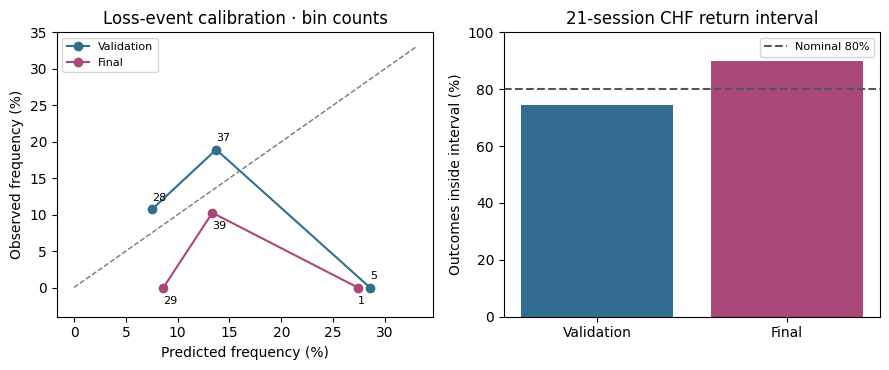

In [82]:
cal12=fc["calibration"]
display(pd.DataFrame({k:{m:cal12[k][m] for m in ["n","events","brier","reference_brier","gain_ci","interval_coverage","width","coverage_ci"]} for k in ["validation","final"]}).T)
print("Admission",cal12["probability_eligible"],cal12["interval_eligible"],"· controls",cal12["controls"])
fig,axes=plt.subplots(1,2,figsize=(9,3.8))
for k,color in [("validation","#316e90"),("final","#aa487a")]:
    bins=pd.DataFrame(cal12[k]["bins"])
    axes[0].plot(100*bins.predicted,100*bins.actual,"o-",label=k.title(),color=color)
    for row in bins.itertuples():
        axes[0].annotate(str(row.n),(100*row.predicted,100*row.actual),xytext=(0,6 if k=="validation" else -12),textcoords="offset points",fontsize=8)
axes[0].plot([0,33],[0,33],"--",color="#777",lw=1)
axes[0].set(xlabel="Predicted frequency (%)",ylabel="Observed frequency (%)",title="Loss-event calibration · bin counts",ylim=(-4,35))
axes[0].legend(fontsize=8)
axes[1].bar(["Validation","Final"],[100*cal12[k]["interval_coverage"] for k in ["validation","final"]],color=["#316e90","#aa487a"])
axes[1].axhline(80,color="#555",ls="--",label="Nominal 80%")
axes[1].set(ylabel="Outcomes inside interval (%)",title="21-session CHF return interval",ylim=(0,100))
axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(fcdir/"calibration.png",dpi=150,bbox_inches="tight")
plt.show()

## 13. Application, portfolio matching and monitoring

Follow the fictional CHF client from the first card to an independently confirmed revision. The public replay recalculates from the published model. The local result uses archived first-close marks. [Launch guide, figures and screenshots](reports/13-application/README.md)

### 13.1 · Integrate five Streamlit screens

- [x] Checked in the project checklist

**Method and tools.** Route the example through the original card bank and confirm the annual risk choice separately. Load the two browser journeys and check their receipts.

**Result.** CHF 35,000 enters the investable sleeve, CHF 15,000 stays in reserve and the client explicitly sets a 12% ceiling. Correcting an answer reopens consent.

In [83]:
from riskmatch_v2.matching.mandate import example_profile, mandate, MARKET_DAY
from riskmatch_v2.risk_review import request
from riskmatch_v2.matching.engine import engine_replay
from riskmatch_v2.matching.ledger import replay_evidence

report13 = Path("reports/13-application")
browser13 = json.loads((report13 / "browser.json").read_text())
client13 = example_profile(Path.cwd())
client13.confirm()
client13.save_risk(request("cap", "investment sleeve", ceiling_pct=12), accept=True, bills="yes", comfort="yes")
mandate13 = mandate(client13, MARKET_DAY)
assert mandate13["capital_chf"] == 35000 and not mandate13["blocked_reason"]
assert all(browser13[d]["oil_revision_version"] == 2 for d in ("mobile", "desktop"))
display(pd.Series({k: mandate13[k] for k in ("capital_chf", "reserve_chf", "goal_chf", "goal_date", "high")}))

capital_chf       35000.0
reserve_chf       15000.0
goal_chf          50000.0
goal_date      2029-10-31
high                 0.12
dtype: object

### 13.2 · Monitor portfolios at the close

- [x] Checked in the project checklist

**Method and tools.** Replay dated prices, FX, whole units, trading fees and external cash flows in disposable SQLite accounts. Reconcile daily values and cumulative time-weighted return with an independent hand calculation.

**Result.** The corrected second close values the account at CHF 979.40. The final account value is CHF 1,139.40 and the flow-neutral return is 5.1385%.

In [84]:
book13 = replay_evidence()
close13 = pd.DataFrame(book13["hand_ledger"]).set_index("day")
assert all(abs(a-b) < .005 for a,b in zip(close13.value, book13["hand_values_chf"]))
assert abs(close13.twr.iloc[-1] - book13["hand_twr"]) < 1e-10
display(close13[["flow_chf","cash","value","session_return","twr","drawdown"]].round(5))

,flow_chf,cash,value,session_return,twr,drawdown
day,,,,,,
2026-10-26,1000.0,399.4,999.4,-0.00060,-0.00060,-0.00060
2026-10-27,-100.0,299.4,979.4,0.08895,0.08829,0.00000
2026-10-28,200.0,499.4,1139.4,-0.03392,0.05138,-0.03392


### 13.3 · Test a targeted portfolio revision

- [x] Checked in the project checklist

**Method and tools.** Reprice the actual positions after a deposit. Compare the two-sided oil shock, fees and modelled goal for keeping and switching on the same close. Recalculate the public tape directly from the published parameters.

**Result.** In both fill simulations the avoided loss from one adverse oil shock is smaller than the transition fee. Goal, savings, horizon and risk edits also have separate controls.

In [85]:
public13 = engine_replay(public_only=True)
tapes13 = json.loads((report13 / "market-replay.json").read_text())
assert abs(public13["after_fee_improvement_chf"] - tapes13["portable"]["after_fee_improvement_chf"]) < 1e-8
display(pd.DataFrame({k: [r["held"]["oil_abs_chf"], r["revision"]["oil_abs_chf"], r["revision"]["fee_chf"], r["after_fee_improvement_chf"]] for k,r in tapes13.items()}, index=["Held shock (CHF)", "Proposed shock (CHF)", "Switch fee (CHF)", "Avoided loss less fee (CHF)"]).round(2))
display(pd.DataFrame(public13["changed_plans"]).loc[["vol","goal_value_chf","goal_gap_chf","goal_required"]])

,local,portable
Held shock (CHF),30.36,18.75
Proposed shock (CHF),14.94,9.27
Switch fee (CHF),16.34,24.57
Avoided loss less fee (CHF),-0.92,-15.09


,Earlier goal,Higher goal,Additional savings,Lower risk cap
vol,0.082859,0.082859,0.082859,0.033166
goal_value_chf,38180.990516,78567.814669,83567.814669,49663.543199
goal_gap_chf,11819.009484,0.0,0.0,336.456801
goal_required,4.181871,0.274257,0.07429,0.112787


### 13.4 · Define how the demo handles client data

- [x] Checked in the project checklist

**Method and tools.** Create two isolated dossiers, check the export, test deletion, and verify the detector against a deliberately contaminated control. Load the release-file and log scan summary.

**Result.** The other account cannot confirm or read the private proposal. Deletion removes the stored versions. Three fixture markers were absent from the inspected release.

In [86]:
audit13 = json.loads((report13 / "ledger-replay.json").read_text())
private13 = ["different_account_rejected", "private_marker_detector_positive_control", "dossier_and_versions_deleted"]
assert all(book13["controls"][key] for key in private13)
assert audit13["release_scan"]["files_checked"] > 0 and audit13["release_scan"]["matches"] == 0
display(pd.Series(audit13["release_scan"], name="Release privacy scan"))

files_checked      263
markers_checked      3
matches              0
tracked_files      254
local_logs           9
Name: Release privacy scan, dtype: int64

### 13.5 · Trigger a review while leaving the decision to the client

- [x] Checked in the project checklist

**Method and tools.** Apply versioned thresholds to drift, drawdown, goal horizon, scheduled withdrawal, client concern and changed mandate.

**Result.** Sub-threshold drift produces no notice. Crossing the thresholds or reporting a concern raises a notice. Only a confirmed draft can book trades.

In [87]:
assert not public13["notices"]["quiet"]
assert "Scheduled withdrawal approaching" in public13["notices"]["near_expense"]
display(pd.Series({k: ", ".join(v) or "No notice" for k,v in public13["notices"].items()}, name="Observed trigger"))

quiet                                       No notice
threshold            Weight drift, Drawdown threshold
near_goal                            Goal approaching
near_expense         Scheduled withdrawal approaching
reported        Client-reported risk, Mandate changed
Name: Observed trigger, dtype: object

### 13.6 · Safely record a simulated revision

- [x] Checked in the project checklist

**Method and tools.** Attempt two confirmations through concurrent SQLite connections, inject a failed write, cancel and restart, change the mandate and delay settlement.

**Result.** Both confirmations obtain version 2. Two movements are booked for the single revision. The interrupted transaction rolls back and the cancelled proposal stays cancelled.

In [88]:
assert book13["confirmation_versions"] == [2,2] and book13["revision_movements"] == 2
assert all(book13["controls"].values())
display(pd.Series(book13["controls"], name="Passed"))
print("Confirmation receipts", book13["confirmation_versions"], "· revision movements", book13["revision_movements"])

different_account_rejected                  True
private_marker_detector_positive_control    True
amended_mandate_rejected                    True
delayed_settlement_rejected                 True
impossible_sale_rejected                    True
stale_mark_rejected                         True
closed_listing_rejected                     True
cancellation_survived_restart               True
write_interruption_rolled_back              True
same_receipt_for_two_confirmations          True
dossier_and_versions_deleted                True
Name: Passed, dtype: bool

Confirmation receipts [2, 2] · revision movements 2


### 13.7 · Build the graphical portfolio comparison screen

- [x] Checked in the project checklist

**Method and tools.** Group rounded capital weights including cash and sum Euler contributions to volatility. Compare the common model quantities used in Plotly and the descriptive tables.

**Result.** The class weights sum to 100%. Risk contributions reconcile to the blend's estimated annual volatility on each execution tape.

In [89]:
for r in tapes13.values():
    assert abs(r["weight_total"] - 1) < 1e-10
    assert abs(r["euler_total"] - r["match"]["vol"]) < 1e-10
display(pd.DataFrame({"Capital weight (%)": pd.Series(public13["classes"])*100,
                      "Annual volatility contribution (pp)": pd.Series(public13["euler"])*100}).round(3))

,Capital weight (%),Annual volatility contribution (pp)
Individual stock,61.441,8.218
CHF cash,38.559,0.000


### 13.8 · Visualize history, scenarios and the revision decision

- [x] Checked in the project checklist

**Method and tools.** Chart the hand-reconciled ledger separately from modelled CHF shocks. Compare feasible choices against the requested range and keep unvalidated forecast weight at zero.

**Result.** Cash flows can raise account value while the flow-neutral strategy return falls. A requested 35–45% band rejects the tested 60/40 allocation. The right panel shows conditional changes under a shock.

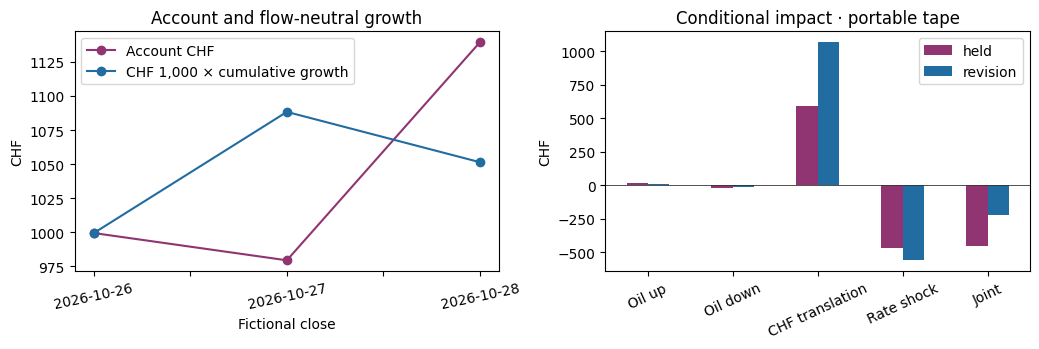

The rounded portfolio falls outside the confirmed volatility band.


In [90]:
import matplotlib.pyplot as plt
assert not public13["outside_band"]["valid"]
fig13, axes13 = plt.subplots(1,2,figsize=(10.5,3.6))
view13 = close13[["value"]].rename(columns={"value":"Account CHF"})
view13["CHF 1,000 × cumulative growth"] = 1000*(1+close13.twr)
view13.plot(ax=axes13[0], marker="o", color=["#913472","#216ca1"], rot=12)
axes13[0].set(xlabel="Fictional close",ylabel="CHF", title="Account and flow-neutral growth")
pd.DataFrame({k: public13[k]["scenarios"] for k in ("held","revision")}).plot.bar(ax=axes13[1],color=["#913472","#216ca1"],rot=25)
axes13[1].axhline(0,color="#333333",lw=.6)
axes13[1].set(title="Conditional impact · portable tape",ylabel="CHF")
fig13.tight_layout()
plt.show()
print(public13["outside_band"]["reason"])

### 13.9 · Design and implement the visual identity

- [x] Checked in the project checklist

**Method and tools.** Inspect the actual desktop and emulated mobile UI, ten captures, narrow portrait layout, landscape rotation and reduced motion. Font files and imagery are served locally.

**Result.** The desktop and phone-emulated runs reached the same confirmation. The heart remained static with reduced motion. Keyboard focus and alternative text labels are retained.

In [91]:
for d in ("desktop", "mobile"):
    test13 = browser13[d]
    assert len(test13["screenshots"]) == 5 and all((report13/file).is_file() for file in test13["screenshots"])
    print(d, test13["viewport"], "· reduced motion", test13["reduced_motion"], "· five screens captured")

desktop {'width': 1440, 'height': 930} · reduced motion False · five screens captured
mobile {'width': 390, 'height': 844} · reduced motion True · five screens captured


### 13.10 · Let clients browse, choose and confirm a portfolio match

- [x] Checked in the project checklist

**Method and tools.** Cancel a single-option draft, inspect an optimizer suggestion and confirm a manually entered 60/40 blend. Recalculate Sharpe, return and minimum-risk suggestions on the constrained grid.

**Result.** Both browser runs saved the chosen blend as version 1. Suggested source weights depend on the criterion and on prices after whole-unit rounding.

In [92]:
assert all(browser13[d]["single_choice_cancelled"] and browser13[d]["matched_version"] == 1 for d in ("desktop","mobile"))
display(pd.DataFrame({k: {**r["source_shares"], "Estimated net return (%)":100*r["net"], "Annual volatility (%)":100*r["vol"],"Entry fee (CHF)":r["fee_chf"]} for k,r in public13["suggested"].items()}).T.round(3))

,Return,Diversification,Estimated net return (%),Annual volatility (%),Entry fee (CHF)
Sharpe,0.9,0.1,32.628,9.153,24.682
Return,0.9,0.1,32.628,9.153,24.682
Minimum risk,0.1,0.9,25.427,7.409,18.420


### 13.11 · Monitor and revise a blended allocation

- [x] Checked in the project checklist

**Method and tools.** Keep the booked source shares and aggregate unit positions, roll the close, deposit CHF 1,000 and open the revision from the current holdings. Compare both tapes and reconcile the selected revision.

**Result.** The local match holds 195 positions at 10.56% estimated volatility. The portable tape buys different whole units. Both browser runs separately confirmed version 2 after the review.

In [93]:
assert public13["match"]["source_shares"] == {"Return":.6,"Diversification":.4}
assert all(browser13[d]["booked_deposit_chf"] == 1000 for d in ("desktop","mobile"))
display(pd.DataFrame({k:{"Entries":r["match"]["positions"],"Opening fee (CHF)":r["match"]["fee_chf"],"Cash held (CHF)":r["match"]["cash_chf"],"Annual volatility (%)":100*r["match"]["vol"],"Flow (CHF)":r["contribution_chf"],"Proposed shares":r["revision"]["source_shares"]} for k,r in tapes13.items()}).T)

,Entries,Opening fee (CHF),Cash held (CHF),Annual volatility (%),Flow (CHF),Proposed shares
local,195,26.363535,8610.101155,10.559114,1000.0,"{'Diversification': 0.25, 'Hedge': 0.75}"
portable,103,21.491109,13487.399891,8.218081,1000.0,"{'Hedge': 0.75, '60/40 benchmark': 0.25}"


## Client studio · From a swipe to whole positions

The current application replaces the original visual prototype. One financial brief establishes the investable sleeve. Behavioural answers infer a willingness band independently of financial capacity. The full-universe solver constructs several strategies, the client selects and combines them, and the ledger keeps the confirmed positions. This example replays the fictional client used by the desktop and mobile tests. [Studio guide and screenshots](reports/studio/README.md) · [Allocation method](reports/studio/ALLOCATION.md)

The initial brief requires five fields. Help bubbles explain each one. Savings interest, desired investment return and exclusions sit under Optional preferences. Previously saved spending remains editable. The dedicated Chevron filter remains editable on saved profiles that used it.

The reserve and the investment sleeve are projected separately. The example uses a 1% annual CHF savings assumption and displays the manual split in francs.

The lagoon background continues behind translucent navy panels on desktop and mobile. [Desktop capture](reports/studio/glass-desktop.jpg) · [Mobile capture](reports/studio/glass-mobile.jpg)

The local studio opens a named save selector after the intro. A four-digit code unlocks a saved dossier. The browser replay requires that code again after reloading.

The goal comparison displays the desired return, the return required by the dated target and the highest estimated net return among valid matches. An illustrative minimum-volatility solve relaxes the personal risk limits and checks whole positions and fees before reporting the goal scenario. [Method](reports/studio/ALLOCATION.md#goal-comparison)

[Étude du questionnaire en français](reports/studio/ETUDE_QUESTIONNAIRE_FR.md) · 26 cards, their branching conditions and their effects on the current score.

The studio uses a loop of six original jazz pieces across all screens. Browser checks cover the longer intro, steady header during right swipes and lower volume during matches. [Sound and navigation](reports/studio/README.md#sound-and-navigation)

In [94]:
from pathlib import Path
from tempfile import TemporaryDirectory
import json
import pandas as pd
from IPython.display import display
from riskmatch_v2.studio import dispatch
from riskmatch_v2.studio_profile import deck

studio_facts = {"capital":50000, "protected":15000, "loss":15000, "goal":55000,
                "due":"2030-10-30", "target":"5", "reserve_rate":"1"}
studio_yes = set("C01 G00 T01 G01 G03 L00 L01 L02 L03 L04 D01 D03 H01 S01".split())
studio_answers = {}
while pending := [c["id"] for c in deck(studio_answers)[0] if c["id"] not in studio_answers]:
    key = pending[0]
    studio_answers[key] = "yes" if key in studio_yes else "no"

with TemporaryDirectory() as temporary_studio:
    def studio_call(action, data):
        return dispatch(action, data, Path(temporary_studio))
    profile = studio_call("calibrate", {"facts":studio_facts, "answers":studio_answers})
    studio_id = {key:profile[key] for key in ("token","version")}
    result = studio_call("candidates", studio_id)
    choices = result["plans"]
    goal_compare = result["goal_comparison"]
    assert goal_compare["scenario"]["goal_value_chf"] >= studio_facts["goal"]
    display(pd.DataFrame([{"Desired annual %": round(100*goal_compare["desired"], 2),
                           "Required annual %": round(100*goal_compare["required"], 2),
                           "Goal scenario volatility %": round(100*goal_compare["scenario"]["vol"], 2),
                           "Highest compatible estimate %": round(100*goal_compare["compatible"]["net"], 2)}]))
    valid = [row["id"] for row in choices if row["valid"]][:2]
    assert len(valid) == 2 and profile["profile"]["score"] == 44
    request = studio_id | {"revision":result["revision"], "ids":valid}
    manual = studio_call("blend", request | {"weights":[.6,.4]})["plan"]
    suggested = studio_call("blend", request)["plan"]
    draft = studio_call("draft", request)
    booked = studio_call("confirm", studio_id | {"draft":draft["draft"]})["tracking"]
    advanced = studio_call("advance", studio_id | {"day":booked["day"]})
    print(f'{len(studio_answers)} cards · willingness {profile["profile"]["score"]}/100 · {profile["profile"]["band"]}')
    print(f'{choices[0]["universe"]:,} eligible · suggested {suggested["parts"]} · manual {manual["parts"]}')
    assert manual["capital_chf"] == 35000 and manual["reserve_at_goal_chf"] > 15000
    print(f'CHF reserve at goal at 1%: {manual["reserve_at_goal_chf"]:,.2f}')
    print({name: round(share * manual["capital_chf"], 2) for name, share in manual["parts"].items()})
    print(f'{booked["positions"]} booked positions · {advanced["day"]} · CHF {advanced["value"]:,.2f}')
    display(pd.DataFrame([{"Strategy":p["name"], "Pass":p["valid"], "Positions":p["positions"],
                           "Net model %":round(100*p["net"],2), "Volatility %":round(100*p["vol"],2),
                           "Tested loss CHF":round(p["tested_loss_chf"]), "Score":p["score"]} for p in choices]))


,Desired annual %,Required annual %,Goal scenario volatility %,Highest compatible estimate %
0,5.0,3.0,1.1,42.88


22 cards · willingness 44/100 · Moderate
3,322 eligible · suggested {'return': 0.8, 'robust': 0.2} · manual {'return': 0.6, 'robust': 0.4}
CHF reserve at goal at 1%: 15,609.06
{'return': 21000.0, 'robust': 14000.0}
114 booked positions · 2026-11-02 · CHF 35,455.63


,Strategy,Pass,Positions,Net model %,Volatility %,Tested loss CHF,Score
0,Return seeker,True,113,42.69,11.92,8017,80.0
1,All-weather,True,114,42.88,11.98,8157,79.7
2,Spread the risk,True,207,40.82,11.97,8115,79.8
3,Shock shelter,True,102,36.06,11.98,74,95.1
4,The classic,True,2,8.51,11.38,4988,71.5


### Library and live monitoring coverage

Read the measured coverage by asset and horizon from the release. The browser receipts cover both viewport sizes and both entry points. The audio replay covers immediate autoplay and automatic recovery on ordinary interaction. Both keep the idle lagoon open and reserve the splash for Start. The swipe replay verifies the chime and clap with continuing music. A live price provider has yet to be connected. The return estimates shown above use the historical model, and the portfolio account uses synthetic closes. [Library coverage](reports/studio/library-coverage.json) · [Browser evidence](reports/studio/browser-check.json)

In [95]:
studio_report = Path("reports/studio")
coverage = json.loads((studio_report/"library-coverage.json").read_text())
browser_receipt = pd.DataFrame(json.loads((studio_report/"browser-check.json").read_text()))
assert coverage["model_eligible"] == choices[0]["universe"]
display(pd.Series(coverage["complete_monthly_windows"], name="Instruments with complete observations"))
assert (browser_receipt["cherry_transitions"] == browser_receipt["answered"] + 2).all()
assert (browser_receipt["swipe_sounds"] == browser_receipt["cherry_transitions"]).all()
assert (browser_receipt["jazz_pauses_during_cards"] == 0).all()
assert browser_receipt.pin_required_after_reload.all()
display(browser_receipt)

interaction_checks = pd.DataFrame(json.loads((studio_report/"interaction-check.json").read_text()))
assert len(interaction_checks) == 4 and interaction_checks.select_dtypes("bool").all().all()
assert set(interaction_checks.idle_music_start) == {"autoplay", "gesture"}
assert interaction_checks.simple_brief_and_help.all()
display(interaction_checks)

1Y     3357
3Y     3088
5Y     2844
10Y    1989
Name: Instruments with complete observations, dtype: int64

,device,answered,cherry_transitions,swipe_sounds,jazz_pauses_during_cards,reduced_motion,profile,manual_and_suggested_blend,reserve_projection_and_chf_split,confirmed,pin_required_after_reload,goal_comparison,soundtrack_and_stable_swipes,simulated_closes,cash_deposit_chf
0,desktop,22,24,24,0,False,Moderate,True,True,True,True,True,True,2,100
1,phone,22,24,24,0,True,Moderate,True,True,True,True,True,True,2,100


,entry,input,idle_music_start,submit_reached,simple_brief_and_help,jazz_and_cues_played,music_before_start,title_cues_waited_for_start,mute_persisted,continued_on_visibility_change
0,Standalone,Mouse wheel,autoplay,True,True,True,True,True,True,True
1,Streamlit,Mouse wheel,autoplay,True,True,True,True,True,True,True
2,Standalone,Touch swipe,gesture,True,True,True,True,True,True,True
3,Streamlit,Touch swipe,autoplay,True,True,True,True,True,True,True


### Questionnaire calibration pilot

This research prototype tests an 18-card bank with conditional prompts and eight descriptive categories. The deployed studio remains on its current calibration. The count covers first-pass answer histories, with no probability assigned to a history. [French audit, full question matrix and interpretation](reports/studio/CALIBRATION_QUESTIONNAIRE_FR.md)

In [96]:
from riskmatch_v2.questionnaire_pilot import assess as assess_pilot, count_routes, next_card
from IPython.display import display
import pandas as pd

pilot_counts = count_routes()
assert sum(pilot_counts.values()) == 56_629_125
display(pd.Series(pilot_counts, name="First-pass histories").rename_axis("Cards shown"))

pilot_examples = {
    "Measured adjustment": {"C01":"skip", "C02":"yes", "G01":"no", "G02":"yes", "D02":"no"},
    "Claims risk comfort but would exit in both declines": {"T02":"no", "G01":"no", "G02":"no", "D01":"no", "D02":"no"},
    "Contradictory choices": {"G01":"yes", "G02":"no", "D01":"no", "F02":"no"},
}
pilot_results = []
for description, overrides in pilot_examples.items():
    responses = {}
    while candidate := next_card(responses)[0]:
        responses[candidate.id] = overrides.get(candidate.id, "yes")
    report = assess_pilot(responses)
    pilot_results.append({"Case":description, **report["scores"], "Overall":report["willingness"], "Status":report["status"]})
assert [row["Overall"] for row in pilot_results] == [44, 67, None]
display(pd.DataFrame(pilot_results))


Cards shown
9          648
10       16524
11       23328
14       26244
15      997272
16     9861183
17    25863462
18    19840464
Name: First-pass histories, dtype: int64

,Case,comprehension,tolerance,arbitrage,maintien,reticence_pertes,concordance_cadrage,souplesse,suivi_frequent,Overall,Status
0,Measured adjustment,100,50,33.0,50.0,0,100,100,100,44.0,interpretable
1,Claims risk comfort but would exit in both dec...,100,100,100.0,0.0,0,100,100,100,67.0,a_confirmer
2,Contradictory choices,100,50,NaN,NaN,0,0,100,100,NaN,a_revoir


## 14. Final verification and delivery

A separate GitHub checkout replays the public demonstration. A second checkout tests the archived first close and refits the full-universe allocation from saved model inputs. [Release report and launch commands](reports/14-delivery/README.md)

### 14.1 · Reproduce the release in a clean checkout

- [x] Checked in the project checklist

**Method and tools.** Rebuild two fictional card routes and their confirmed CHF mandates, then book the match and oil revision on the public tape. Compare the private archive’s eligible identifiers with the actual solver inputs.

**Result.** Both dossiers reach version 2. The private full-universe solver receives all 3,322 eligible instruments; 329 distinct holdings appear across the five source strategies.

,screened,eligible,blocked,selected_union
Individual stock,3824,3255,569,326
Treasury ETF,2,2,0,1
Equity ETF,10,10,0,1
Gold (GLD),1,1,0,1
Direct Treasury,65,54,11,0


,opening_chf,goal_date,required_annual_rate,rounded_positions,entry_fee_chf,final_portfolio_versions
A,35000.0,2029-10-31,0.126095,103,21.491109,2
B,50000.0,2034-10-31,0.086218,124,33.939063,2


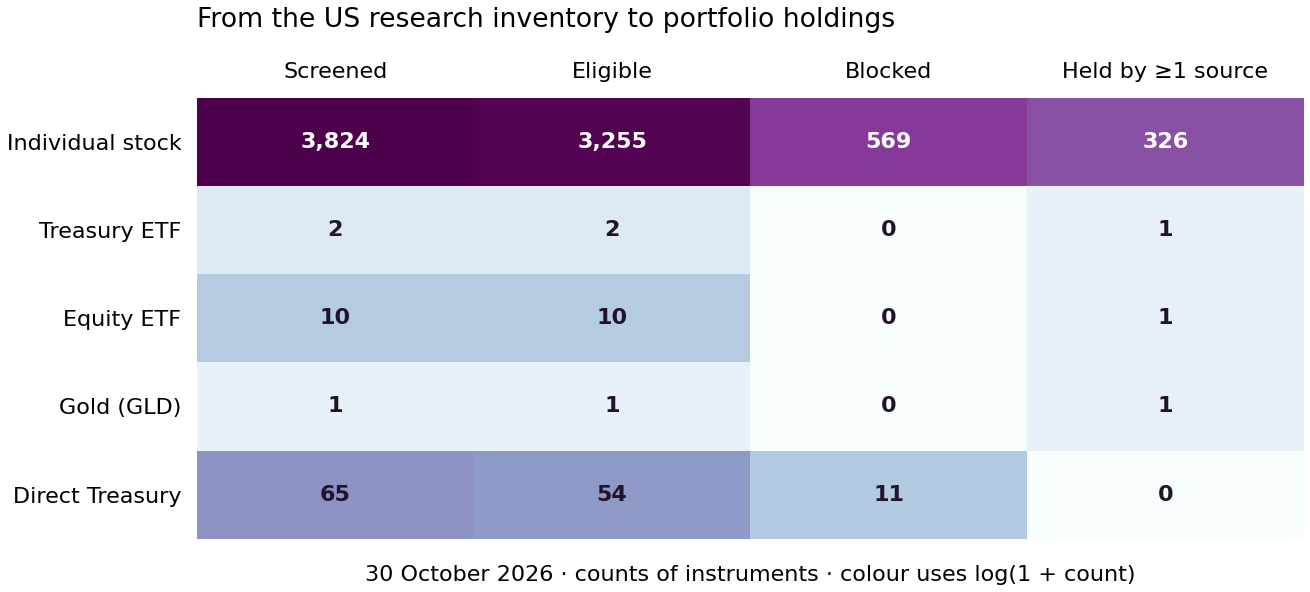

In [97]:
import runpy
release14 = Path("reports/14-delivery")
replay14 = runpy.run_path(str(release14 / "replay.py"))["verify"]("public")
private14 = json.loads((release14 / "private-replay.json").read_text())
solver14 = private14["full_solver"]
assert solver14["eligible_identifier_sha256"] == solver14["solver_input_identifier_sha256"]
assert solver14["offered"] == 3322 and solver14["held_above_1e_minus_7"] == 147
display(pd.DataFrame(replay14["classes"]).T[["screened","eligible","blocked","selected_union"]])
display(pd.DataFrame(replay14["clients"]).T[["opening_chf","goal_date","required_annual_rate","rounded_positions","entry_fee_chf","final_portfolio_versions"]])
from IPython.display import Image
display(Image(filename=str(release14/"asset-coverage.png"), width=680))

### 14.2 · Prepare the final evidence package

- [x] Checked in the project checklist

**Method and tools.** Enumerate the tracked release and recompute SHA-256 for each fingerprinted numerical input. The source register identifies public outputs, local archives, access evidence and limitations.

**Result.** The demo includes the authored fixtures, model and sample execution algorithm. Vendor extracts and saved accounts remain local. [Sources and rights](reports/14-delivery/DATA.md) · [File inventory](reports/14-delivery/public-files.json)

In [98]:
import hashlib
manifest14 = json.loads((release14 / "public-files.json").read_text())
assert all(Path(path).is_file() for path in manifest14["files"])
assert all(hashlib.sha256(Path(path).read_bytes()).hexdigest() == digest for path,digest in manifest14["input_sha256"].items())
print(f'{manifest14["tracked_count"]} release files · {len(manifest14["input_sha256"])} inputs matched SHA-256')
display(pd.Series(manifest14["files"]).value_counts().rename("Tracked files"))

330 release files · 7 inputs matched SHA-256


software, configuration and environment                    152
parameters, metadata and research evidence                  72
research chart, fictional screenshot or project artwork     55
documentation and notebooks                                 35
font and bundled licence                                     6
fictional research cases                                     4
paired derived predictions and outcomes                      3
original studio music and sound effects                      2
synthetic fixture                                            1
Name: Tracked files, dtype: int64

### 14.3 · Assess intraday monitoring

- [ ] Open in the project checklist

**Method and tools.** Request the official IBM sample, measure HTTP time and bar age independently, check the XNYS regular-session grid and examine CHF price and display entitlements.

**Result.** The January 2009 session contains all 78 regular five-minute bars. The November sample was 66.32 hours old on receipt. Both portfolio screens retain dated closing valuations. A verified intraday portfolio and FX feed remains open. [Timing evidence](reports/14-delivery/intraday.json)

In [99]:
intraday14 = json.loads((release14 / "intraday.json").read_text())
sample14 = intraday14["compact"]
session14 = intraday14["historical"]["session_replay"]
assert session14["expected_5min_slots"] == session14["observed_slots"] == 78
assert not intraday14["account_live_enabled"]
display(pd.Series({"HTTP response (seconds)":sample14["http_seconds"],"Newest sample stamp":sample14["latest_bar_stamp"],"Received (UTC)":sample14["received_utc"],"Age (hours)":round(sample14["seconds_since_sample_stamp"]/3600,2),"Historical session":session14["session"], "Verified intraday CHF pairs":intraday14["validated_intraday_chf_pairs"]}))

HTTP response (seconds)                                    0.54
Newest sample stamp                   2026-11-20T19:55:00-05:00
Received (UTC)                 2026-11-23T19:14:07.030860+00:00
Age (hours)                                               66.32
Historical session                                   2009-01-30
Verified intraday CHF pairs                                   0
dtype: object

### 14.4 · Verify the delivered scope before publication

- [x] Checked in the project checklist

**Method and tools.** Cross-check the requirements matrix, both browser receipts, the numerical model, flow ledger and remaining checklist items on the release.

**Result.** Both delivery modes passed the tests and browser walkthroughs. Earlier research qualifications and the intraday extension remain explicit. [Acceptance cases](reports/14-delivery/README.md) · [Environment and browser checks](reports/14-delivery/verification.json)

In [100]:
qa14 = json.loads((release14 / "verification.json").read_text())
for mode14, record14 in qa14["modes"].items():
    assert record14["unit_tests"] == 105 and record14["unit_skips"] == 0
    for device14 in ("mobile","desktop"):
        assert record14["browser"][device14]["exported_and_reopened_version"] == 2
    print(mode14, "·", record14["unit_tests"], "unit tests · card and match journeys verified")
remaining14 = [k for k,v in tasks.items() if v == " "]
print(f"{len(tasks)-len(remaining14)} of {len(tasks)} checklist items checked; open: " + ", ".join(remaining14))

public · 105 unit tests · card and match journeys verified
private · 105 unit tests · card and match journeys verified
81 of 86 checklist items checked; open: 6.3, 6.4, 6.5, 9.2, 14.3


## Studio update · From portfolio answers to volatility

[Studio language and bilingual navigation](reports/studio/README.md#studio-language) · [Bilingual questionnaire review](reports/studio/ETUDE_QUESTIONNAIRE_FR.md#relecture-bilingue-du-studio). The studio shows the three fictional guaranteed-versus-uncertain exercises in sequence after comprehension. Review and permission prompts are archived. The behavioural score describes the profile. Two fictional CHF portfolio comparisons and a conditional follow-up bound risk aversion in a mean–variance model. The studio derives the volatility zone from allocations checked after whole-unit rounding. The example uses the dated historical inputs, can extrapolate beyond the comparison cards, and does not validate real preferences. [Questionnaire and thresholds](reports/studio/ETUDE_QUESTIONNAIRE_FR.md#vérification-sur-des-choix-de-portefeuille) · [Browser replay](reports/studio/volatility-browser-check.json)

In [101]:
from pathlib import Path
from tempfile import TemporaryDirectory

from riskmatch_v2.studio import dispatch
from riskmatch_v2.studio_profile import deck

example_yes = {"C01", "T01", "G00", "G01", "G03", "D01", "D03"}
example_answers = {}
while pending := [card["id"] for card in deck(example_answers)[0] if card["id"] not in example_answers]:
    key = pending[0]
    example_answers[key] = "yes" if key in example_yes else "no"

scenario_facts = dict(capital=50000, protected=15000, goal=55000, due="2030-10-30", loss=15000)
score_results = set()
with TemporaryDirectory() as folder:
    for v1, v2 in [("wider", "lower"), ("lower", "wider")]:
        raw = {
            "facts": scenario_facts,
            "answers": example_answers | {"V01": v1, "V02": v2},
            "derive_volatility": True,
        }
        calibrated = dispatch("calibrate", raw, Path(folder))
        result = calibrated["profile"]
        aversion, zone = result["aversion"], result["volatility_zone"]
        print(f'V01 {v1}, V02 {v2} · behaviour score {result["score"]}/100')
        score_results.add(result["score"])
        if zone["state"] == "estimated":
            print(f'γ {aversion["gamma_low"]:.2f}–{aversion["gamma_high"]:.2f} · annual volatility {zone["low"]:.1%}–{zone["high"]:.1%}')
            matches = dispatch("candidates", {k: calibrated[k] for k in ("token", "version")}, Path(folder))
            eligible = [plan for plan in matches["plans"] if plan["valid"]]
            assert any(plan["id"] == "preference" for plan in eligible)
            assert all(plan["vol"] <= zone["high"] + 1e-8 for plan in eligible)
        else:
            assert zone["state"] == "needs_confirmation"
            print("Needs confirmation · CHF cash search")
assert len(score_results) == 1

V01 wider, V02 lower · behaviour score 44/100
γ 1.67–4.17 · annual volatility 26.8%–32.4%
V01 lower, V02 wider · behaviour score 44/100
Needs confirmation · CHF cash search
